In [1]:
# ============================================================
# CELL 1 — Setup, Config, Ollama check, dataset discovery
# ============================================================
import os, glob, time, warnings, re, json, pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report,
                             precision_recall_fscore_support)
import matplotlib.pyplot as plt
import scipy.signal as sg
import gradio as gr
import joblib
from collections import Counter

warnings.filterwarnings("ignore")

# ----------------- CONFIG -----------------
SAM40_ROOT_DIR = r"C:\Users\lagis\Downloads\SAM40"

FS              = 128
EPOCH_SEC       = 4
OVERLAP         = 0.5
LABELS          = {"Relax": 0, "Stroop": 1}
CLASS_NAMES     = ["Relax", "Stroop"]

CH_NAMES = ["Fp1","AF3","F3","F7","FC5","FC1","C3","T7","CP5","CP1","P3","P7","PO3","O1","Oz","Pz",
            "Fp2","AF4","Fz","F4","F8","FC6","FC2","Cz","C4","T8","CP6","CP2","P4","P8","PO4","O2"]
CH = {n: i for i, n in enumerate(CH_NAMES)}

BANDS         = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}
CONCEPT_NAMES = ["TAR", "FAA", "EI", "FMtheta", "HAI", "PAC"]

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS          = 40
BATCH_SIZE      = 32
LR              = 3e-4
WEIGHT_DECAY    = 1e-2
PATIENCE        = 12
LABEL_SMOOTHING = 0.05
EMB_SIZE        = 64
LAMBDA_CONCEPT  = 0.5

AUG_SHIFT_SEC   = 0.5
AUG_NOISE       = 0.10
AUG_AMP_JITTER  = 0.10
AUG_CH_DROP     = 0.05

RUN_BASELINE_CV = True

OLLAMA_LLM   = "llama3.2"
OLLAMA_EMBED = "nomic-embed-text"
HELPLINE_TEXT = ("your local emergency number, or a mental-health helpline in your country "
                 "(e.g. in India: Tele-MANAS 14416 — please verify for your location)")

np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
print(f"EPOCH_SEC={EPOCH_SEC}s  EPOCHS={EPOCHS}  BATCH={BATCH_SIZE}  LR={LR}  PATIENCE={PATIENCE}")
print("Split: by SUBJECT (new-person accuracy)")

try:
    import ollama
    _ = ollama.list()
    OLLAMA_OK = True
    print("✓ Ollama is running.")
except Exception as e:
    OLLAMA_OK = False
    print("⚠ Ollama not reachable — LLM output will fall back to KB snippets.")
    print("  Reason:", str(e)[:160])

def find_subfolder(root, keyword):
    if not os.path.isdir(root):
        raise SystemExit(f"ERROR: root folder does not exist: {root}")
    matches = [d for d in os.listdir(root)
               if os.path.isdir(os.path.join(root, d)) and keyword.lower() in d.lower()]
    return os.path.join(root, matches[0]) if matches else None

def find_data_files(folder):
    files = []
    for root, _, names in os.walk(folder):
        for n in names:
            low = n.lower()
            if low.endswith((".csv", ".xlsx", ".xls")):
                files.append(os.path.join(root, n))
            elif "." not in n and "_sub_" in low:
                files.append(os.path.join(root, n))
    return sorted(files)

relax_folder  = find_subfolder(SAM40_ROOT_DIR, "relax")
stroop_folder = find_subfolder(SAM40_ROOT_DIR, "stroop")
if relax_folder is None or stroop_folder is None:
    raise SystemExit(f"Relax/Stroop folders missing under {SAM40_ROOT_DIR}")

print("\nRelax  folder:", relax_folder)
print("Stroop folder:", stroop_folder)

relax_files  = find_data_files(relax_folder)
stroop_files = find_data_files(stroop_folder)
print(f"  → {len(relax_files)}  Relax  files")
print(f"  → {len(stroop_files)} Stroop files")

Device: cpu
EPOCH_SEC=4s  EPOCHS=40  BATCH=32  LR=0.0003  PATIENCE=12
Split: by SUBJECT (new-person accuracy)
✓ Ollama is running.

Relax  folder: C:\Users\lagis\Downloads\SAM40\Relax-20231211T181913Z-001
Stroop folder: C:\Users\lagis\Downloads\SAM40\Stroop-20231211T181911Z-001
  → 40  Relax  files
  → 40 Stroop files


In [2]:
# ============================================================
# CELL 2 — SAM 40 → X / C / Y / G
# ============================================================

FRONTAL  = [CH[c] for c in ["Fp1","AF3","F3","F7","Fz","F4","F8","AF4","Fp2"]]
PARIETAL = [CH[c] for c in ["P3","Pz","P4"]]
PAIRS    = [("F3","F4"),("C3","C4"),("P3","P4"),("O1","O2"),("F7","F8"),("T7","T8")]
_sos_t   = sg.butter(4, [4, 8],   "bandpass", fs=FS, output="sos")
_sos_g   = sg.butter(4, [30, 45], "bandpass", fs=FS, output="sos")

def band_power(ep, lo, hi):
    T    = ep.shape[-1]
    spec = np.abs(np.fft.rfft(ep * np.hanning(T), axis=-1)) ** 2
    fr   = np.fft.rfftfreq(T, 1 / FS)
    m    = (fr >= lo) & (fr < hi)
    return spec[..., m].sum(-1) + 1e-12

def pac_mvl(ep):
    x   = ep[:, CH["Fz"], :]
    ph  = np.angle(sg.hilbert(sg.sosfiltfilt(_sos_t, x, axis=-1), axis=-1))
    amp = np.abs(sg.hilbert(sg.sosfiltfilt(_sos_g, x, axis=-1), axis=-1))
    return np.abs((amp * np.exp(1j * ph)).mean(-1)) / (np.sqrt((amp ** 2).mean(-1)) + 1e-12)

def compute_concepts(ep):
    ep = ep.astype(np.float64)
    P  = {b: band_power(ep, *BANDS[b]) for b in BANDS}
    th, al, be = P["theta"], P["alpha"], P["beta"]
    tot = sum(P[b] for b in ["theta", "alpha", "beta", "gamma"])
    TAR = np.log((th[:, FRONTAL].mean(1) + 1e-9) / (al[:, FRONTAL].mean(1) + 1e-9))
    FAA = np.log(al[:, CH["F4"]] + 1e-9) - np.log(al[:, CH["F3"]] + 1e-9)
    fp  = FRONTAL + PARIETAL
    EI  = be[:, fp].mean(1) / (al[:, fp].mean(1) + th[:, fp].mean(1) + 1e-9)
    FMT = np.log(th[:, CH["Fz"]] + 1e-9) - np.log(tot[:, CH["Fz"]] + 1e-9)
    HAI = np.mean([(al[:, CH[l]] - al[:, CH[r]]) /
                   (al[:, CH[l]] + al[:, CH[r]] + 1e-9) for l, r in PAIRS], axis=0)
    PAC = pac_mvl(ep)
    return np.nan_to_num(np.stack([TAR, FAA, EI, FMT, HAI, PAC], 1).astype(np.float32))

def epoch_signal(x):
    L    = EPOCH_SEC * FS
    step = int(L * (1 - OVERLAP))
    if x.shape[1] < L:
        return np.array([])
    return np.stack([x[:, s:s+L] for s in range(0, x.shape[1] - L + 1, step)])

def load_one_sam40_csv(path, target_ch=32):
    df = pd.read_csv(path)
    for c in list(df.columns):
        cl = str(c).strip().lower()
        if cl.startswith("unnamed") or cl in ("index","time_sec","time",
                                               "timestamp","label","class","target"):
            df = df.drop(columns=[c])
    num = df.select_dtypes(include=np.number).dropna(axis=1, how="all")
    if num.shape[1] < target_ch:
        raise ValueError(f"only {num.shape[1]} numeric columns (need ≥ {target_ch})")
    if num.shape[1] > target_ch:
        pref = [c for c in num.columns if str(c).lower().startswith(("ch","eeg"))]
        num  = num[pref[:target_ch]] if len(pref) >= target_ch else num.iloc[:, :target_ch]
    x = num.values.T.astype(np.float64)
    return np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

CACHE_FILE = f"sam40_binary_processed_ep{EPOCH_SEC}.npz"

if os.path.exists(CACHE_FILE):
    print(f"Loading cache: {CACHE_FILE}")
    z = np.load(CACHE_FILE)
    X, C, Y, G = z["X"], z["C"], z["Y"], z["G"]
else:
    print(f"Processing SAM 40 (EPOCH_SEC={EPOCH_SEC}s)...\n")
    all_X, all_C, all_Y, all_G = [], [], [], []
    skipped = []
    folders = {relax_folder: "Relax", stroop_folder: "Stroop"}

    for folder, label_name in folders.items():
        files = find_data_files(folder)
        print(f"→ {label_name}  ({len(files)} files)")
        for i, f in enumerate(files):
            try:
                eeg = load_one_sam40_csv(f, target_ch=32)
                if eeg.shape[1] < EPOCH_SEC * FS:
                    raise ValueError(f"too short ({eeg.shape[1]} samples)")
                eeg = sg.sosfiltfilt(
                    sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos"),
                    eeg, axis=1)
                eps = epoch_signal(eeg)
                if eps.size == 0:
                    raise ValueError("no epochs")
                concepts = compute_concepts(eps)
                eps_norm = (eps - eps.mean(-1, keepdims=True)) / \
                           (eps.std(-1, keepdims=True) + 1e-6)
                all_X.append(eps_norm.astype(np.float32))
                all_C.append(concepts)
                all_Y.append(np.full(len(eps), LABELS[label_name], dtype=np.int64))
                all_G.append(np.full(len(eps), i, dtype=np.int64))
                if (i + 1) % 10 == 0:
                    print(f"   {i+1}/{len(files)}  (epochs so far: "
                          f"{sum(a.shape[0] for a in all_X)})")
            except Exception as e:
                skipped.append((label_name, os.path.basename(f), str(e)))
                print(f"   SKIP {os.path.basename(f)}: {e}")

    if not all_X:
        for lb, fn, r in skipped[:10]:
            print(f"  [{lb}] {fn}: {r}")
        raise RuntimeError("Nothing processed.")

    X = np.concatenate(all_X); C = np.concatenate(all_C)
    Y = np.concatenate(all_Y); G = np.concatenate(all_G)

    print(f"\n✓ X {X.shape} | C {C.shape} | Y {Y.shape} | G {G.shape}")
    print(f"  Class counts: {dict(zip(CLASS_NAMES, np.bincount(Y, minlength=2)))}")
    if skipped:
        print(f"  {len(skipped)} skipped.")
    np.savez_compressed(CACHE_FILE, X=X, C=C, Y=Y, G=G)
    print(f"  Saved: {CACHE_FILE}")

Loading cache: sam40_binary_processed_ep4.npz


In [3]:
# ============================================================
# CELL 3 — Split + DataLoaders  (+ subject-centered concepts)
# ============================================================
groups = np.unique(G)
print(f"Groups (recordings): {len(groups)}")

group_class = np.array([Y[G == g][0] for g in groups])

train_g, temp_g, train_c, temp_c = train_test_split(
    groups, group_class, test_size=0.30, stratify=group_class, random_state=SEED)
val_g,   test_g = train_test_split(temp_g, test_size=0.50,
                                   stratify=temp_c, random_state=SEED)

train_mask = np.isin(G, train_g)
val_mask   = np.isin(G, val_g)
test_mask  = np.isin(G, test_g)

REC = G * 2 + Y
print(f"Subjects | train={len(train_g)}  val={len(val_g)}  test={len(test_g)}")
print(f"Windows | train={train_mask.sum()}  val={val_mask.sum()}  test={test_mask.sum()}")

# ---- concept normalization from TRAIN only ----
c_mu = C[train_mask].mean(0)
c_sd = C[train_mask].std(0) + 1e-8
C_z  = ((C - c_mu) / c_sd).astype(np.float32)

# ---- NEW: subject-centered concepts (person-relative; used by the LR in ensemble) ----
C_subj = C.copy()
for g in np.unique(G):
    m = G == g
    if m.sum() > 1:
        C_subj[m] -= C_subj[m].mean(0)
c_mu2 = C_subj[train_mask].mean(0)
c_sd2 = C_subj[train_mask].std(0) + 1e-8
C_subj_z = ((C_subj - c_mu2) / c_sd2).astype(np.float32)

# ---- class weights ----
counts  = np.bincount(Y[train_mask], minlength=2).clip(min=1)
class_w = torch.tensor(len(Y[train_mask]) / (2 * counts),
                       dtype=torch.float32).to(DEVICE)
print("Class weights:", class_w.cpu().numpy().round(3))

def make_dl(mask, shuffle):
    ds = TensorDataset(
        torch.from_numpy(X[mask]),
        torch.from_numpy(Y[mask]).long(),
        torch.from_numpy(C_z[mask]))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)

train_loader = make_dl(train_mask, True)
val_loader   = make_dl(val_mask,   False)
test_loader  = make_dl(test_mask,  False)

print(f"Batches | train={len(train_loader)}  val={len(val_loader)}  test={len(test_loader)}")

xb, yb, cb = next(iter(train_loader))
print(f"Sample batch: X {tuple(xb.shape)}  Y {tuple(yb.shape)}  C {tuple(cb.shape)}")

Groups (recordings): 40
Subjects | train=28  val=6  test=6
Windows | train=2016  val=432  test=432
Class weights: [1. 1.]
Batches | train=63  val=14  test=14
Sample batch: X (32, 32, 512)  Y (32,)  C (32, 6)


In [4]:
# ============================================================
# CELL 4 — CB-EEGNet
# ============================================================
class BandFilterBank(nn.Module):
    def __init__(self, bands, fs, numtaps=129):
        super().__init__()
        k = np.stack([sg.firwin(numtaps, [lo, hi], pass_zero=False, fs=fs)
                      for lo, hi in bands.values()])
        self.register_buffer("k", torch.tensor(k, dtype=torch.float32).unsqueeze(1))
        self.pad = numtaps // 2
    def forward(self, x):
        B, C, T = x.shape
        y = F.conv1d(x.reshape(B*C, 1, T), self.k, padding=self.pad)
        return y.reshape(B, C, -1, T).permute(0, 2, 1, 3)

class BandExpert(nn.Module):
    def __init__(self, n_ch=32, T=EPOCH_SEC*FS,
                 F1=16, D=2, F2=32, emb=EMB_SIZE, drop=0.4):
        super().__init__()
        self.temporal = nn.Sequential(
            nn.Conv2d(1, F1, (1, 33), padding=(0, 16), bias=False),
            nn.BatchNorm2d(F1))
        self.spatial = nn.Sequential(
            nn.Conv2d(F1, F1*D, (n_ch, 1), groups=F1, bias=False),
            nn.BatchNorm2d(F1*D), nn.ELU(),
            nn.AvgPool2d((1, 4)), nn.Dropout(drop))
        self.sep = nn.Sequential(
            nn.Conv2d(F1*D, F1*D, (1, 17), padding=(0, 8), groups=F1*D, bias=False),
            nn.Conv2d(F1*D, F2, 1, bias=False),
            nn.BatchNorm2d(F2), nn.ELU())
        self.pool = nn.Sequential(nn.AvgPool2d((1, 8)), nn.Dropout(drop))
        with torch.no_grad():
            self.eval()
            dummy = torch.zeros(1, 1, n_ch, T)
            flat  = self.pool(self.sep(self.spatial(self.temporal(dummy)))).flatten(1).shape[1]
        self.fc = nn.Linear(flat, emb)
    def forward(self, x):
        fmap = self.sep(self.spatial(self.temporal(x.unsqueeze(1))))
        emb  = F.elu(self.fc(self.pool(fmap).flatten(1)))
        return emb, fmap

class CBEEGNet(nn.Module):
    def __init__(self,
                 n_bands    = len(BANDS),
                 n_concepts = len(CONCEPT_NAMES),
                 n_classes  = len(CLASS_NAMES),
                 C          = 32,
                 T          = EPOCH_SEC * FS):
        super().__init__()
        self.bank     = BandFilterBank(BANDS, FS)
        self.experts  = nn.ModuleList([BandExpert(n_ch=C, T=T) for _ in range(n_bands)])
        self.gate = nn.Sequential(
            nn.Linear(n_bands * EMB_SIZE, 64), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(64, n_bands))
        self.concept_head = nn.Sequential(
            nn.Linear(EMB_SIZE, 32), nn.ReLU(),
            nn.Linear(32, n_concepts))
        self.classifier = nn.Sequential(
            nn.Linear(n_concepts, 16), nn.ReLU(),
            nn.Linear(16, n_classes))
    def forward(self, x, return_maps=False):
        xb = self.bank(x)
        embs, maps = [], []
        for i, expert in enumerate(self.experts):
            e, m = expert(xb[:, i]); embs.append(e); maps.append(m)
        E = torch.stack(embs, 1)
        gate_w = F.softmax(self.gate(E.flatten(1)), dim=-1)
        fused  = (gate_w.unsqueeze(-1) * E).sum(1)
        concepts = self.concept_head(fused)
        logits   = self.classifier(concepts)
        return (logits, concepts, gate_w, maps) if return_maps else (logits, concepts, gate_w, None)

model = CBEEGNet().to(DEVICE)
print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable params: 203853


Training up to 40 epochs, patience=12

epoch 01/40 | loss 1.1694 | val acc 0.6134 | val macro-F1 0.5971 | 86.4s  ← best
epoch 02/40 | loss 1.1047 | val acc 0.6319 | val macro-F1 0.6307 | 79.1s  ← best
epoch 03/40 | loss 1.0327 | val acc 0.5972 | val macro-F1 0.5922 | 82.0s
epoch 04/40 | loss 1.0047 | val acc 0.6157 | val macro-F1 0.6105 | 83.0s
epoch 05/40 | loss 0.9894 | val acc 0.6736 | val macro-F1 0.6725 | 78.0s  ← best
epoch 06/40 | loss 0.9736 | val acc 0.6644 | val macro-F1 0.6550 | 79.4s
epoch 07/40 | loss 0.9561 | val acc 0.7060 | val macro-F1 0.7059 | 79.2s  ← best
epoch 08/40 | loss 0.9394 | val acc 0.7176 | val macro-F1 0.7174 | 80.0s  ← best
epoch 09/40 | loss 0.9284 | val acc 0.7315 | val macro-F1 0.7315 | 78.4s  ← best
epoch 10/40 | loss 0.9003 | val acc 0.7407 | val macro-F1 0.7405 | 79.4s  ← best
epoch 11/40 | loss 0.8886 | val acc 0.7477 | val macro-F1 0.7473 | 80.2s  ← best
epoch 12/40 | loss 0.8734 | val acc 0.7477 | val macro-F1 0.7477 | 79.1s  ← best
epoch 13/40 |

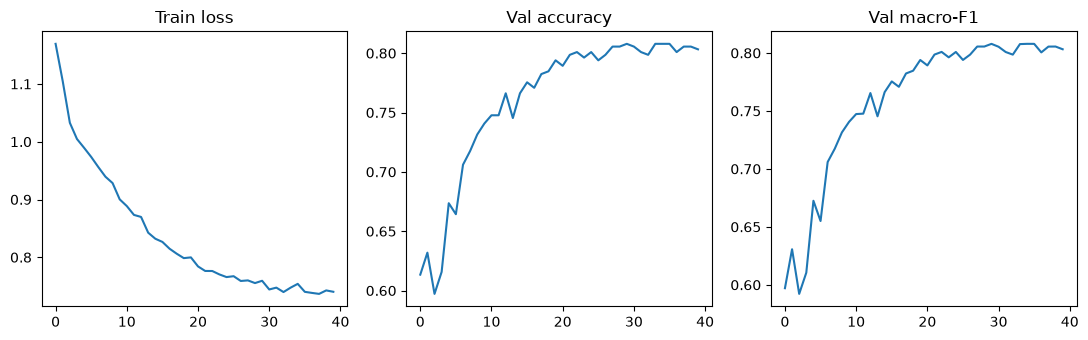

In [5]:
# ============================================================
# CELL 5 — Training (augmentation, cosine LR, grad-clip, early stopping)
# ============================================================
import time

criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR * 0.05)

def augment(xb):
    B, Cn, T = xb.shape
    smax   = int(AUG_SHIFT_SEC * FS)
    shifts = torch.randint(-smax, smax + 1, (B,)).tolist()
    xb = torch.stack([torch.roll(xb[i], shifts[i], dims=-1) for i in range(B)])
    xb = xb * (1 + AUG_AMP_JITTER * torch.randn(B, Cn, 1, device=xb.device))
    xb = xb + AUG_NOISE * torch.randn_like(xb)
    keep = (torch.rand(B, Cn, 1, device=xb.device) > AUG_CH_DROP).float()
    return xb * keep

def evaluate(m, dl):
    m.eval(); P, T = [], []
    with torch.no_grad():
        for xb, yb, _ in dl:
            logits, _, _, _ = m(xb.to(DEVICE))
            P.append(logits.argmax(1).cpu().numpy())
            T.append(yb.numpy())
    return np.concatenate(P), np.concatenate(T)

best_f1, best_state, bad = -1.0, None, 0
hist = {"loss": [], "val_f1": [], "val_acc": []}

print(f"Training up to {EPOCHS} epochs, patience={PATIENCE}\n")

for ep in range(1, EPOCHS + 1):
    model.train()
    tot = 0.0; t0 = time.time()

    for xb, yb, cb in train_loader:
        xb, yb, cb = xb.to(DEVICE), yb.to(DEVICE), cb.to(DEVICE)
        xb = augment(xb)
        optimizer.zero_grad()
        logits, cp, _, _ = model(xb)
        loss = criterion(logits, yb) + LAMBDA_CONCEPT * F.mse_loss(cp, cb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tot += loss.item() * xb.size(0)

    scheduler.step()
    train_loss = tot / len(train_loader.dataset)
    vp, vt = evaluate(model, val_loader)
    v_acc, v_f1 = accuracy_score(vt, vp), f1_score(vt, vp, average="macro")
    hist["loss"].append(train_loss); hist["val_acc"].append(v_acc); hist["val_f1"].append(v_f1)

    mark = ""
    if v_f1 > best_f1:
        best_f1, best_state, bad = v_f1, {k: v.detach().clone() for k, v in model.state_dict().items()}, 0
        mark = "  ← best"
    else:
        bad += 1

    print(f"epoch {ep:02d}/{EPOCHS} | loss {train_loss:.4f} | "
          f"val acc {v_acc:.4f} | val macro-F1 {v_f1:.4f} | {time.time()-t0:.1f}s{mark}")

    if bad >= PATIENCE:
        print(f"\nEarly stop at epoch {ep}.")
        break

model.load_state_dict(best_state)
print(f"\nRestored best model (val macro-F1 = {best_f1:.4f})")

torch.save({
    "model_state":   model.state_dict(),
    "concept_mean":  c_mu.tolist(),
    "concept_std":   c_sd.tolist(),
    "class_names":   CLASS_NAMES,
    "concept_names": CONCEPT_NAMES,
    "bands":         list(BANDS.keys()),
    "fs":            FS,
    "epoch_sec":     EPOCH_SEC,
    "overlap":       OVERLAP,
}, "sam40_cbeegnet_model.pt")
np.savez("concept_stats.npz", c_mu=c_mu, c_sd=c_sd)
print("Saved → sam40_cbeegnet_model.pt")

plt.figure(figsize=(11, 3.5))
plt.subplot(1,3,1); plt.plot(hist["loss"]);        plt.title("Train loss")
plt.subplot(1,3,2); plt.plot(hist["val_acc"]);     plt.title("Val accuracy")
plt.subplot(1,3,3); plt.plot(hist["val_f1"]);      plt.title("Val macro-F1")
plt.tight_layout(); plt.show()


TEST SET PERFORMANCE — CNN only (new, unseen people)
Window-level accuracy : 0.7199
Window-level macro-F1 : 0.7197

              precision    recall  f1-score   support

       Relax       0.71      0.75      0.73       216
      Stroop       0.73      0.69      0.71       216

    accuracy                           0.72       432
   macro avg       0.72      0.72      0.72       432
weighted avg       0.72      0.72      0.72       432

Confusion matrix (window level):
                    Relax    Stroop   <- predicted
  True    Relax        161        55
         Stroop         66       150

RECORDING-LEVEL ACCURACY (CNN): 91.67%   (11/12 recordings)
95% interval (small test set) : 64.6% – 98.5%

Baseline (band power + LR, window level): 0.7269   <- for comparison only


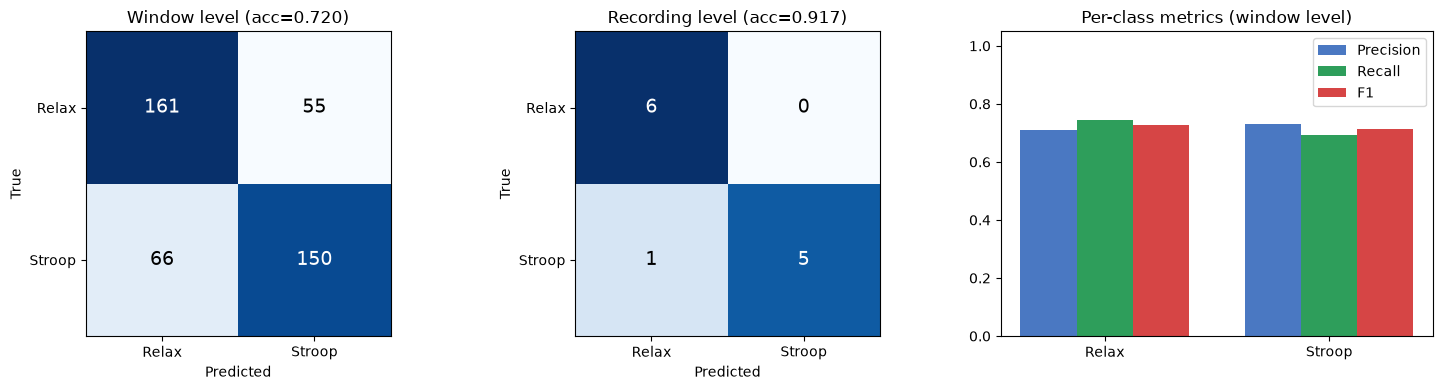


Saved -> test_report.json


In [11]:
'''# ============================================================
# CELL 6 — Test-set evaluation of YOUR TRAINED CNN (honest, CNN only)
#   * no ensemble, no subject-centering, nothing tuned on the test set
#   * window-level AND recording-level accuracy
#   * optional plain baseline (band power + LR, no centering) for comparison
# ============================================================
import torch, json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, precision_recall_fscore_support)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---------- 1) load the trained CNN ----------
ckpt = torch.load("sam40_cbeegnet_model.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model_state"]); model.eval()

# ---------- 2) CNN predictions on the test set ----------
_p, _y = [], []
with torch.no_grad():
    for xb, yb, _ in test_loader:                       # test_loader has shuffle=False
        logits, _, _, _ = model(xb.to(DEVICE))
        _p.append(torch.softmax(logits, 1).cpu().numpy())
        _y.append(yb.numpy())
probs, labels = np.concatenate(_p), np.concatenate(_y)
preds = probs.argmax(1)

acc = accuracy_score(labels, preds)
f1  = f1_score(labels, preds, average="macro")

print("\n" + "=" * 60)
print("TEST SET PERFORMANCE — CNN only (new, unseen people)")
print("=" * 60)
print(f"Window-level accuracy : {acc:.4f}")
print(f"Window-level macro-F1 : {f1:.4f}\n")
print(classification_report(labels, preds, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(labels, preds, labels=[0, 1])
print("Confusion matrix (window level):")
print(f"                 {CLASS_NAMES[0]:>8}  {CLASS_NAMES[1]:>8}   <- predicted")
print(f"  True {CLASS_NAMES[0]:>8}   {cm[0,0]:>8}  {cm[0,1]:>8}")
print(f"       {CLASS_NAMES[1]:>8}   {cm[1,0]:>8}  {cm[1,1]:>8}")

# ---------- 3) recording-level: average CNN probability over all windows of a recording ----------
rec_test = REC[test_mask]
rec_ids  = np.unique(rec_test)
rec_pred = np.array([int(probs[rec_test == r, 1].mean() > 0.5) for r in rec_ids])
rec_true = np.array([int(r % 2) for r in rec_ids])        # 0 = Relax, 1 = Stroop
rec_acc  = accuracy_score(rec_true, rec_pred)
n_ok, n_rec = int((rec_pred == rec_true).sum()), len(rec_ids)

# 95% Wilson interval: with so few recordings the result is uncertain, so show the range
z = 1.96
centre = (rec_acc + z**2 / (2 * n_rec)) / (1 + z**2 / n_rec)
half   = z * np.sqrt(rec_acc * (1 - rec_acc) / n_rec + z**2 / (4 * n_rec**2)) / (1 + z**2 / n_rec)
lo, hi = centre - half, centre + half

print("\n" + "=" * 60)
print(f"RECORDING-LEVEL ACCURACY (CNN): {rec_acc*100:.2f}%   ({n_ok}/{n_rec} recordings)")
print(f"95% interval (small test set) : {lo*100:.1f}% – {hi*100:.1f}%")
print("=" * 60)

cm_rec = confusion_matrix(rec_true, rec_pred, labels=[0, 1])

# ---------- 4) optional plain baseline for comparison (no centering, no ensemble) ----------
def _band(Xw):
    T = Xw.shape[-1]
    spec = np.abs(np.fft.rfft(Xw * np.hanning(T), axis=-1)) ** 2
    fr = np.fft.rfftfreq(T, 1 / FS)
    return np.concatenate([np.log(spec[..., (fr >= a) & (fr < b)].sum(-1) + 1e-12)
                           for a, b in BANDS.values()], axis=1)

F0 = _band(X)
_lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=2000))
_lr.fit(F0[train_mask], Y[train_mask])
base_win = _lr.score(F0[test_mask], Y[test_mask])
print(f"\nBaseline (band power + LR, window level): {base_win:.4f}   <- for comparison only")

# ---------- 5) plots ----------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, m_, ttl in ((ax[0], cm, f"Window level (acc={acc:.3f})"),
                    (ax[1], cm_rec, f"Recording level (acc={rec_acc:.3f})")):
    im = a_.imshow(m_, cmap="Blues")
    a_.set_xticks([0, 1]); a_.set_yticks([0, 1])
    a_.set_xticklabels(CLASS_NAMES); a_.set_yticklabels(CLASS_NAMES)
    a_.set_xlabel("Predicted"); a_.set_ylabel("True"); a_.set_title(ttl)
    for i in range(2):
        for j in range(2):
            a_.text(j, i, str(m_[i, j]), ha="center", va="center",
                    color="white" if m_[i, j] > m_.max() / 2 else "black", fontsize=14)
p, r, f1s, _ = precision_recall_fscore_support(labels, preds, labels=[0, 1], zero_division=0)
x = np.arange(2); w = 0.25
ax[2].bar(x - w, p, w, label="Precision", color="#4a78c2")
ax[2].bar(x,     r, w, label="Recall",    color="#2e9e5b")
ax[2].bar(x + w, f1s, w, label="F1",      color="#d64545")
ax[2].set_xticks(x); ax[2].set_xticklabels(CLASS_NAMES)
ax[2].set_ylim(0, 1.05); ax[2].legend(); ax[2].set_title("Per-class metrics (window level)")
plt.tight_layout(); plt.show()

# ---------- 6) save ----------
summary = {
    "split_mode": "subject (new, unseen people)",
    "test_accuracy": float(acc), "test_macro_f1": float(f1),
    "per_class": {CLASS_NAMES[0]: {"precision": float(p[0]), "recall": float(r[0]), "f1": float(f1s[0])},
                  CLASS_NAMES[1]: {"precision": float(p[1]), "recall": float(r[1]), "f1": float(f1s[1])}},
    "confusion_matrix": cm.tolist(),
    "recording_level_accuracy": float(rec_acc),
    "recording_level_ci95": [float(lo), float(hi)],
    "n_test_recordings": int(n_rec),
    "baseline_band_power_lr_window_acc": float(base_win),
}
with open("test_report.json", "w") as fh:
    json.dump(summary, fh, indent=2)
print("\nSaved -> test_report.json")'''

FINAL RESULT — CB-EEGNet 
  Recording-level accuracy : 91.7%  (11/12 recordings)
  Window-level accuracy    : 72.0%   macro-F1 0.720   AUC 0.810


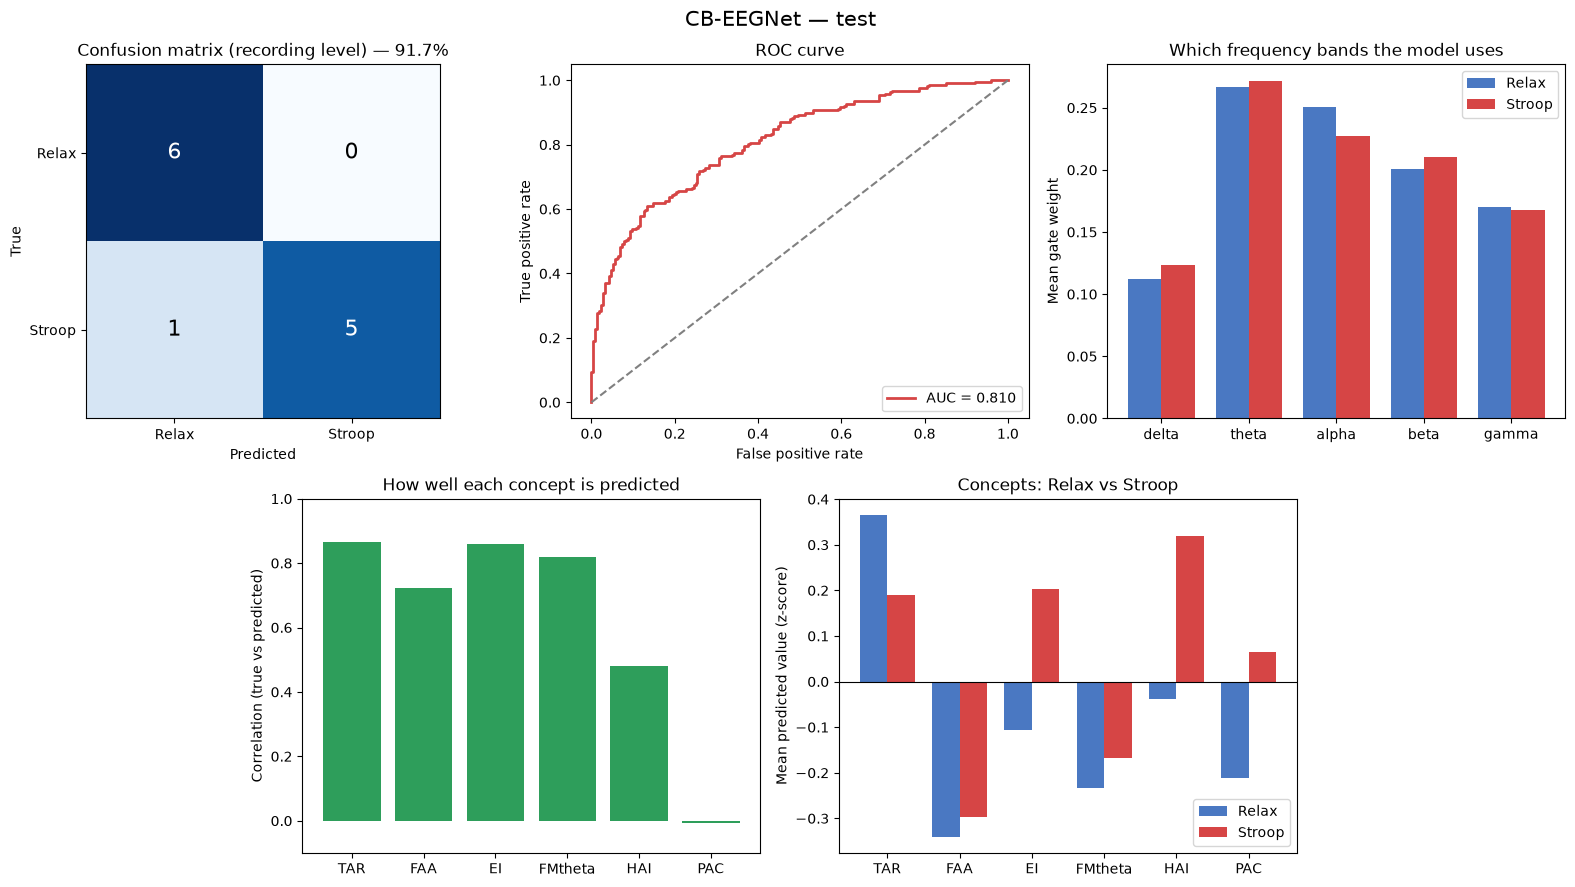

In [14]:
# ============================================================
# CELL 6 — Final evaluation of the WHOLE CB-EEGNet model
#   (filter bank -> 5 band experts -> gate -> 6 concepts -> classifier)
# ============================================================
import torch, json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             roc_curve, roc_auc_score)

# ---------- 1) run the whole model on the test set ----------
ckpt = torch.load("sam40_cbeegnet_model.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model_state"]); model.eval()

_p, _y, _c, _g = [], [], [], []
with torch.no_grad():
    for xb, yb, _ in test_loader:
        logits, concepts, gate_w, _ = model(xb.to(DEVICE))
        _p.append(torch.softmax(logits, 1).cpu().numpy())
        _c.append(concepts.cpu().numpy()); _g.append(gate_w.cpu().numpy()); _y.append(yb.numpy())
probs, labels = np.concatenate(_p), np.concatenate(_y)
cpred, gate   = np.concatenate(_c), np.concatenate(_g)          # (N,6) concepts, (N,5) band weights
ctrue         = C_z[test_mask]                                  # true concepts (z-scored)
preds         = probs.argmax(1)

# ---------- 2) metrics ----------
win_acc = accuracy_score(labels, preds)
win_f1  = f1_score(labels, preds, average="macro")
auc     = roc_auc_score(labels, probs[:, 1])

rec_test = REC[test_mask]; rec_ids = np.unique(rec_test)
rec_pred = np.array([int(probs[rec_test == r, 1].mean() > 0.5) for r in rec_ids])
rec_true = np.array([int(r % 2) for r in rec_ids])
rec_acc  = accuracy_score(rec_true, rec_pred)
n_ok, n_rec = int((rec_pred == rec_true).sum()), len(rec_ids)
z = 1.96                                                         
ctr  = (rec_acc + z**2/(2*n_rec)) / (1 + z**2/n_rec)
half = z*np.sqrt(rec_acc*(1-rec_acc)/n_rec + z**2/(4*n_rec**2)) / (1 + z**2/n_rec)
ci_lo, ci_hi = ctr - half, ctr + half

band_names = list(BANDS.keys())
gate_relax, gate_stroop = gate[labels == 0].mean(0), gate[labels == 1].mean(0)
c_corr = np.array([np.corrcoef(ctrue[:, k], cpred[:, k])[0, 1] for k in range(ctrue.shape[1])])
c_corr = np.nan_to_num(c_corr)

# ---------- 3) key results ----------
print("FINAL RESULT — CB-EEGNet ")
print(f"  Recording-level accuracy : {rec_acc*100:.1f}%  ({n_ok}/{n_rec} recordings)")
print(f"  Window-level accuracy    : {win_acc*100:.1f}%   macro-F1 {win_f1:.3f}   AUC {auc:.3f}")

# ---------- 4) graphs ----------
fig = plt.figure(figsize=(16, 9))
gs  = fig.add_gridspec(2, 6)
ax_cm   = fig.add_subplot(gs[0, 0:2])
ax_roc  = fig.add_subplot(gs[0, 2:4])
ax_gate = fig.add_subplot(gs[0, 4:6])
ax_corr = fig.add_subplot(gs[1, 1:3])
ax_conc = fig.add_subplot(gs[1, 3:5])

m = confusion_matrix(rec_true, rec_pred, labels=[0, 1])
ax_cm.imshow(m, cmap="Blues")
ax_cm.set_xticks([0, 1]); ax_cm.set_yticks([0, 1])
ax_cm.set_xticklabels(CLASS_NAMES); ax_cm.set_yticklabels(CLASS_NAMES)
ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("True")
ax_cm.set_title(f"Confusion matrix (recording level) — {rec_acc*100:.1f}%")
for i in range(2):
    for j in range(2):
        ax_cm.text(j, i, str(m[i, j]), ha="center", va="center", fontsize=16,
                   color="white" if m[i, j] > m.max()/2 else "black")

fpr, tpr, _ = roc_curve(labels, probs[:, 1])
ax_roc.plot(fpr, tpr, lw=2, color="#d64545", label=f"AUC = {auc:.3f}")
ax_roc.plot([0, 1], [0, 1], "--", color="gray")
ax_roc.set_xlabel("False positive rate"); ax_roc.set_ylabel("True positive rate")
ax_roc.set_title("ROC curve"); ax_roc.legend(loc="lower right")

x = np.arange(len(band_names)); w = 0.38
ax_gate.bar(x - w/2, gate_relax,  w, label=CLASS_NAMES[0], color="#4a78c2")
ax_gate.bar(x + w/2, gate_stroop, w, label=CLASS_NAMES[1], color="#d64545")
ax_gate.set_xticks(x); ax_gate.set_xticklabels(band_names)
ax_gate.set_ylabel("Mean gate weight"); ax_gate.set_title("Which frequency bands the model uses"); ax_gate.legend()

xc = np.arange(len(CONCEPT_NAMES))
ax_corr.bar(xc, c_corr, color="#2e9e5b")
ax_corr.set_xticks(xc); ax_corr.set_xticklabels(CONCEPT_NAMES); ax_corr.set_ylim(-0.1, 1.0)
ax_corr.set_ylabel("Correlation (true vs predicted)"); ax_corr.set_title("How well each concept is predicted")

ax_conc.bar(xc - w/2, cpred[labels == 0].mean(0), w, label=CLASS_NAMES[0], color="#4a78c2")
ax_conc.bar(xc + w/2, cpred[labels == 1].mean(0), w, label=CLASS_NAMES[1], color="#d64545")
ax_conc.axhline(0, color="black", lw=0.8)
ax_conc.set_xticks(xc); ax_conc.set_xticklabels(CONCEPT_NAMES)
ax_conc.set_ylabel("Mean predicted value (z-score)"); ax_conc.set_title("Concepts: Relax vs Stroop"); ax_conc.legend()

plt.suptitle("CB-EEGNet — test", fontsize=15)
plt.tight_layout(); plt.show()

# ---------- 5) save ----------
with open("test_report.json", "w") as fh:
    json.dump({"split_mode": "subject (new, unseen people)",
               "recording_level_accuracy": float(rec_acc), "recording_level_ci95": [float(ci_lo), float(ci_hi)],
               "n_test_recordings": int(n_rec),
               "test_accuracy": float(win_acc), "test_macro_f1": float(win_f1), "auc": float(auc),
               "band_gate_weights": dict(zip(band_names, map(float, gate.mean(0)))),
               "concept_correlation": dict(zip(CONCEPT_NAMES, map(float, c_corr)))}, fh, indent=2)

In [16]:
# ============================================================
# CELL 7 — Knowledge base for Retrieval-Augmented Generation
# ============================================================
SRC = ("General wellbeing guidance — replace with your cited source "
       "(WHO, NIMH, APA, or your own papers).")

KB = [
    # ---------- What the model's concepts mean (plain language) ----------
    dict(topic="Relaxed vs. effortful brain states",
         source=SRC,
         text=("When the brain is relaxed, alpha waves (8-13 Hz) tend to be strong, "
               "especially at the back of the head. When the brain is working hard — "
               "solving arithmetic, doing a Stroop task, or under mental pressure — fast "
               "beta waves (13-30 Hz) increase while alpha tends to drop. Our model "
               "distinguishes this 'idle vs. engaged' shift from EEG alone.")),

    dict(topic="What the 'Stroop' class means",
         source=SRC,
         text=("The Stroop task asks a person to name the ink colour of a word while "
               "ignoring the word itself. It creates mental conflict and is a well-"
               "established way of inducing short-term cognitive stress in research. A "
               "'Stroop-like' EEG pattern therefore means the brain is under high "
               "cognitive load — it does NOT mean the person has a clinical disorder.")),

    dict(topic="Theta-alpha ratio (TAR) in simple words",
         source=SRC,
         text=("TAR compares slow 'working-hard' theta waves with relaxed alpha waves at "
               "the front of the head. A higher TAR usually means the brain is less "
               "relaxed or is working hard, but it also rises with tiredness, so it is "
               "only a weak clue on its own.")),

    dict(topic="Frontal alpha asymmetry (FAA) in simple words",
         source=SRC,
         text=("FAA compares relaxed-wave activity between the right and left front of "
               "the head. It has been linked to emotional style in research, but the "
               "effect is small and differs between people, so it should not be over-"
               "interpreted.")),

    dict(topic="Engagement index (EI) in simple words",
         source=SRC,
         text=("The engagement index compares fast 'alert' beta waves against slower "
               "alpha and theta waves. A higher EI usually means the person is "
               "mentally engaged, alert, or tense; a lower EI usually means relaxed or "
               "drowsy.")),

    dict(topic="Frontal midline theta (FMθ) in simple words",
         source=SRC,
         text=("Slow theta waves in the middle-front of the head tend to rise with "
               "concentration, mental effort and worry. High FMθ is a common signature "
               "of mental load.")),

    dict(topic="Hemispheric asymmetry index (HAI) in simple words",
         source=SRC,
         text=("HAI measures how evenly relaxed-wave activity is spread between left "
               "and right sides of the head. It is a weak, indirect clue; differences "
               "between people are often larger than differences between states.")),

    dict(topic="Phase-amplitude coupling (PAC) in simple words",
         source=SRC,
         text=("PAC describes how slower rhythms (like theta) coordinate the strength "
               "of faster rhythms (like gamma). It is linked to attention and memory "
               "and changes under mental load, but it is noisy on short recordings.")),

    dict(topic="No single EEG indicator diagnoses stress",
         source=SRC,
         text=("No single EEG indicator can diagnose stress. Patterns across several "
               "indicators — together with how the person feels and what is happening "
               "in their life — are much more informative. Brain signals also differ a "
               "lot from person to person.")),

    # ---------- Common reasons mental load goes up ----------
    dict(topic="Sleep loss",
         source=SRC,
         text=("Not getting enough sleep makes the body react more strongly to "
               "pressure and can cause irritability, poor concentration and low mood. "
               "Many adults need about 7 to 9 hours of sleep.")),

    dict(topic="Workload, exams and deadlines",
         source=SRC,
         text=("Long periods of pressure without breaks — exams, deadlines, back-to-"
               "back meetings — are a very common cause of stress. Feeling that "
               "demands are bigger than your ability to cope makes it worse.")),

    dict(topic="Caffeine and stimulants",
         source=SRC,
         text=("Coffee, strong tea, energy drinks and nicotine can raise heart rate "
               "and make people feel jittery or anxious. Caffeine late in the day "
               "also makes it harder to sleep.")),

    dict(topic="Screens and constant notifications",
         source=SRC,
         text=("Constant notifications, endless scrolling and late-night screens keep "
               "the mind switched on and interfere with rest.")),

    dict(topic="Worries about family, money, health or relationships",
         source=SRC,
         text=("Ongoing worries about family, money, health or relationships, and "
               "feeling isolated, are common causes of long-lasting stress.")),

    dict(topic="Low activity, skipped meals, dehydration",
         source=SRC,
         text=("Sitting for long periods, skipping meals and not drinking enough water "
               "can make the body feel more tense and tired, which adds to feelings of "
               "stress.")),

    # ---------- Practical self-care ----------
    dict(topic="Slow breathing",
         source=SRC,
         text=("Slow breathing — in through the nose for about 4 seconds and out "
               "slowly for about 6 seconds, repeated for around 5 minutes — helps "
               "calm the body's stress response for many people.")),

    dict(topic="Physical activity",
         source=SRC,
         text=("Regular moderate activity such as a brisk 30-minute walk on most days, "
               "yoga, or cycling is linked to lower stress, better mood, and better "
               "sleep.")),

    dict(topic="Sleep habits",
         source=SRC,
         text=("Go to bed and wake up at similar times, dim screens for an hour before "
               "bed, keep the room dark and cool, and avoid caffeine in the afternoon "
               "and evening.")),

    dict(topic="Breaks and planning",
         source=SRC,
         text=("Break big tasks into small steps, list the top 2 or 3 priorities for "
               "the day, take a 5-10 minute break every hour or so, and learn to say "
               "no to extra demands when overloaded.")),

    dict(topic="Talk to someone you trust",
         source=SRC,
         text=("Talking with a trusted friend, family member, teacher or counsellor "
               "often lowers stress. You do not have to handle everything alone.")),

    dict(topic="Relaxation and mindfulness",
         source=SRC,
         text=("Short relaxation practices such as mindfulness, meditation, "
               "progressive muscle relaxation, or listening to calming music can "
               "reduce tension within minutes.")),

    dict(topic="Food, water and alcohol",
         source=SRC,
         text=("Eat regular meals, drink enough water, and limit alcohol and heavy "
               "caffeine intake. Using alcohol or other substances to cope tends to "
               "make stress worse over time.")),

    # ---------- When to get help / limits ----------
    dict(topic="When to see a professional",
         source=SRC,
         text=("Talk to a doctor or counsellor if stress lasts more than two weeks, "
               "disturbs sleep, work, studies or relationships, comes with panic "
               "attacks, or if you are using alcohol or other substances to cope.")),

    dict(topic="Emergency warning signs",
         source=SRC,
         text=("Thoughts of harming yourself, chest pain, trouble breathing or "
               "fainting need urgent help. Contact emergency services or a crisis "
               "helpline straight away.")),

    dict(topic="Limits of this tool",
         source=SRC,
         text=("This assistant is a research prototype. It estimates a Relax vs. high "
               "cognitive-load pattern from a few EEG features using a model trained "
               "on the SAM 40 dataset. It cannot diagnose any condition and must not "
               "be used in place of professional care.")),
]

# ---- quick stats ----
print(f"Knowledge base loaded: {len(KB)} passages")
topics = [d["topic"] for d in KB]

# length check
avg_len = np.mean([len(d["text"]) for d in KB])
print(f"\nAverage passage length: {avg_len:.0f} characters")

Knowledge base loaded: 25 passages

Average passage length: 191 characters


In [17]:
# ============================================================
# CELL 8 — Retriever (Ollama embeddings + FAISS, TF-IDF fallback)
# ============================================================
class Retriever:
    """
    Semantic search over the knowledge base.
    Primary : Ollama nomic-embed-text → FAISS inner-product index
    Fallback: scikit-learn TF-IDF (works offline, no Ollama required)
    """
    def __init__(self, kb):
        self.kb    = kb
        texts      = [f"{d['topic']}. {d['text']}" for d in kb]
        self.texts = texts

        # --- try the Ollama + FAISS path ---
        try:
            import faiss
            v = self._emb(texts)                          # (N, dim) L2-normalised
            self.index = faiss.IndexFlatIP(v.shape[1])    # inner product == cosine on unit vectors
            self.index.add(v)
            self.mode = "ollama+faiss"
        except Exception as e:
            print("Ollama embeddings / FAISS unavailable → using TF-IDF fallback.")
            print("  reason:", str(e)[:160])
            from sklearn.feature_extraction.text import TfidfVectorizer
            self.vec  = TfidfVectorizer(stop_words="english",
                                        ngram_range=(1, 2)).fit(texts)
            self.M    = self.vec.transform(texts)
            self.mode = "tfidf"

        print("Retriever mode:", self.mode)
        print(f"Indexed {len(kb)} passages")

    @staticmethod
    def _emb(texts):
        """Get L2-normalised embeddings from Ollama."""
        import ollama, faiss
        out = ollama.embed(model=OLLAMA_EMBED, input=texts)
        v   = np.array(out["embeddings"], dtype="float32")
        faiss.normalize_L2(v)
        return v

    def search(self, query, k=4):
        """
        Return the top-k most similar KB passages as a list of dicts:
        {topic, source, text, score}
        """
        if not query or not query.strip():
            return []

        if self.mode == "ollama+faiss":
            q  = self._emb([query])
            s, i = self.index.search(q, k)
            pairs = [(int(j), float(sc)) for sc, j in zip(s[0], i[0]) if j >= 0]
        else:
            # TF-IDF cosine similarity
            qv   = self.vec.transform([query])
            sims = (self.M @ qv.T).toarray().ravel()
            pairs = [(int(j), float(sims[j])) for j in np.argsort(-sims)[:k]]

        return [{**self.kb[j], "score": sc} for j, sc in pairs]


# ----------------- Build the retriever -----------------
RET = Retriever(KB)

# ----------------- Sanity check: three example queries -----------------
print("\n--- Sanity check: sample retrievals ---")
sample_queries = [
    "I feel mentally exhausted after long study sessions",
    "How can I calm down quickly when I feel tense?",
    "What does the engagement index mean?",
]
for q in sample_queries:
    print(f"\nQuery: {q!r}")
    hits = RET.search(q, k=3)
    for h in hits:
        print(f"  [{h['score']:.3f}] {h['topic']}")

Retriever mode: ollama+faiss
Indexed 25 passages

--- Sanity check: sample retrievals ---

Query: 'I feel mentally exhausted after long study sessions'
  [0.686] Low activity, skipped meals, dehydration
  [0.655] Workload, exams and deadlines
  [0.642] Screens and constant notifications

Query: 'How can I calm down quickly when I feel tense?'
  [0.766] Relaxation and mindfulness
  [0.735] Slow breathing
  [0.655] Low activity, skipped meals, dehydration

Query: 'What does the engagement index mean?'
  [0.779] Engagement index (EI) in simple words
  [0.549] Hemispheric asymmetry index (HAI) in simple words
  [0.480] No single EEG indicator diagnoses stress


In [18]:
'''# ============================================================
# CELL 9 — LLM helpers, safety nets, SAM 40 inference, figures
# ============================================================
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg

# ------------------------------------------------------------
# Concept → plain-language descriptions (used in explanations)
# ------------------------------------------------------------
CONCEPT_INFO = {
    "TAR":     ("Mental effort vs. relaxation",  "slow 'working-hard' waves vs. relaxed waves at the front"),
    "FAA":     ("Left-right emotional balance",  "difference in relaxed waves between left and right front"),
    "EI":      ("Alertness / engagement",        "strength of fast 'alert' waves compared with slower waves"),
    "FMtheta": ("Focus and worry signal",        "slow middle-front waves that rise with mental load"),
    "HAI":     ("Whole-head left-right balance", "how evenly relaxed waves spread left vs. right"),
    "PAC":     ("Brain-rhythm coordination",     "how well slow and fast rhythms work together"),
}

REF   = "your usual level (training average)"
EMOJI = {"Relax": "🟢", "Stroop": "🔴"}

def z_level(z):
    """Map a z-score to a human-readable phrase."""
    if z <= -1.5: return f"much lower than {REF}"
    if z <= -0.5: return f"lower than {REF}"
    if z <  0.5:  return f"about {REF}"
    if z <  1.5:  return f"higher than {REF}"
    return f"much higher than {REF}"

# ------------------------------------------------------------
# Safety regexes — override the LLM for crisis / medical text
# ------------------------------------------------------------
SELF_HARM = re.compile(
    r"suicid|kill myself|end my life|want to die|self[- ]?harm|"
    r"hurt myself|no reason to live|better off dead", re.I)
MEDICAL   = re.compile(
    r"chest pain|can'?t breathe|cannot breathe|trouble breathing|"
    r"faint|passed out|heart attack|stroke", re.I)

CRISIS_MSG = (
    "I'm really sorry you're feeling this way — thank you for telling me. "
    "You don't have to face this alone. Please reach out right now to "
    f"{HELPLINE_TEXT}, or to a trusted person near you. If you might act on "
    "these thoughts or are in immediate danger, please call your local "
    "emergency number now. I'm a research prototype and can't give the "
    "support you deserve, but a real person can.")

MEDICAL_MSG = (
    "Chest pain, trouble breathing or fainting can be signs of a medical "
    "emergency and are not something this tool can assess. Please seek urgent "
    "medical care or call your local emergency number right away.")

# ------------------------------------------------------------
# System prompt — the rules the LLM must obey
# ------------------------------------------------------------
SYSTEM_BASE = (
    "You are a warm, clear wellbeing explainer for ordinary people (not doctors). Rules:\n"
    "- Use simple everyday words and short sentences. If you must use a technical word, "
    "  explain it in brackets.\n"
    "- Explain the model's EEG output ONLY from the MODEL RESULT and KNOWLEDGE NOTES below. "
    "  Do not invent facts, numbers or studies.\n"
    "- The class label is an ESTIMATE from a research prototype. Never call it a diagnosis, "
    "  never name a mental illness for the person, never suggest medicines or doses, and "
    "  never change the predicted class.\n"
    "- Give practical, safe self-care steps. Mention when to talk to a professional, and "
    "  that thoughts of self-harm, chest pain or fainting need urgent help.\n"
    "- Be kind and non-judgemental. If asked something outside stress and wellbeing, "
    "  gently steer back.")

REPORT_INSTR = (
    "Write my personalised report using exactly these headings: "
    "1) Your result in simple words  2) What this likely means  "
    "3) What you can do today  4) What you can do this week  "
    "5) When to talk to a professional  6) Important note. "
    "Use short bullet points under headings 3 and 4. Keep it under 350 words.")

# ------------------------------------------------------------
# Prompt builders
# ------------------------------------------------------------
def life_text(life):
    if not life: return "- not provided"
    rows = [("Sleep last night", "sleep_label"),
            ("Tea/coffee/energy drinks per day", "caffeine_label"),
            ("Exercise", "activity_label"),
            ("Main source of stress", "stressor")]
    s = [f"- {n}: {life[k]}" for n, k in rows if life.get(k)]
    s.append("- Symptoms: " +
             (", ".join(life["symptoms"]) if life.get("symptoms") else "none selected"))
    return "\n".join(s)

def system_with_context(res, life, evidence):
    """Assemble the system message with model output + user info + retrieved notes."""
    P = [SYSTEM_BASE, "", "MODEL RESULT:"]
    if res:
        P.append(f"- Estimated class: {res['pred']} (confidence: " +
                 ", ".join(f"{k} {v*100:.0f}%" for k, v in res["probs"].items()) + ")")
        for n in CONCEPT_NAMES:
            P.append(f"- {CONCEPT_INFO[n][0]} ({n}): {z_level(res['z'][n])}; "
                     f"effect on result: "
                     f"{'toward' if res['contrib'][n] > 0 else 'away from'} {res['pred']}")
    else:
        P.append("- (No result yet — the person has not run the analysis.)")

    P += ["", "ABOUT THE PERSON (self-reported, optional):", life_text(life),
          "", "KNOWLEDGE NOTES:"]
    P += [f"[{i+1}] {e['text']}" for i, e in enumerate(evidence)]
    return "\n".join(P)

def build_query(res, life, extra=""):
    """Build a retrieval query from the model result + user context."""
    q = [extra, "relaxed versus mental effort EEG",
         "ways to reduce cognitive stress self-care"]
    if res:
        q.append(f"{res['pred']} state")
        for n, _ in sorted(res["contrib"].items(), key=lambda kv: -abs(kv[1]))[:3]:
            q.append(CONCEPT_INFO[n][0] + " " + CONCEPT_INFO[n][1])
    if life:
        if life.get("sleep") is not None and life["sleep"] < 6:
            q.append("sleep loss sleep habits")
        if (life.get("caffeine") or 0) >= 4:
            q.append("caffeine stimulants")
        if life.get("activity") is not None and life["activity"] <= 1:
            q.append("physical activity")
        if life.get("stressor"):
            q.append(life["stressor"])
    return " ".join(q)

# ------------------------------------------------------------
# Streaming wrapper around Ollama chat
# ------------------------------------------------------------
def stream_llm(messages):
    """Yield cumulative text as Ollama streams the response."""
    import ollama
    buf = ""
    for part in ollama.chat(model=OLLAMA_LLM, messages=messages,
                            stream=True, options={"temperature": 0.3}):
        buf += part["message"]["content"]
        yield buf

def fallback_text(evidence, err):
    """Used if Ollama isn't reachable — returns KB snippets instead."""
    return ("⚠️ The local AI writer (Ollama) could not be reached, so here "
            "are the most relevant tips from the knowledge base instead.\n"
            f"(To enable the AI writer: run `ollama serve` and `ollama pull {OLLAMA_LLM}`.)\n\n"
            + "\n".join(f"- {e['text']}" for e in evidence)
            + f"\n\n_Technical detail: {str(err)[:160]}_")

# ------------------------------------------------------------
# Result → markdown + figures
# ------------------------------------------------------------
def _result_text(res, sure=True):
    top = sorted(res["contrib"].items(), key=lambda kv: -abs(kv[1]))[:3]
    probs = " · ".join(f"{k} {v*100:.0f}%" for k, v in res["probs"].items())
    head  = f"### {EMOJI[res['pred']]} Estimated state: **{res['pred']}**"
    if not sure:
        head += " *(low confidence — see note below)*"
    L = [head, "", f"Model confidence: {probs}", "",
         "**Which signals mattered most (in plain words):**"]
    for n, c in top:
        L.append(f"- **{CONCEPT_INFO[n][0]}** is {z_level(res['z'][n])} → leans "
                 f"{'toward' if c > 0 else 'away from'} *{res['pred']}*")
    L += ["", "> ⚠️ Research prototype — **not a medical diagnosis**."]
    if not sure:
        L.append("")
        L.append("> The model's confidence is low, so treat the class as "
                 "inconclusive and focus on the general advice in the chat below.")
    return "\n".join(L)

def make_figure(res):
    """Two-panel figure: class probabilities + concept contributions."""
    fig = Figure(figsize=(9, 3.3))
    a1, a2 = fig.subplots(1, 2)

    names = list(res["probs"])
    a1.bar(names, [res["probs"][n]*100 for n in names], color=["#2e9e5b", "#d64545"])
    a1.set_ylim(0, 100); a1.set_title("Model confidence (%)", fontsize=10)

    items = sorted(res["contrib"].items(), key=lambda kv: kv[1])
    vals  = [v for _, v in items]
    a2.barh([CONCEPT_INFO[n][0] for n, _ in items], vals,
            color=["#d64545" if v > 0 else "#4a78c2" for v in vals])
    a2.axvline(0, color="k", lw=0.6); a2.tick_params(labelsize=8)
    a2.set_title(f"Pushes toward '{res['pred']}' (red) / away (blue)", fontsize=10)

    fig.tight_layout(); return fig

def fig_to_array(fig):
    c = FigureCanvasAgg(fig); c.draw()
    return np.asarray(c.buffer_rgba())[..., :3].copy()

# ------------------------------------------------------------
# SAM 40 CSV reader — matches Ch1..Ch32 files (no Time_sec)
# ------------------------------------------------------------
def read_csv_eeg(file, fs_in=FS):
    """
    Read a SAM 40 CSV (columns Ch1..Ch32 or any 32 numeric channels).
    `fs_in` is the recording sampling rate; if != FS, resample to FS.
    """
    if not file:
        raise ValueError("Please upload a CSV file first.")
    path = file if isinstance(file, str) else file.name
    if not path.lower().endswith((".csv", ".xlsx", ".xls")):
        raise ValueError("Only .csv / .xlsx files are supported.")

    # Excel needs a different reader
    if path.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path)
    else:
        df = pd.read_csv(path)

    # Drop obvious index / time / label columns
    for c in list(df.columns):
        cl = str(c).strip().lower()
        if cl.startswith("unnamed") or cl in ("index", "time_sec", "time",
                                               "timestamp", "label", "class", "target"):
            df = df.drop(columns=[c])

    num = df.select_dtypes(include=np.number).dropna(axis=1, how="all")
    if num.shape[1] < 32:
        raise ValueError(f"Need at least 32 numeric EEG columns, found {num.shape[1]}.")
    if num.shape[1] > 32:
        pref = [c for c in num.columns if str(c).lower().startswith(("ch", "eeg"))]
        num  = num[pref[:32]] if len(pref) >= 32 else num.iloc[:, :32]

    x = num.values.T.astype(np.float64)                   # (32, N)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if fs_in and fs_in > 0 and abs(fs_in - FS) > 1:
        new_len = int(round(x.shape[1] * FS / fs_in))
        x = sg.resample(x, new_len, axis=1)

    # 0.5–45 Hz band-pass (same preprocessing as training)
    x = sg.sosfiltfilt(sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos"),
                       x, axis=1)

    if x.shape[1] < EPOCH_SEC * FS:
        raise ValueError(f"Recording too short: need ≥ {EPOCH_SEC}s "
                         f"(got {x.shape[1]/FS:.2f}s).")
    return x.astype(np.float32)

# ------------------------------------------------------------
# Inference on a raw (32, N) signal
# ------------------------------------------------------------
def predict_trial(x, c_mu_local=None, c_sd_local=None):
    """
    Run the trained CB-EEGNet on a (32, N) recording.
    Returns (result_dict, windows_array_for_plot).
    """
    if c_mu_local is None: c_mu_local = c_mu
    if c_sd_local is None: c_sd_local = c_sd

    w  = epoch_signal(x)                          # (n_win, 32, T)
    if w.size == 0:
        raise ValueError("No epochs produced from this recording.")
    c  = compute_concepts(w)                      # (n_win, 6)
    wz = (w - w.mean(-1, keepdims=True)) / (w.std(-1, keepdims=True) + 1e-6)

    model.eval()
    with torch.no_grad():
        lg, cp, g, _ = model(torch.from_numpy(wz.astype(np.float32)).to(DEVICE))

    probs = F.softmax(lg, 1).mean(0).cpu().numpy()
    k     = int(probs.argmax())
    cp_m  = cp.mean(0).cpu().numpy()
    g_m   = g.mean(0).cpu().numpy()

    # Per-concept contribution to the winning class (linear proxy on the classifier)
    W = model.classifier[0].weight.detach().cpu().numpy()      # (hidden, 6)
    contrib = cp_m * W.mean(0)

    # Concept z-scores relative to the training distribution
    c_z = np.clip((c.mean(0) - c_mu_local) / (c_sd_local + 1e-8), -3, 3)

    res = {
        "pred":    CLASS_NAMES[k],
        "probs":   {n: float(p) for n, p in zip(CLASS_NAMES, probs)},
        "contrib": {n: float(v) for n, v in zip(CONCEPT_NAMES, contrib)},
        "z":       {n: float(v) for n, v in zip(CONCEPT_NAMES, c_z)},
        "gate":    {b: float(v) for b, v in zip(list(BANDS), g_m)},
        "n_epochs": len(w),
    }
    return res, w

# ------------------------------------------------------------
# Signal figure (input preview + band-power bar)
# ------------------------------------------------------------
def signal_figure(x):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))

    seg = x[:, :min(4*FS, x.shape[1])]
    for j, i in enumerate(range(0, 32, 4)):
        ax[0].plot(seg[i] / (np.abs(seg[i]).max() + 1e-6) + j*1.5, lw=0.7)
    ax[0].set_title("EEG input (8 of 32 channels, up to 4 s)")
    ax[0].set_yticks([])

    w = epoch_signal(x)
    P = [np.log10(band_power(w.astype(np.float64), *BANDS[b]).mean() + 1e-12)
         for b in BANDS]
    ax[1].bar(list(BANDS), P, color="#4c78a8")
    ax[1].set_title("Band power (log10, avg of 32 channels)")

    plt.tight_layout(); return fig'''

In [24]:
'''# ============================================================
# CELL 10 — Gradio UI  (INPUT unchanged, NEW OUTPUT)
# Outputs:
#   1. Smart Stress Summary      (level + score/100 + plain explanation, as image)
#   2. Explainable AI Graph      (what raised / lowered the result)
#   3. Brain-Wave Analysis       (Delta, Theta, Alpha, Beta, Gamma %)
#   4. Data Quality Check        (warns if the recording is unreliable)
#   5. Wellbeing Suggestions     (based on result + optional lifestyle answers)
# ============================================================
import gradio as gr
import json
from matplotlib.figure import Figure

# ---------- Config ----------
INCONCLUSIVE_P = 0.65
LOW_MAX  = 0.40
HIGH_MIN = 0.65

SLEEP_OPTS = {"Less than 5 hours": 4.5, "5-6 hours": 5.5,
              "7-8 hours": 7.5, "More than 8 hours": 9.0}
CAFF_OPTS  = {"None": 0, "1-2 cups": 2, "3-4 cups": 4, "5 or more": 6}
ACT_OPTS   = {"Rarely / never": 0, "1-2 days a week": 2,
              "3-4 days a week": 4, "5 or more days a week": 6}
STRESSORS  = ["Studies / exams", "Work", "Family", "Health",
              "Money", "Relationships", "Not sure"]
SYMPTOMS   = ["Trouble sleeping", "Headaches", "Racing heart", "Irritability",
              "Trouble concentrating", "Feeling low", "Muscle tension"]

LEVEL_COLOR = {"Low": "#2e9e5b", "Medium": "#e0a800", "High": "#d64545"}

def stress_level(p_stroop):
    if p_stroop < LOW_MAX:  return "Low"
    if p_stroop > HIGH_MIN: return "High"
    return "Medium"

# stores info about the last uploaded file (used by the quality check)
QC_INFO = {"orig_sec": None}

# ---------- CSV reader (same as before + remembers original length) ----------
def read_csv_eeg(file, fs_in=FS):
    if not file:
        raise ValueError("Please upload a CSV file first.")
    path = file if isinstance(file, str) else file.name
    if not path.lower().endswith((".csv", ".xlsx", ".xls")):
        raise ValueError("Only .csv / .xlsx files are supported.")

    def _read(has_header):
        hdr = 0 if has_header else None
        if path.lower().endswith((".xlsx", ".xls")):
            return pd.read_excel(path, header=hdr)
        return pd.read_csv(path, header=hdr)

    df = _read(True)
    try:
        [float(c) for c in df.columns]
        df = _read(False)
    except (ValueError, TypeError):
        pass

    for c in list(df.columns):
        cl = str(c).strip().lower()
        if cl.startswith("unnamed") or cl in ("index", "time_sec", "time",
                                               "timestamp", "label", "class", "target"):
            df = df.drop(columns=[c])

    num = df.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
    if num.shape[1] < 32:
        raise ValueError(f"Need at least 32 numeric EEG columns, found {num.shape[1]}.")
    if num.shape[1] > 32:
        pref = [c for c in num.columns if str(c).lower().startswith(("ch", "eeg"))]
        num  = num[pref[:32]] if len(pref) >= 32 else num.iloc[:, :32]

    x = num.values.T.astype(np.float64)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if fs_in and fs_in > 0 and abs(fs_in - FS) > 1:
        new_len = int(round(x.shape[1] * FS / fs_in))
        x = sg.resample(x, new_len, axis=1)

    needed = EPOCH_SEC * FS
    n0 = x.shape[1]
    QC_INFO["orig_sec"] = n0 / FS                      # <-- remembered for quality check
    if n0 < FS:
        raise ValueError(f"Recording is only {n0/FS:.2f}s long - need at least 1 second.")
    if n0 < needed:
        reps   = int(np.ceil(needed / n0))
        pieces = [x if r % 2 == 0 else x[:, ::-1] for r in range(reps)]
        x = np.concatenate(pieces, axis=1)[:, :needed]
        print(f"  [info] {n0/FS:.2f}s recording extended to {EPOCH_SEC}s by mirror-repeat")
    if "preprocess_windows" not in globals():
        x = sg.sosfiltfilt(sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos"),
                           x, axis=1)
    return x.astype(np.float32)

# ---------- Plain-language names ----------
PLAIN = {"TAR": "Mental effort", "FAA": "Mood balance", "EI": "Alertness",
         "FMtheta": "Focus and worry", "HAI": "Head balance", "PAC": "Rhythm sync"}
PLAIN_MEANING = {
    "TAR":     "slow 'working-hard' brain waves compared with relaxed waves at the front of the head",
    "FAA":     "how balanced the relaxed waves are between the left and right front of the head",
    "EI":      "how strong the fast 'alert' waves are compared with slower ones",
    "FMtheta": "slow waves at the middle-front that rise with concentration and worry",
    "HAI":     "how balanced the relaxed waves are between left and right over the whole head",
    "PAC":     "how well slow and fast brain rhythms work together",
}
BAND_LABEL = {"delta": "Delta\n(very slow)", "theta": "Theta\n(effort)",
              "alpha": "Alpha\n(relaxed)",    "beta":  "Beta\n(alert)",
              "gamma": "Gamma\n(fast)"}
BAND_COLOR = {"delta": "#8c8c8c", "theta": "#e0a800", "alpha": "#2e9e5b",
              "beta": "#d64545", "gamma": "#7a5cc2"}
_SOS_VIEW = sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos")

# ---------- Concept push ----------
def concept_push(res):
    z = torch.tensor([res["z"][n] for n in CONCEPT_NAMES],
                     dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad():
        def margin(v):
            lg = model.classifier(v.unsqueeze(0))[0]
            return float(lg[1] - lg[0])
        base = margin(z)
        out = {}
        for i, n in enumerate(CONCEPT_NAMES):
            zz = z.clone(); zz[i] = 0.0
            out[n] = base - margin(zz)
    return out

# ---------- Band shares ----------
def band_shares(x):
    w = epoch_signal(x)
    if w.size == 0:
        w = x[None]
    w = w.astype(np.float64)
    w = w - w.mean(-1, keepdims=True)
    w = sg.sosfiltfilt(_SOS_VIEW, w, axis=-1)
    P = np.array([band_power(w, *BANDS[b]).mean() for b in BANDS])
    return dict(zip(BANDS, 100 * P / P.sum()))

# ============================================================
# 4. DATA QUALITY CHECK
# ============================================================
def data_quality(x):
    """Returns dict: status (Good/Fair/Poor), score (0-100), issues (list), bad_channels (set), sd (per channel)."""
    issues, score = [], 100
    sd  = x.std(axis=1)
    med = np.median(sd) + 1e-12

    # 1) recording length
    orig = QC_INFO.get("orig_sec")
    if orig is not None and orig < EPOCH_SEC:
        issues.append(f"The recording is short ({orig:.1f}s). It was repeated to reach "
                      f"{EPOCH_SEC}s, so the result is less reliable.")
        score -= 25

    # 2) flat (dead) channels
    flat = set(np.where(sd < 0.01 * med)[0])
    # 3) extremely noisy channels
    noisy = set(np.where(sd > 5 * med)[0])
    # 4) channels with big spikes (movement / loose electrode)
    z = (x - x.mean(1, keepdims=True)) / (sd[:, None] + 1e-12)
    spiky = set(np.where((np.abs(z) > 8).mean(axis=1) > 0.005)[0])

    if flat:
        issues.append(f"{len(flat)} sensor(s) look flat or disconnected.")
    if noisy:
        issues.append(f"{len(noisy)} sensor(s) are unusually noisy.")
    if spiky:
        issues.append(f"{len(spiky)} sensor(s) show sudden spikes (movement or loose contact).")
    bad = flat | noisy | spiky
    score -= min(40, 5 * len(bad))

    # 5) mains-power (50/60 Hz) noise
    try:
        f, p = sg.welch(x, fs=FS, nperseg=min(x.shape[1], 2 * FS), axis=-1)
        pm = p.mean(0)
        broad = pm[(f >= 1) & (f <= 40)].sum() + 1e-12
        for fl in (50, 60):
            if FS / 2 > fl + 2:
                ratio = pm[(f >= fl - 1) & (f <= fl + 1)].sum() / broad
                if ratio > 0.5:
                    issues.append(f"Strong {fl} Hz electrical interference detected.")
                    score -= 15
                    break
    except Exception:
        pass

    # 6) too many exact zeros (missing data)
    zero_frac = float((x == 0).mean())
    if zero_frac > 0.05:
        issues.append(f"{zero_frac*100:.0f}% of the values are exactly zero (missing data).")
        score -= 20

    score  = max(0, score)
    status = "Good" if score >= 80 else ("Fair" if score >= 55 else "Poor")
    return {"status": status, "score": score, "issues": issues,
            "bad": bad, "sd": sd}

def quality_text(q):
    icon = {"Good": "OK", "Fair": "CAUTION", "Poor": "WARNING"}[q["status"]]
    L = [f"### Data quality: {q['status']}  ({q['score']} / 100)  [{icon}]", ""]
    if not q["issues"]:
        L.append("The recording looks clean. The result can be trusted as much as this "
                 "type of analysis allows.")
    else:
        L.append("Things to be aware of:")
        L += [f"- {s}" for s in q["issues"]]
        if q["status"] == "Poor":
            L += ["", "**This recording may not be suitable for reliable analysis. "
                      "Please record again (stay still, check electrode contact) "
                      "and treat this result with caution.**"]
        elif q["status"] == "Fair":
            L += ["", "The result is usable, but treat it as a rough estimate."]
    return "\n".join(L)

def quality_figure(q):
    fig = Figure(figsize=(10, 3.0)); ax = fig.subplots()
    sd = q["sd"]
    cols = ["#d64545" if i in q["bad"] else "#2e9e5b" for i in range(len(sd))]
    ax.bar(range(1, len(sd) + 1), sd, color=cols)
    ax.set_xlabel("Sensor number", fontsize=10)
    ax.set_ylabel("Signal size", fontsize=10)
    ax.set_title(f"Sensor check - green = fine, red = problem   |   Quality: {q['status']} ({q['score']}/100)",
                 fontsize=12)
    fig.tight_layout(); return fig

# ============================================================
# 1. SMART STRESS SUMMARY
# ============================================================
def explain_sentence(res):
    items = sorted(CONCEPT_NAMES, key=lambda n: abs(res["push"][n]), reverse=True)[:2]
    parts = []
    for n in items:
        parts.append(f"{PLAIN[n]} {'raised' if res['push'][n] > 0 else 'lowered'} the estimate")
    base = {"Low":    "Your brain signals look mostly calm.",
            "Medium": "Your brain signals sit in the middle - neither clearly calm nor clearly stressed.",
            "High":   "Your brain signals show signs of mental strain."}[res["level"]]
    return base + " Main reasons: " + " and ".join(parts) + "."

def _result_text(res, q):
    lvl, score = res["level"], res["score"]
    L = [f"### Stress level: {lvl}",
         "",
         f"**Stress score: {score:.0f} / 100**  "
         f"(Low: below {LOW_MAX*100:.0f} | Medium: {LOW_MAX*100:.0f}-{HIGH_MIN*100:.0f} | "
         f"High: above {HIGH_MIN*100:.0f})",
         "",
         explain_sentence(res)]
    if lvl == "Medium":
        L += ["", "The result is borderline, so rely on the general advice below."]
    if q["status"] == "Poor":
        L += ["", "**Note: the recording quality is poor, so this result may be unreliable.**"]
    return "\n".join(L)

def summary_figure(res, q):
    fig = Figure(figsize=(10, 3.0)); ax = fig.subplots()
    lo, hi, s = LOW_MAX * 100, HIGH_MIN * 100, res["score"]
    ax.barh(0, lo,       color="#2e9e5b")
    ax.barh(0, hi - lo,  left=lo, color="#e0a800")
    ax.barh(0, 100 - hi, left=hi, color="#d64545")
    ax.axvline(s, color="k", lw=4)
    ax.text(min(max(s, 8), 92), 0.62, f"You: {s:.0f}", ha="center",
            fontsize=14, fontweight="bold")
    for xx, t in [(lo/2, "LOW"), ((lo+hi)/2, "MEDIUM"), ((hi+100)/2, "HIGH")]:
        ax.text(xx, 0, t, ha="center", va="center", color="white",
                fontweight="bold", fontsize=12)
    ax.set_xlim(0, 100); ax.set_ylim(-0.6, 0.95)
    ax.set_yticks([]); ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_title(f"Stress level: {res['level'].upper()}   |   Score {s:.0f} / 100   |   "
                 f"Recording quality: {q['status']}",
                 fontsize=13, color=LEVEL_COLOR[res["level"]], fontweight="bold")
    fig.tight_layout(); return fig

# ============================================================
# 2. EXPLAINABLE AI GRAPH
# ============================================================
def xai_figure(res):
    fig = Figure(figsize=(10, 3.8)); ax = fig.subplots()
    items = sorted(((PLAIN[n], res["push"][n]) for n in CONCEPT_NAMES), key=lambda kv: kv[1])
    names = [k for k, _ in items]; vals = [v for _, v in items]
    m = max(max(abs(v) for v in vals), 1e-6) * 1.25
    bars = ax.barh(names, vals, color=["#d64545" if v > 0 else "#4a78c2" for v in vals])
    for b, v in zip(bars, vals):
        ax.text(v + (0.02 * m if v >= 0 else -0.02 * m), b.get_y() + b.get_height() / 2,
                f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=10)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlim(-m, m); ax.set_xticks([])
    ax.set_xlabel("<-- lowers stress          raises stress -->", fontsize=11)
    ax.tick_params(axis="y", labelsize=12)
    ax.set_title("Which brain signals pushed the result?", fontsize=13)
    fig.tight_layout(); return fig

def caption_stress(res):
    top = max(CONCEPT_NAMES, key=lambda n: abs(res["push"][n]))
    d   = "raised" if res["push"][top] > 0 else "lowered"
    gloss = "\n".join(f"- **{PLAIN[n]}** - {PLAIN_MEANING[n]}" for n in CONCEPT_NAMES)
    return (
        "#### How to read this graph\n"
        "Each bar is one brain signal. **Red bars (right)** pushed the stress estimate up; "
        "**blue bars (left)** pushed it down. Longer bar = bigger effect.\n\n"
        f"The biggest push was **{PLAIN[top]}**, which {d} the estimate.\n\n"
        "**What the signal names mean:**\n" + gloss)

# ============================================================
# 3. BRAIN-WAVE ANALYSIS
# ============================================================
def band_figure(shares):
    fig = Figure(figsize=(10, 3.8)); ax = fig.subplots()
    keys = list(BANDS)
    vals = [shares[k] for k in keys]
    ax.bar([BAND_LABEL[k] for k in keys], vals, color=[BAND_COLOR[k] for k in keys])
    for i, v in enumerate(vals):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=13, fontweight="bold")
    ax.set_ylim(0, max(vals) * 1.25)
    ax.set_ylabel("Share of the signal (%)", fontsize=11)
    ax.tick_params(axis="x", labelsize=10)
    ax.set_title("Brain-wave mix (Delta, Theta, Alpha, Beta, Gamma)", fontsize=13)
    fig.tight_layout(); return fig

def caption_signal(shares):
    top = max(shares, key=shares.get)
    return (
        "#### How to read this graph\n"
        "Your recording is split into five brain-wave types. The bars show how much of the "
        "signal each type makes up (the five add up to 100%).\n\n"
        "- **Delta** - very slow waves (deep rest)\n"
        "- **Theta** - mental effort and focus\n"
        "- **Alpha** - relaxed and calm\n"
        "- **Beta** - alert and thinking\n"
        "- **Gamma** - fast processing\n\n"
        f"In your recording **{top.capitalize()}** is the largest share ({shares[top]:.0f}%).")

# ============================================================
# 5. PERSONALISED WELLBEING SUGGESTIONS
# ============================================================
def wellbeing_tips(res, life, q):
    tips = []
    lvl = res["level"]
    top = max(CONCEPT_NAMES, key=lambda n: abs(res["push"][n]))

    if lvl == "High":
        tips.append("Take a 5-10 minute break now: slow breathing (in 4 seconds, out 6 seconds) "
                    "for a few minutes can calm the body quickly.")
    elif lvl == "Medium":
        tips.append("Your level is moderate. A short walk or a few minutes of stretching "
                    "can help keep it from building up.")
    else:
        tips.append("Your level looks low - keep doing what is working for you.")

    if res["push"][top] > 0 and top in ("TAR", "FMtheta"):
        tips.append("Your brain shows high mental effort. Break work into small chunks "
                    "and take a short rest between them.")
    if res["push"][top] > 0 and top == "EI":
        tips.append("Your brain looks very alert. Try to wind down - dim screens and "
                    "avoid heavy tasks before rest.")

    if life.get("sleep") is not None and life["sleep"] < 6:
        tips.append("You slept less than 6 hours. Try a fixed bedtime and keep screens "
                    "away for the last 30 minutes before sleep.")
    if life.get("caffeine") is not None and life["caffeine"] >= 4:
        tips.append("You have a lot of caffeine. Cutting down, especially after midday, "
                    "may reduce restlessness and improve sleep.")
    if life.get("activity") is not None and life["activity"] <= 2:
        tips.append("Regular movement lowers stress. Aim for about 20-30 minutes of "
                    "walking or exercise on most days.")

    st = life.get("stressor")
    if st and st != "Not sure":
        adv = {"Studies / exams": "Make a simple study plan with short sessions and rest breaks.",
               "Work": "List your top 3 tasks for the day and say no to extra ones when you can.",
               "Family": "Talk calmly with someone you trust about what is bothering you.",
               "Health": "Keep track of your symptoms and speak with a doctor if worried.",
               "Money": "Write down your spending and plan one small step at a time.",
               "Relationships": "Share how you feel with the person or a friend you trust."}[st]
        tips.append(f"Main stress source ({st}): {adv}")

    sy = life.get("symptoms") or []
    if "Trouble sleeping" in sy:
        tips.append("For trouble sleeping: keep the room dark and cool, and avoid caffeine late in the day.")
    if "Muscle tension" in sy or "Headaches" in sy:
        tips.append("For tension or headaches: drink water, stretch your neck and shoulders, and rest your eyes.")
    if "Racing heart" in sy or "Feeling low" in sy:
        tips.append("If a racing heart or low mood keeps happening, please talk to a doctor or counsellor.")

    if q["status"] != "Good":
        tips.append("Record again with the sensors well attached and staying still, "
                    "to get a more reliable result.")

    tips.append("If stress feels overwhelming or lasts for weeks, please see a doctor or "
                "mental-health professional. This tool is not a medical diagnosis.")

    return "### Suggestions for you\n" + "\n".join(f"{i+1}. {t}" for i, t in enumerate(tips[:8]))

# ---------- LLM context ----------
def system_with_context(res, life, evidence):
    P = [SYSTEM_BASE,
         "- Describe the result ONLY as a stress level of Low, Medium or High, exactly as given "
         "below. Do not mention 'Relax' or 'Stroop' class names to the person.",
         "", "MODEL RESULT:"]
    if res:
        P.append(f"- Estimated stress level: {res['level']} (score {res['score']:.0f} out of 100)")
        for n in CONCEPT_NAMES:
            P.append(f"- {PLAIN[n]}: {z_level(res['z'][n])}; "
                     f"effect: pushes stress {'up' if res['push'][n] > 0 else 'down'}")
    else:
        P.append("- (No result yet - the person has not run the analysis.)")
    P += ["", "ABOUT THE PERSON (self-reported, optional):", life_text(life),
          "", "KNOWLEDGE NOTES:"]
    P += [f"[{i+1}] {e['text']}" for i, e in enumerate(evidence)]
    return "\n".join(P)

def _not_sure_note(res):
    return (f"\n\nIMPORTANT: the stress level ({res['level']}) is borderline "
            f"(score {res['score']:.0f}/100). Tell the person clearly that the "
            "result is inconclusive. Focus on general, practical wellbeing advice.")

def _quality_note(q):
    return (f"\n\nIMPORTANT: the EEG recording quality is {q['status']} "
            f"({'; '.join(q['issues'])}). Tell the person the result may be unreliable "
            "and suggest recording again.")

def _load_concept_stats():
    try:
        z = np.load("concept_stats.npz")
        return z["c_mu"], z["c_sd"]
    except Exception:
        return c_mu, c_sd

C_MU_UI, C_SD_UI = _load_concept_stats()
print("Concept stats loaded for the UI.")

# ============================================================
# Analyze
# outputs: result_md, img_summary, img_xai, img_wave, cap_xai, cap_wave,
#          quality_md, img_quality, tips_md, chatbot, ctx, hist, disp
# ============================================================
def analyze(file, fs_in, sleep_l, caff_l, act_l, stressor, symp):
    try:
        x = read_csv_eeg(file, fs_in)
        res, _ = predict_trial(x, c_mu_local=C_MU_UI, c_sd_local=C_SD_UI)
    except Exception as e:
        msg_ = [{"role": "assistant", "content": f"Could not read the EEG: {e}"}]
        yield (f"**Error:** {e}", None, None, None, "", "", "", None, "",
               msg_, {}, [], msg_)
        return

    p_stroop     = res["probs"]["Stroop"]
    res["score"] = p_stroop * 100
    res["level"] = stress_level(p_stroop)
    res["push"]  = concept_push(res)
    sure = res["level"] != "Medium"

    life = {"sleep": SLEEP_OPTS.get(sleep_l), "sleep_label": sleep_l,
            "caffeine": CAFF_OPTS.get(caff_l), "caffeine_label": caff_l,
            "activity": ACT_OPTS.get(act_l), "activity_label": act_l,
            "stressor": stressor, "symptoms": list(symp or [])}

    q      = data_quality(x)
    shares = band_shares(x)

    md_txt   = _result_text(res, q)
    img_sum  = fig_to_array(summary_figure(res, q))
    img_xai  = fig_to_array(xai_figure(res))
    img_wave = fig_to_array(band_figure(shares))
    img_q    = fig_to_array(quality_figure(q))
    cap_xai  = caption_stress(res)
    cap_wave = caption_signal(shares)
    q_txt    = quality_text(q)
    tips     = wellbeing_tips(res, life, q)
    ctx      = {"res": res, "life": life, "sure": sure, "quality": q}

    disp = [{"role": "assistant", "content": "Writing your personalised explanation..."}]
    yield (md_txt, img_sum, img_xai, img_wave, cap_xai, cap_wave,
           q_txt, img_q, tips, disp, ctx, [], disp)

    evidence = RET.search(build_query(res, life), 6)
    user0 = {"role": "user", "content": REPORT_INSTR}
    msgs = [{"role": "system",
             "content": system_with_context(res, life, evidence)
                        + ("" if sure else _not_sure_note(res))
                        + ("" if q["status"] == "Good" else _quality_note(q))},
            user0]

    text = ""
    try:
        for text in stream_llm(msgs):
            disp = [{"role": "assistant", "content": text}]
            yield (md_txt, img_sum, img_xai, img_wave, cap_xai, cap_wave,
                   q_txt, img_q, tips, disp, ctx, [], disp)
    except Exception as e:
        text = fallback_text(evidence, e)
        disp = [{"role": "assistant", "content": text}]

    yield (md_txt, img_sum, img_xai, img_wave, cap_xai, cap_wave,
           q_txt, img_q, tips, disp, ctx,
           [user0, {"role": "assistant", "content": text}], disp)

# ---------- Chat (unchanged) ----------
def chat(message, ctx, hist, disp):
    message = (message or "").strip()
    if not message:
        yield disp, "", hist, disp
        return
    disp = disp + [{"role": "user", "content": message}]
    if SELF_HARM.search(message) or MEDICAL.search(message):
        reply = CRISIS_MSG if SELF_HARM.search(message) else MEDICAL_MSG
        disp  = disp + [{"role": "assistant", "content": reply}]
        hist  = hist + [{"role": "user", "content": message},
                        {"role": "assistant", "content": reply}]
        yield disp, "", hist, disp
        return
    ctx = ctx or {}
    res, life, sure = ctx.get("res"), ctx.get("life"), ctx.get("sure", True)
    q = ctx.get("quality")
    evidence = RET.search(build_query(res, life, message), 4)
    sysmsg   = system_with_context(res, life, evidence) + \
               ("" if (sure or not res) else _not_sure_note(res)) + \
               ("" if (not q or q["status"] == "Good") else _quality_note(q))
    msgs = [{"role": "system", "content": sysmsg}] + hist[-8:] + \
           [{"role": "user", "content": message}]
    text = ""
    try:
        for text in stream_llm(msgs):
            yield disp + [{"role": "assistant", "content": text}], "", hist, disp
    except Exception as e:
        text = fallback_text(evidence, e)
    disp = disp + [{"role": "assistant", "content": text}]
    hist = hist + [{"role": "user", "content": message},
                   {"role": "assistant", "content": text}]
    yield disp, "", hist, disp

def _chatbot():
    try:
        return gr.Chatbot(type="messages", height=460, label="Explanation and chat")
    except TypeError:
        return gr.Chatbot(height=460, label="Explanation and chat")

# ============================================================
# UI layout  (INPUT part is exactly the same as before)
# ============================================================
with gr.Blocks(title="Explainable Stress Assistant") as demo:

    gr.Markdown("# Explainable Stress Assistant")
    gr.Markdown(
        "Upload a 32-channel EEG CSV file to estimate your current stress level. "
        "You will see a stress score, a short explanation of the brain signals that "
        "influenced the result, and can ask follow-up questions."
    )

    # ---------- Upload CSV (same) ----------
    gr.Markdown("### Upload CSV")
    with gr.Row():
        file_in = gr.File(label="EEG file",
                          file_types=[".csv", ".xlsx", ".xls"])
        fs_in   = gr.Number(value=FS, precision=0,
                            label="Sampling rate (Hz)")

    # ---------- Personal details (same) ----------
    gr.Markdown("### Personal details (optional)")
    with gr.Row():
        sleep = gr.Radio(list(SLEEP_OPTS), value=None, label="Sleep last night")
        caff  = gr.Radio(list(CAFF_OPTS),  value=None,
                         label="Tea / coffee / energy drinks per day")
        act   = gr.Radio(list(ACT_OPTS),   value=None, label="Exercise per week")

    with gr.Row():
        stressor = gr.Radio(STRESSORS, value=None, label="Main source of stress")
        symp     = gr.CheckboxGroup(SYMPTOMS, label="Things you have noticed lately")

    go = gr.Button("Analyze", variant="primary")

    # ================= NEW OUTPUT =================
    # 1. Smart Stress Summary
    gr.Markdown("## 1. Smart Stress Summary")
    result_md   = gr.Markdown("*Click **Analyze** to see your stress level.*")
    img_summary = gr.Image(label="Stress level and score", interactive=False)

    # 2. Explainable AI graph
    gr.Markdown("## 2. Explainable AI Graph")
    with gr.Row():
        with gr.Column(scale=3):
            img_xai = gr.Image(label="What raised or lowered the stress estimate",
                               interactive=False)
        with gr.Column(scale=2):
            cap_xai = gr.Markdown("*The explanation will appear here.*")

    # 3. Brain-wave analysis
    gr.Markdown("## 3. Brain-Wave Analysis")
    with gr.Row():
        with gr.Column(scale=3):
            img_wave = gr.Image(label="Delta / Theta / Alpha / Beta / Gamma (%)",
                                interactive=False)
        with gr.Column(scale=2):
            cap_wave = gr.Markdown("*The explanation will appear here.*")

    # 4. Data quality check
    gr.Markdown("## 4. Data Quality Check")
    with gr.Row():
        with gr.Column(scale=3):
            img_quality = gr.Image(label="Sensor quality", interactive=False)
        with gr.Column(scale=2):
            quality_md = gr.Markdown("*The quality report will appear here.*")

    # 5. Personalised wellbeing suggestions
    gr.Markdown("## 5. Personalised Wellbeing Suggestions")
    tips_md = gr.Markdown("*Your suggestions will appear here.*")

    # ---------- Explanation and questions ----------
    gr.Markdown("### Explanation and questions")
    chatbot = _chatbot()
    msg = gr.Textbox(placeholder="Type your question and press Enter",
                     show_label=False)

    gr.Examples(
        ["Why might this be happening to me?",
         "How can I reduce mental load quickly?",
         "Explain these brain signals in simple words",
         "When should I see a doctor?"],
        inputs=msg)

    ctx_s, hist_s, disp_s = gr.State({}), gr.State([]), gr.State([])

    go.click(
        analyze,
        inputs=[file_in, fs_in, sleep, caff, act, stressor, symp],
        outputs=[result_md, img_summary, img_xai, img_wave, cap_xai, cap_wave,
                 quality_md, img_quality, tips_md,
                 chatbot, ctx_s, hist_s, disp_s])

    msg.submit(
        chat,
        inputs=[msg, ctx_s, hist_s, disp_s],
        outputs=[chatbot, msg, hist_s, disp_s])'''

Concept stats loaded for the UI.


In [33]:
'''# ============================================================
# CELL 10 — NeuroInsight: Explainable Stress Assistant (Gradio UI)
#   Same inputs, same results and same chat as before, now organised in
#   tabs, plus:  Stress Timeline  |  Segment explanation  |  Compare two
#   segments  |  Segment-aware chatbot  |  Downloadable report
# ============================================================
import gradio as gr
import json
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

# ---------- Config ----------
INCONCLUSIVE_P = 0.65
LOW_MAX  = 0.40
HIGH_MIN = 0.65
N_SEG_MAX = 8                      # recording is split into at most this many segments

SLEEP_OPTS = {"Less than 5 hours": 4.5, "5-6 hours": 5.5,
              "7-8 hours": 7.5, "More than 8 hours": 9.0}
CAFF_OPTS  = {"None": 0, "1-2 cups": 2, "3-4 cups": 4, "5 or more": 6}
ACT_OPTS   = {"Rarely / never": 0, "1-2 days a week": 2,
              "3-4 days a week": 4, "5 or more days a week": 6}
STRESSORS  = ["Studies / exams", "Work", "Family", "Health",
              "Money", "Relationships", "Not sure"]
SYMPTOMS   = ["Trouble sleeping", "Headaches", "Racing heart", "Irritability",
              "Trouble concentrating", "Feeling low", "Muscle tension"]

LEVEL_COLOR = {"Low": "#2e9e5b", "Medium": "#e0a800", "High": "#d64545"}

CAUTION = ("This tool shows **model-estimated EEG patterns** learned from Relax vs Stroop-task "
           "recordings (SAM 40). It is **not** a clinical or medical diagnosis.")

def stress_level(p_stroop):
    if p_stroop < LOW_MAX:  return "Low"
    if p_stroop > HIGH_MIN: return "High"
    return "Medium"

# stores info about the last uploaded file (used by the quality check)
QC_INFO = {"orig_sec": None}

# ---------- CSV reader (unchanged) ----------
def read_csv_eeg(file, fs_in=FS):
    if not file:
        raise ValueError("Please upload a CSV file first.")
    path = file if isinstance(file, str) else file.name
    if not path.lower().endswith((".csv", ".xlsx", ".xls")):
        raise ValueError("Only .csv / .xlsx files are supported.")

    def _read(has_header):
        hdr = 0 if has_header else None
        if path.lower().endswith((".xlsx", ".xls")):
            return pd.read_excel(path, header=hdr)
        return pd.read_csv(path, header=hdr)

    df = _read(True)
    try:
        [float(c) for c in df.columns]
        df = _read(False)
    except (ValueError, TypeError):
        pass

    for c in list(df.columns):
        cl = str(c).strip().lower()
        if cl.startswith("unnamed") or cl in ("index", "time_sec", "time",
                                               "timestamp", "label", "class", "target"):
            df = df.drop(columns=[c])

    num = df.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
    if num.shape[1] < 32:
        raise ValueError(f"Need at least 32 numeric EEG columns, found {num.shape[1]}.")
    if num.shape[1] > 32:
        pref = [c for c in num.columns if str(c).lower().startswith(("ch", "eeg"))]
        num  = num[pref[:32]] if len(pref) >= 32 else num.iloc[:, :32]

    x = num.values.T.astype(np.float64)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if fs_in and fs_in > 0 and abs(fs_in - FS) > 1:
        new_len = int(round(x.shape[1] * FS / fs_in))
        x = sg.resample(x, new_len, axis=1)

    needed = EPOCH_SEC * FS
    n0 = x.shape[1]
    QC_INFO["orig_sec"] = n0 / FS
    if n0 < FS:
        raise ValueError(f"Recording is only {n0/FS:.2f}s long - need at least 1 second.")
    if n0 < needed:
        reps   = int(np.ceil(needed / n0))
        pieces = [x if r % 2 == 0 else x[:, ::-1] for r in range(reps)]
        x = np.concatenate(pieces, axis=1)[:, :needed]
        print(f"  [info] {n0/FS:.2f}s recording extended to {EPOCH_SEC}s by mirror-repeat")
    if "preprocess_windows" not in globals():
        x = sg.sosfiltfilt(sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos"),
                           x, axis=1)
    return x.astype(np.float32)

# ---------- Plain-language names (unchanged) ----------
PLAIN = {"TAR": "Mental effort", "FAA": "Mood balance", "EI": "Alertness",
         "FMtheta": "Focus and worry", "HAI": "Head balance", "PAC": "Rhythm sync"}
PLAIN_MEANING = {
    "TAR":     "slow 'working-hard' brain waves compared with relaxed waves at the front of the head",
    "FAA":     "how balanced the relaxed waves are between the left and right front of the head",
    "EI":      "how strong the fast 'alert' waves are compared with slower ones",
    "FMtheta": "slow waves at the middle-front that rise with concentration and worry",
    "HAI":     "how balanced the relaxed waves are between left and right over the whole head",
    "PAC":     "how well slow and fast brain rhythms work together",
}
BAND_LABEL = {"delta": "Delta\n(very slow)", "theta": "Theta\n(effort)",
              "alpha": "Alpha\n(relaxed)",    "beta":  "Beta\n(alert)",
              "gamma": "Gamma\n(fast)"}
BAND_COLOR = {"delta": "#8c8c8c", "theta": "#e0a800", "alpha": "#2e9e5b",
              "beta": "#d64545", "gamma": "#7a5cc2"}
_SOS_VIEW = sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos")
COL_A, COL_B = "#4a78c2", "#e08a00"

# ---------- Concept push ----------
def concept_push_z(zdict):
    """How much each concept pushes the classifier toward 'Stroop' (= higher stress)."""
    z = torch.tensor([zdict[n] for n in CONCEPT_NAMES],
                     dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad():
        def margin(v):
            lg = model.classifier(v.unsqueeze(0))[0]
            return float(lg[1] - lg[0])
        base = margin(z)
        out = {}
        for i, n in enumerate(CONCEPT_NAMES):
            zz = z.clone(); zz[i] = 0.0
            out[n] = base - margin(zz)
    return out

def concept_push(res):
    return concept_push_z(res["z"])

# ---------- Band shares ----------
def band_shares_windows(w):
    w = np.asarray(w, dtype=np.float64)
    if w.ndim == 2:
        w = w[None]
    w = w - w.mean(-1, keepdims=True)
    w = sg.sosfiltfilt(_SOS_VIEW, w, axis=-1)
    P = np.array([band_power(w, *BANDS[b]).mean() for b in BANDS])
    return dict(zip(BANDS, 100 * P / P.sum()))

def band_shares(x):
    w = epoch_signal(x)
    if w.size == 0:
        w = x[None]
    return band_shares_windows(w)

# ============================================================
# DATA QUALITY CHECK
# ============================================================
def data_quality(x, check_length=True):
    """Returns dict: status (Good/Fair/Poor), score (0-100), issues, bad channels, sd per channel."""
    issues, score = [], 100
    sd  = x.std(axis=1)
    med = np.median(sd) + 1e-12

    orig = QC_INFO.get("orig_sec") if check_length else None
    if orig is not None and orig < EPOCH_SEC:
        issues.append(f"The recording is short ({orig:.1f}s). It was repeated to reach "
                      f"{EPOCH_SEC}s, so the result is less reliable.")
        score -= 25

    flat  = set(np.where(sd < 0.01 * med)[0])
    noisy = set(np.where(sd > 5 * med)[0])
    z = (x - x.mean(1, keepdims=True)) / (sd[:, None] + 1e-12)
    spiky = set(np.where((np.abs(z) > 8).mean(axis=1) > 0.005)[0])

    if flat:
        issues.append(f"{len(flat)} sensor(s) look flat or disconnected.")
    if noisy:
        issues.append(f"{len(noisy)} sensor(s) are unusually noisy.")
    if spiky:
        issues.append(f"{len(spiky)} sensor(s) show sudden spikes (movement or loose contact).")
    bad = flat | noisy | spiky
    score -= min(40, 5 * len(bad))

    try:
        f, p = sg.welch(x, fs=FS, nperseg=min(x.shape[1], 2 * FS), axis=-1)
        pm = p.mean(0)
        broad = pm[(f >= 1) & (f <= 40)].sum() + 1e-12
        for fl in (50, 60):
            if FS / 2 > fl + 2:
                ratio = pm[(f >= fl - 1) & (f <= fl + 1)].sum() / broad
                if ratio > 0.5:
                    issues.append(f"Strong {fl} Hz electrical interference detected.")
                    score -= 15
                    break
    except Exception:
        pass

    zero_frac = float((x == 0).mean())
    if zero_frac > 0.05:
        issues.append(f"{zero_frac*100:.0f}% of the values are exactly zero (missing data).")
        score -= 20

    score  = max(0, score)
    status = "Good" if score >= 80 else ("Fair" if score >= 55 else "Poor")
    return {"status": status, "score": score, "issues": issues, "bad": bad, "sd": sd}

def quality_text(q):
    icon = {"Good": "OK", "Fair": "CAUTION", "Poor": "WARNING"}[q["status"]]
    L = [f"### Data quality: {q['status']}  ({q['score']} / 100)  [{icon}]", ""]
    if not q["issues"]:
        L.append("The recording looks clean. The result can be trusted as much as this "
                 "type of analysis allows.")
    else:
        L.append("Things to be aware of:")
        L += [f"- {s}" for s in q["issues"]]
        if q["status"] == "Poor":
            L += ["", "**This recording may not be suitable for reliable analysis. "
                      "Please record again (stay still, check electrode contact) "
                      "and treat this result with caution.**"]
        elif q["status"] == "Fair":
            L += ["", "The result is usable, but treat it as a rough estimate."]
    return "\n".join(L)

def quality_figure(q):
    fig = Figure(figsize=(10, 3.0)); ax = fig.subplots()
    sd = q["sd"]
    cols = ["#d64545" if i in q["bad"] else "#2e9e5b" for i in range(len(sd))]
    ax.bar(range(1, len(sd) + 1), sd, color=cols)
    ax.set_xlabel("Sensor number", fontsize=10)
    ax.set_ylabel("Signal size", fontsize=10)
    ax.set_title(f"Sensor check - green = fine, red = problem   |   Quality: {q['status']} ({q['score']}/100)",
                 fontsize=12)
    fig.tight_layout(); return fig

# ============================================================
# SUMMARY (level, score, plain sentence)
# ============================================================
def explain_sentence(res):
    items = sorted(CONCEPT_NAMES, key=lambda n: abs(res["push"][n]), reverse=True)[:2]
    parts = [f"{PLAIN[n]} {'raised' if res['push'][n] > 0 else 'lowered'} the estimate" for n in items]
    base = {"Low":    "Your brain signals look mostly calm.",
            "Medium": "Your brain signals sit in the middle - neither clearly calm nor clearly stressed.",
            "High":   "Your brain signals show signs of mental strain."}[res["level"]]
    return base + " Main reasons: " + " and ".join(parts) + "."

def _result_text(res, q, seg_data=None):
    lvl, score = res["level"], res["score"]
    L = [f"### Stress level: {lvl}",
         "",
         f"**Stress score: {score:.0f} / 100**  "
         f"(Low: below {LOW_MAX*100:.0f} | Medium: {LOW_MAX*100:.0f}-{HIGH_MIN*100:.0f} | "
         f"High: above {HIGH_MIN*100:.0f})",
         "",
         explain_sentence(res)]
    if seg_data and len(seg_data["segs"]) > 1:
        pk = max(seg_data["segs"], key=lambda s: s["score"])
        L += ["", f"**Timeline:** the highest score was in **{pk['label']}** "
                  f"({pk['score']:.0f}/100, {pk['level']}). Open the *Timeline* tab for details."]
    if lvl == "Medium":
        L += ["", "The result is borderline, so rely on the general advice in the Suggestions tab."]
    if q["status"] == "Poor":
        L += ["", "**Note: the recording quality is poor, so this result may be unreliable.**"]
    L += ["", f"<sub>{CAUTION}</sub>"]
    return "\n".join(L)

def summary_figure(res, q):
    fig = Figure(figsize=(10, 3.0)); ax = fig.subplots()
    lo, hi, s = LOW_MAX * 100, HIGH_MIN * 100, res["score"]
    ax.barh(0, lo,       color="#2e9e5b")
    ax.barh(0, hi - lo,  left=lo, color="#e0a800")
    ax.barh(0, 100 - hi, left=hi, color="#d64545")
    ax.axvline(s, color="k", lw=4)
    ax.text(min(max(s, 8), 92), 0.62, f"You: {s:.0f}", ha="center",
            fontsize=14, fontweight="bold")
    for xx, t in [(lo/2, "LOW"), ((lo+hi)/2, "MEDIUM"), ((hi+100)/2, "HIGH")]:
        ax.text(xx, 0, t, ha="center", va="center", color="white",
                fontweight="bold", fontsize=12)
    ax.set_xlim(0, 100); ax.set_ylim(-0.6, 0.95)
    ax.set_yticks([]); ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_title(f"Stress level: {res['level'].upper()}   |   Score {s:.0f} / 100   |   "
                 f"Recording quality: {q['status']}",
                 fontsize=13, color=LEVEL_COLOR[res["level"]], fontweight="bold")
    fig.tight_layout(); return fig

# ============================================================
# EXPLAINABLE AI GRAPH (unchanged)
# ============================================================
def xai_figure(res):
    fig = Figure(figsize=(10, 3.8)); ax = fig.subplots()
    items = sorted(((PLAIN[n], res["push"][n]) for n in CONCEPT_NAMES), key=lambda kv: kv[1])
    names = [k for k, _ in items]; vals = [v for _, v in items]
    m = max(max(abs(v) for v in vals), 1e-6) * 1.25
    bars = ax.barh(names, vals, color=["#d64545" if v > 0 else "#4a78c2" for v in vals])
    for b, v in zip(bars, vals):
        ax.text(v + (0.02 * m if v >= 0 else -0.02 * m), b.get_y() + b.get_height() / 2,
                f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=10)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlim(-m, m); ax.set_xticks([])
    ax.set_xlabel("<-- lowers stress          raises stress -->", fontsize=11)
    ax.tick_params(axis="y", labelsize=12)
    ax.set_title("Which brain signals pushed the result?", fontsize=13)
    fig.tight_layout(); return fig

def caption_stress(res):
    top = max(CONCEPT_NAMES, key=lambda n: abs(res["push"][n]))
    d   = "raised" if res["push"][top] > 0 else "lowered"
    gloss = "\n".join(f"- **{PLAIN[n]}** - {PLAIN_MEANING[n]}" for n in CONCEPT_NAMES)
    return (
        "#### How to read this graph\n"
        "Each bar is one brain signal. **Red bars (right)** pushed the stress estimate up; "
        "**blue bars (left)** pushed it down. Longer bar = bigger effect.\n\n"
        f"The biggest push was **{PLAIN[top]}**, which {d} the estimate.\n\n"
        "**What the signal names mean:**\n" + gloss)

# ============================================================
# BRAIN-WAVE ANALYSIS (unchanged)
# ============================================================
def band_figure(shares):
    fig = Figure(figsize=(10, 3.8)); ax = fig.subplots()
    keys = list(BANDS)
    vals = [shares[k] for k in keys]
    ax.bar([BAND_LABEL[k] for k in keys], vals, color=[BAND_COLOR[k] for k in keys])
    for i, v in enumerate(vals):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=13, fontweight="bold")
    ax.set_ylim(0, max(vals) * 1.25)
    ax.set_ylabel("Share of the signal (%)", fontsize=11)
    ax.tick_params(axis="x", labelsize=10)
    ax.set_title("Brain-wave mix (Delta, Theta, Alpha, Beta, Gamma)", fontsize=13)
    fig.tight_layout(); return fig

def caption_signal(shares):
    top = max(shares, key=shares.get)
    return (
        "#### How to read this graph\n"
        "Your recording is split into five brain-wave types. The bars show how much of the "
        "signal each type makes up (the five add up to 100%).\n\n"
        "- **Delta** - very slow waves (deep rest)\n"
        "- **Theta** - mental effort and focus\n"
        "- **Alpha** - relaxed and calm\n"
        "- **Beta** - alert and thinking\n"
        "- **Gamma** - fast processing\n\n"
        f"In your recording **{top.capitalize()}** is the largest share ({shares[top]:.0f}%).")

# ============================================================
# NEW 1: STRESS TIMELINE  (per-window predictions grouped into segments)
# ============================================================
WIN  = EPOCH_SEC * FS
STEP = int(WIN * (1 - OVERLAP))

def _fmt_t(sec):
    sec = int(round(sec))
    return f"{sec // 60}:{sec % 60:02d}"

def window_scores(w):
    """P(Stroop) for every window from the trained CB-EEGNet."""
    wz = (w - w.mean(-1, keepdims=True)) / (w.std(-1, keepdims=True) + 1e-6)
    out = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(wz), 32):
            xb = torch.from_numpy(wz[i:i + 32].astype(np.float32)).to(DEVICE)
            lg, _, _, _ = model(xb)
            out.append(F.softmax(lg, 1)[:, 1].cpu().numpy())
    return np.concatenate(out)

def build_segments(x, w):
    n_win = len(w)
    p_win = window_scores(w)
    c_win = compute_concepts(w)
    n_seg = max(1, min(N_SEG_MAX, n_win))
    segs = []
    for k, g in enumerate(np.array_split(np.arange(n_win), n_seg)):
        t0 = g[0] * STEP / FS
        t1 = g[-1] * STEP / FS + EPOCH_SEC
        a, b = g[0] * STEP, g[-1] * STEP + WIN
        score = float(p_win[g].mean() * 100)
        cm = c_win[g].mean(0)
        z = {n: float(np.clip((cm[i] - C_MU_UI[i]) / (C_SD_UI[i] + 1e-8), -3, 3))
             for i, n in enumerate(CONCEPT_NAMES)}
        q = data_quality(x[:, a:b], check_length=False)
        segs.append({"idx": k, "label": f"Segment {k+1} ({_fmt_t(t0)}-{_fmt_t(t1)})",
                     "t0": t0, "t1": t1, "score": score, "level": stress_level(score / 100),
                     "shares": band_shares_windows(w[g]), "z": z, "push": concept_push_z(z),
                     "q_status": q["status"], "q_score": q["score"], "n_win": int(len(g))})
    t_mid = np.arange(n_win) * STEP / FS + EPOCH_SEC / 2
    return {"segs": segs, "labels": [s["label"] for s in segs],
            "t_mid": t_mid, "p_win": p_win}

def timeline_figure(sd, sel=None):
    segs, t_mid, p = sd["segs"], sd["t_mid"], sd["p_win"]
    fig = Figure(figsize=(10, 3.6)); ax = fig.subplots()
    ax.axhspan(0, LOW_MAX * 100, color=LEVEL_COLOR["Low"], alpha=0.10)
    ax.axhspan(LOW_MAX * 100, HIGH_MIN * 100, color=LEVEL_COLOR["Medium"], alpha=0.10)
    ax.axhspan(HIGH_MIN * 100, 100, color=LEVEL_COLOR["High"], alpha=0.10)
    ax.plot(t_mid, p * 100, color="#9aa0a6", lw=1, alpha=0.9, label="single 4-second windows")
    for s in segs:
        if sel is not None and s["idx"] == sel:
            ax.axvspan(s["t0"], s["t1"], color="#4a78c2", alpha=0.15)
        ax.hlines(s["score"], s["t0"], s["t1"], color=LEVEL_COLOR[s["level"]], lw=6)
        ax.text((s["t0"] + s["t1"]) / 2, min(s["score"] + 6, 95), str(s["idx"] + 1),
                ha="center", fontsize=11, fontweight="bold")
    ax.set_ylim(0, 100); ax.set_xlim(segs[0]["t0"], max(segs[-1]["t1"], segs[0]["t0"] + 1))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: _fmt_t(v)))
    ax.set_xlabel("Time in recording (min:sec)", fontsize=10)
    ax.set_ylabel("Stress score (0-100)", fontsize=10)
    ax.set_title("Stress timeline - thick bars = segments (numbered), grey line = single windows",
                 fontsize=12)
    ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout(); return fig

def segment_rows(sd):
    rows, prev = [], None
    for s in sd["segs"]:
        d = "-" if prev is None else f"{s['score'] - prev:+.0f}"
        rows.append([str(s["idx"] + 1), f"{_fmt_t(s['t0'])}-{_fmt_t(s['t1'])}",
                     f"{s['score']:.0f}", s["level"], d, s["q_status"]])
        prev = s["score"]
    return rows

# ============================================================
# NEW 2: WHY DID THIS SEGMENT CHANGE?
# ============================================================
def _chg_word(dz):
    if dz > 0.3:  return "increased"
    if dz < -0.3: return "decreased"
    return "about the same"

def _ref_for(sd, k):
    segs = sd["segs"]
    if k > 0:
        return segs[k - 1], "the previous segment"
    avg = {"score": float(np.mean([s["score"] for s in segs])),
           "shares": {b: float(np.mean([s["shares"][b] for s in segs])) for b in BANDS},
           "z": {n: float(np.mean([s["z"][n] for s in segs])) for n in CONCEPT_NAMES},
           "push": {n: float(np.mean([s["push"][n] for s in segs])) for n in CONCEPT_NAMES}}
    return avg, "the recording average"

def segment_detail_md(sd, k):
    s = sd["segs"][k]
    ref, ref_name = _ref_for(sd, k)
    d = s["score"] - ref["score"]
    bchg = sorted(BANDS, key=lambda b: abs(s["shares"][b] - ref["shares"][b]), reverse=True)[:2]
    top  = sorted(CONCEPT_NAMES, key=lambda n: abs(s["push"][n]), reverse=True)[:2]
    L = [f"### {s['label']}: {s['level']} - score {s['score']:.0f} / 100",
         "",
         f"**Compared with {ref_name}:** {d:+.0f} points.",
         "",
         "**Brain-wave changes (share of the signal):** " +
         ", ".join(f"{b.capitalize()} {s['shares'][b] - ref['shares'][b]:+.1f} points" for b in bchg) + ".",
         "",
         "**Brain signals that changed:**"]
    L += [f"- {PLAIN[n]}: {_chg_word(s['z'][n] - ref['z'][n])}" for n in CONCEPT_NAMES]
    L += ["",
          "**Biggest influence on this segment's score:** " +
          " and ".join(f"{PLAIN[n]} ({'raised' if s['push'][n] > 0 else 'lowered'} the estimate)" for n in top) + ".",
          "",
          f"**Recording quality in this segment:** {s['q_status']} ({s['q_score']}/100).",
          "",
          "<sub>Segment scores use fewer windows than the whole recording, so they are rougher "
          "estimates. These are model-estimated patterns, not a diagnosis.</sub>"]
    return "\n".join(L)

def seg_band_figure(sd, k):
    s = sd["segs"][k]; ref, ref_name = _ref_for(sd, k)
    fig = Figure(figsize=(10, 3.4)); ax = fig.subplots()
    keys = list(BANDS); x = np.arange(len(keys)); w = 0.38
    ax.bar(x - w/2, [ref["shares"][b] for b in keys], w, color=COL_A,
           label=ref_name.replace("the ", "").capitalize())
    ax.bar(x + w/2, [s["shares"][b] for b in keys], w, color=COL_B, label=f"Segment {k+1}")
    ax.set_xticks(x); ax.set_xticklabels([b.capitalize() for b in keys])
    ax.set_ylabel("Share of the signal (%)", fontsize=10)
    ax.set_title("Brain-wave mix: selected segment vs reference", fontsize=12)
    ax.legend(fontsize=9)
    fig.tight_layout(); return fig

# ============================================================
# NEW 3: WHAT CHANGED?  (compare two segments)
# ============================================================
def compare_md(sd, ia, ib):
    A, B = sd["segs"][ia], sd["segs"][ib]
    d = B["score"] - A["score"]
    bchg = sorted(BANDS, key=lambda b: abs(B["shares"][b] - A["shares"][b]), reverse=True)[:2]
    cchg = sorted(CONCEPT_NAMES, key=lambda n: abs(B["z"][n] - A["z"][n]), reverse=True)[:2]
    if abs(d) < 5:
        head = f"The model score is almost the same in both segments ({A['score']:.0f} vs {B['score']:.0f})."
    else:
        head = (f"The model score is **{abs(d):.0f} points {'higher' if d > 0 else 'lower'}** in "
                f"Segment {ib+1} ({A['level']} -> {B['level']}).")
    txt = (head + " The largest brain-wave shifts were " +
           " and ".join(f"{b.capitalize()} ({B['shares'][b] - A['shares'][b]:+.1f} points)" for b in bchg) +
           ". The brain signals that changed most were " +
           " and ".join(f"{PLAIN[n]} ({_chg_word(B['z'][n] - A['z'][n])})" for n in cchg) + ".")
    if A["q_status"] != "Good" or B["q_status"] != "Good":
        txt += (f" Recording quality differs or is not ideal (A: {A['q_status']}, B: {B['q_status']}), "
                "so treat the comparison with care.")
    return "\n".join([
        f"### Segment {ia+1} vs Segment {ib+1}", "",
        "| | Segment A | Segment B |", "|---|---|---|",
        f"| Time | {_fmt_t(A['t0'])}-{_fmt_t(A['t1'])} | {_fmt_t(B['t0'])}-{_fmt_t(B['t1'])} |",
        f"| Score | {A['score']:.0f} / 100 | {B['score']:.0f} / 100 |",
        f"| Level | {A['level']} | {B['level']} |",
        f"| Quality | {A['q_status']} ({A['q_score']}) | {B['q_status']} ({B['q_score']}) |",
        "", txt, "",
        "<sub>Model-estimated patterns only - not a diagnosis.</sub>"])

def compare_figure(sd, ia, ib):
    A, B = sd["segs"][ia], sd["segs"][ib]
    fig = Figure(figsize=(13, 3.8))
    ax = fig.subplots(1, 3, gridspec_kw={"width_ratios": [1, 2, 2]})
    ax[0].bar([f"A (seg {ia+1})", f"B (seg {ib+1})"], [A["score"], B["score"]],
              color=[LEVEL_COLOR[A["level"]], LEVEL_COLOR[B["level"]]])
    for i, v in enumerate([A["score"], B["score"]]):
        ax[0].text(i, v + 2, f"{v:.0f}", ha="center", fontweight="bold")
    ax[0].axhline(LOW_MAX * 100, color="gray", ls=":", lw=1)
    ax[0].axhline(HIGH_MIN * 100, color="gray", ls=":", lw=1)
    ax[0].set_ylim(0, 105); ax[0].set_title("Stress score", fontsize=11)
    keys = list(BANDS); x = np.arange(len(keys)); w = 0.38
    ax[1].bar(x - w/2, [A["shares"][b] for b in keys], w, color=COL_A, label="A")
    ax[1].bar(x + w/2, [B["shares"][b] for b in keys], w, color=COL_B, label="B")
    ax[1].set_xticks(x); ax[1].set_xticklabels([b.capitalize() for b in keys], fontsize=9)
    ax[1].set_title("Brain-wave share (%)", fontsize=11); ax[1].legend(fontsize=8)
    xc = np.arange(len(CONCEPT_NAMES))
    ax[2].bar(xc - w/2, [A["push"][n] for n in CONCEPT_NAMES], w, color=COL_A, label="A")
    ax[2].bar(xc + w/2, [B["push"][n] for n in CONCEPT_NAMES], w, color=COL_B, label="B")
    ax[2].axhline(0, color="k", lw=0.8)
    ax[2].set_xticks(xc); ax[2].set_xticklabels([PLAIN[n].replace(" ", "\n") for n in CONCEPT_NAMES], fontsize=8)
    ax[2].set_title("Effect on stress estimate (up = raises)", fontsize=11); ax[2].legend(fontsize=8)
    fig.tight_layout(); return fig

# ============================================================
# WELLBEING SUGGESTIONS (unchanged)
# ============================================================
def wellbeing_tips(res, life, q):
    tips = []
    lvl = res["level"]
    top = max(CONCEPT_NAMES, key=lambda n: abs(res["push"][n]))

    if lvl == "High":
        tips.append("Take a 5-10 minute break now: slow breathing (in 4 seconds, out 6 seconds) "
                    "for a few minutes can calm the body quickly.")
    elif lvl == "Medium":
        tips.append("Your level is moderate. A short walk or a few minutes of stretching "
                    "can help keep it from building up.")
    else:
        tips.append("Your level looks low - keep doing what is working for you.")

    if res["push"][top] > 0 and top in ("TAR", "FMtheta"):
        tips.append("Your brain shows high mental effort. Break work into small chunks "
                    "and take a short rest between them.")
    if res["push"][top] > 0 and top == "EI":
        tips.append("Your brain looks very alert. Try to wind down - dim screens and "
                    "avoid heavy tasks before rest.")

    if life.get("sleep") is not None and life["sleep"] < 6:
        tips.append("You slept less than 6 hours. Try a fixed bedtime and keep screens "
                    "away for the last 30 minutes before sleep.")
    if life.get("caffeine") is not None and life["caffeine"] >= 4:
        tips.append("You have a lot of caffeine. Cutting down, especially after midday, "
                    "may reduce restlessness and improve sleep.")
    if life.get("activity") is not None and life["activity"] <= 2:
        tips.append("Regular movement lowers stress. Aim for about 20-30 minutes of "
                    "walking or exercise on most days.")

    st = life.get("stressor")
    if st and st != "Not sure":
        adv = {"Studies / exams": "Make a simple study plan with short sessions and rest breaks.",
               "Work": "List your top 3 tasks for the day and say no to extra ones when you can.",
               "Family": "Talk calmly with someone you trust about what is bothering you.",
               "Health": "Keep track of your symptoms and speak with a doctor if worried.",
               "Money": "Write down your spending and plan one small step at a time.",
               "Relationships": "Share how you feel with the person or a friend you trust."}[st]
        tips.append(f"Main stress source ({st}): {adv}")

    sy = life.get("symptoms") or []
    if "Trouble sleeping" in sy:
        tips.append("For trouble sleeping: keep the room dark and cool, and avoid caffeine late in the day.")
    if "Muscle tension" in sy or "Headaches" in sy:
        tips.append("For tension or headaches: drink water, stretch your neck and shoulders, and rest your eyes.")
    if "Racing heart" in sy or "Feeling low" in sy:
        tips.append("If a racing heart or low mood keeps happening, please talk to a doctor or counsellor.")

    if q["status"] != "Good":
        tips.append("Record again with the sensors well attached and staying still, "
                    "to get a more reliable result.")

    tips.append("If stress feels overwhelming or lasts for weeks, please see a doctor or "
                "mental-health professional. This tool is not a medical diagnosis.")

    return "### Suggestions for you\n" + "\n".join(f"{i+1}. {t}" for i, t in enumerate(tips[:8]))

# ============================================================
# NEW 4: SEGMENT-AWARE CHAT CONTEXT
# ============================================================
def focus_block(ctx):
    """Plain-text facts about the segment / comparison the person is looking at."""
    sd = (ctx or {}).get("seg_data")
    if not sd:
        return ""
    L = []
    k = ctx.get("sel")
    if k is not None:
        s = sd["segs"][k]; ref, ref_name = _ref_for(sd, k)
        top = sorted(CONCEPT_NAMES, key=lambda n: abs(s["push"][n]), reverse=True)[:3]
        L.append(f"- Selected segment: {s['label']}, score {s['score']:.0f}/100 ({s['level']}), "
                 f"{s['score'] - ref['score']:+.0f} points versus {ref_name}.")
        L.append("- Brain-wave share changes versus reference: " +
                 ", ".join(f"{b} {s['shares'][b] - ref['shares'][b]:+.1f} points" for b in BANDS))
        L.append("- Brain signals versus reference: " +
                 ", ".join(f"{PLAIN[n]} {_chg_word(s['z'][n] - ref['z'][n])}" for n in CONCEPT_NAMES))
        L.append("- Biggest influences: " +
                 ", ".join(f"{PLAIN[n]} ({'up' if s['push'][n] > 0 else 'down'})" for n in top))
        L.append(f"- Recording quality here: {s['q_status']} ({s['q_score']}/100)")
    cp = ctx.get("cmp")
    if cp:
        A, B = sd["segs"][cp[0]], sd["segs"][cp[1]]
        L.append(f"- Comparison: Segment {cp[0]+1} score {A['score']:.0f} ({A['level']}) versus "
                 f"Segment {cp[1]+1} score {B['score']:.0f} ({B['level']}).")
    return "\n".join(L)

# ---------- LLM context (now also knows the selected segment) ----------
def system_with_context(res, life, evidence, focus=""):
    P = [SYSTEM_BASE,
         "- Describe the result ONLY as a stress level of Low, Medium or High, exactly as given "
         "below. Do not mention 'Relax' or 'Stroop' class names to the person.",
         "- Use only the numbers given below; never invent measurements. These are "
         "model-estimated EEG patterns, not a diagnosis.",
         "", "MODEL RESULT:"]
    if res:
        P.append(f"- Estimated stress level: {res['level']} (score {res['score']:.0f} out of 100)")
        for n in CONCEPT_NAMES:
            P.append(f"- {PLAIN[n]}: {z_level(res['z'][n])}; "
                     f"effect: pushes stress {'up' if res['push'][n] > 0 else 'down'}")
    else:
        P.append("- (No result yet - the person has not run the analysis.)")
    if focus:
        P += ["", "SEGMENT THE PERSON IS LOOKING AT (computed from the model):", focus]
    P += ["", "ABOUT THE PERSON (self-reported, optional):", life_text(life),
          "", "KNOWLEDGE NOTES:"]
    P += [f"[{i+1}] {e['text']}" for i, e in enumerate(evidence)]
    return "\n".join(P)

def _not_sure_note(res):
    return (f"\n\nIMPORTANT: the stress level ({res['level']}) is borderline "
            f"(score {res['score']:.0f}/100). Tell the person clearly that the "
            "result is inconclusive. Focus on general, practical wellbeing advice.")

def _quality_note(q):
    return (f"\n\nIMPORTANT: the EEG recording quality is {q['status']} "
            f"({'; '.join(q['issues'])}). Tell the person the result may be unreliable "
            "and suggest recording again.")

def _load_concept_stats():
    try:
        z = np.load("concept_stats.npz")
        return z["c_mu"], z["c_sd"]
    except Exception:
        return c_mu, c_sd

C_MU_UI, C_SD_UI = _load_concept_stats()
print("Concept stats loaded for the UI.")

# ============================================================
# NEW 5: DOWNLOADABLE REPORT
# ============================================================
def build_report(ctx):
    ctx = ctx or {}
    res, life, q, sd = ctx.get("res"), ctx.get("life"), ctx.get("quality"), ctx.get("seg_data")
    if not res:
        return "*Run **Analyze** first, then create the report.*", None
    L = ["# NeuroInsight - EEG Stress Pattern Report", "",
         f"> {CAUTION}", "",
         "## Overall result",
         f"- Stress level: **{res['level']}** (score {res['score']:.0f} / 100)",
         f"- Recording quality: {q['status']} ({q['score']}/100)" if q else "",
         f"- Windows analysed: {res.get('n_epochs', '-')}", "",
         "## Brain signals that influenced the result"]
    L += [f"- {PLAIN[n]}: {'raised' if res['push'][n] > 0 else 'lowered'} the estimate ({res['push'][n]:+.2f})"
          for n in CONCEPT_NAMES]
    if sd:
        L += ["", "## Stress timeline", "", "| # | Time | Score | Level | Change | Quality |", "|---|---|---|---|---|---|"]
        L += ["| " + " | ".join(r) + " |" for r in segment_rows(sd)]
        fb = focus_block(ctx)
        if fb:
            L += ["", "## Segment under investigation", fb]
        if ctx.get("cmp"):
            L += ["", compare_md(sd, *ctx["cmp"])]
    if q and q["issues"]:
        L += ["", "## Data-quality notes"] + [f"- {s}" for s in q["issues"]]
    if life:
        L += ["", "## Self-reported context", life_text(life)]
    L += ["", "---", "Model-estimated EEG patterns learned from Relax vs Stroop-task recordings. "
          "Clinical interpretation requires additional context and expert assessment."]
    text = "\n".join(x for x in L if x is not None)
    path = "stress_report.md"
    with open(path, "w", encoding="utf-8") as fh:
        fh.write(text)
    return text, path

# ============================================================
# Analyze
# ============================================================
OUT_ORDER = ["result_md", "img_summary", "img_timeline", "seg_table", "seg_pick",
             "seg_detail_md", "img_seg_bands", "cmp_a", "cmp_b", "cmp_md", "img_cmp",
             "img_xai", "cap_xai", "img_wave", "cap_wave", "img_quality", "quality_md",
             "tips_md", "chatbot", "ctx_s", "hist_s", "disp_s"]

def _empty_dd():
    return gr.update(choices=[], value=None)

def _pack(**v):
    base = {"result_md": "", "img_summary": None, "img_timeline": None,
            "seg_table": gr.update(value=[]), "seg_pick": _empty_dd(),
            "seg_detail_md": "", "img_seg_bands": None, "cmp_a": _empty_dd(), "cmp_b": _empty_dd(),
            "cmp_md": "", "img_cmp": None, "img_xai": None, "cap_xai": "", "img_wave": None,
            "cap_wave": "", "img_quality": None, "quality_md": "", "tips_md": ""}
    base.update(v)
    return tuple(base[k] for k in OUT_ORDER)

def analyze(file, fs_in, sleep_l, caff_l, act_l, stressor, symp):
    try:
        x = read_csv_eeg(file, fs_in)
        res, w = predict_trial(x, c_mu_local=C_MU_UI, c_sd_local=C_SD_UI)
    except Exception as e:
        msg_ = [{"role": "assistant", "content": f"Could not read the EEG: {e}"}]
        yield _pack(result_md=f"**Error:** {e}", chatbot=msg_, ctx_s={}, hist_s=[], disp_s=msg_)
        return

    p_stroop     = res["probs"]["Stroop"]
    res["score"] = p_stroop * 100
    res["level"] = stress_level(p_stroop)
    res["push"]  = concept_push(res)
    sure = res["level"] != "Medium"

    life = {"sleep": SLEEP_OPTS.get(sleep_l), "sleep_label": sleep_l,
            "caffeine": CAFF_OPTS.get(caff_l), "caffeine_label": caff_l,
            "activity": ACT_OPTS.get(act_l), "activity_label": act_l,
            "stressor": stressor, "symptoms": list(symp or [])}

    q      = data_quality(x)
    shares = band_shares(x)

    # ----- timeline / segments (never blocks the main result) -----
    sd, seg_err = None, ""
    try:
        sd = build_segments(x, w)
    except Exception as e:
        seg_err = f"Timeline is not available for this recording ({e})."

    ctx = {"res": res, "life": life, "sure": sure, "quality": q, "seg_data": sd,
           "sel": None, "cmp": None}
    seg_vals = {}
    if sd:
        scores = [s["score"] for s in sd["segs"]]
        k_peak, k_low = int(np.argmax(scores)), int(np.argmin(scores))
        ctx["sel"], ctx["cmp"] = k_peak, (k_low, k_peak)
        lab = sd["labels"]
        seg_vals = dict(
            img_timeline=fig_to_array(timeline_figure(sd, k_peak)),
            seg_table=gr.update(value=segment_rows(sd)),
            seg_pick=gr.update(choices=lab, value=lab[k_peak]),
            seg_detail_md=segment_detail_md(sd, k_peak),
            img_seg_bands=fig_to_array(seg_band_figure(sd, k_peak)),
            cmp_a=gr.update(choices=lab, value=lab[k_low]),
            cmp_b=gr.update(choices=lab, value=lab[k_peak]),
            cmp_md=compare_md(sd, k_low, k_peak),
            img_cmp=fig_to_array(compare_figure(sd, k_low, k_peak)))
    else:
        seg_vals = dict(seg_detail_md=seg_err)

    common = dict(
        result_md=_result_text(res, q, sd),
        img_summary=fig_to_array(summary_figure(res, q)),
        img_xai=fig_to_array(xai_figure(res)),
        cap_xai=caption_stress(res),
        img_wave=fig_to_array(band_figure(shares)),
        cap_wave=caption_signal(shares),
        img_quality=fig_to_array(quality_figure(q)),
        quality_md=quality_text(q),
        tips_md=wellbeing_tips(res, life, q), **seg_vals)

    disp = [{"role": "assistant", "content": "Writing your personalised explanation..."}]
    yield _pack(**common, chatbot=disp, ctx_s=ctx, hist_s=[], disp_s=disp)

    evidence = RET.search(build_query(res, life), 6)
    user0 = {"role": "user", "content": REPORT_INSTR}
    msgs = [{"role": "system",
             "content": system_with_context(res, life, evidence, focus_block(ctx))
                        + ("" if sure else _not_sure_note(res))
                        + ("" if q["status"] == "Good" else _quality_note(q))},
            user0]

    text = ""
    try:
        for text in stream_llm(msgs):
            disp = [{"role": "assistant", "content": text}]
            yield _pack(**common, chatbot=disp, ctx_s=ctx, hist_s=[], disp_s=disp)
    except Exception as e:
        text = fallback_text(evidence, e)
        disp = [{"role": "assistant", "content": text}]

    yield _pack(**common, chatbot=disp, ctx_s=ctx,
                hist_s=[user0, {"role": "assistant", "content": text}], disp_s=disp)

# ---------- Segment pickers ----------
def on_pick(label, ctx):
    ctx = ctx or {}
    sd = ctx.get("seg_data")
    if not sd or label not in sd["labels"]:
        return gr.update(), gr.update(), gr.update(), ctx
    k = sd["labels"].index(label)
    ctx = dict(ctx); ctx["sel"] = k
    return (segment_detail_md(sd, k), fig_to_array(seg_band_figure(sd, k)),
            fig_to_array(timeline_figure(sd, k)), ctx)

def on_compare(a_label, b_label, ctx):
    ctx = ctx or {}
    sd = ctx.get("seg_data")
    if not sd or a_label not in sd["labels"] or b_label not in sd["labels"]:
        return gr.update(), gr.update(), ctx
    ia, ib = sd["labels"].index(a_label), sd["labels"].index(b_label)
    ctx = dict(ctx); ctx["cmp"] = (ia, ib)
    return compare_md(sd, ia, ib), fig_to_array(compare_figure(sd, ia, ib)), ctx

def on_report(ctx):
    text, path = build_report(ctx)
    return text, (path if path else None)

# ---------- Chat (same safety logic, now segment-aware) ----------
def chat(message, ctx, hist, disp):
    message = (message or "").strip()
    if not message:
        yield disp, "", hist, disp
        return
    disp = disp + [{"role": "user", "content": message}]
    if SELF_HARM.search(message) or MEDICAL.search(message):
        reply = CRISIS_MSG if SELF_HARM.search(message) else MEDICAL_MSG
        disp  = disp + [{"role": "assistant", "content": reply}]
        hist  = hist + [{"role": "user", "content": message},
                        {"role": "assistant", "content": reply}]
        yield disp, "", hist, disp
        return
    ctx = ctx or {}
    res, life, sure = ctx.get("res"), ctx.get("life"), ctx.get("sure", True)
    q = ctx.get("quality")
    evidence = RET.search(build_query(res, life, message), 4)
    sysmsg   = system_with_context(res, life, evidence, focus_block(ctx)) + \
               ("" if (sure or not res) else _not_sure_note(res)) + \
               ("" if (not q or q["status"] == "Good") else _quality_note(q))
    msgs = [{"role": "system", "content": sysmsg}] + hist[-8:] + \
           [{"role": "user", "content": message}]
    text = ""
    try:
        for text in stream_llm(msgs):
            yield disp + [{"role": "assistant", "content": text}], "", hist, disp
    except Exception as e:
        text = fallback_text(evidence, e)
    disp = disp + [{"role": "assistant", "content": text}]
    hist = hist + [{"role": "user", "content": message},
                   {"role": "assistant", "content": text}]
    yield disp, "", hist, disp

def _chatbot():
    try:
        return gr.Chatbot(type="messages", height=480, label="Explanation and chat")
    except TypeError:
        return gr.Chatbot(height=480, label="Explanation and chat")

# ============================================================
# UI layout:  inputs on the left, results in tabs on the right
# ============================================================
TITLE = "NeuroInsight - Explainable Stress Assistant"
try:
    demo = gr.Blocks(title=TITLE, theme=gr.themes.Soft())
except TypeError:
    demo = gr.Blocks(title=TITLE)

with demo:
    gr.Markdown("# NeuroInsight - Explainable Stress Assistant")
    gr.Markdown("Upload a 32-channel EEG file to see a stress estimate, **how it changes over time**, "
                "**why** the model gave it, and ask questions about any part of the recording.")
    gr.Markdown(f"<sub>{CAUTION}</sub>")

    with gr.Row():
        # ---------------- left: inputs ----------------
        with gr.Column(scale=1, min_width=320):
            gr.Markdown("### 1. Upload")
            file_in = gr.File(label="EEG file (.csv / .xlsx)",
                              file_types=[".csv", ".xlsx", ".xls"])
            fs_in   = gr.Number(value=FS, precision=0, label="Sampling rate (Hz)")

            with gr.Accordion("2. About you (optional)", open=False):
                sleep    = gr.Radio(list(SLEEP_OPTS), value=None, label="Sleep last night")
                caff     = gr.Radio(list(CAFF_OPTS),  value=None, label="Tea / coffee / energy drinks per day")
                act      = gr.Radio(list(ACT_OPTS),   value=None, label="Exercise per week")
                stressor = gr.Radio(STRESSORS, value=None, label="Main source of stress")
                symp     = gr.CheckboxGroup(SYMPTOMS, label="Things you have noticed lately")

            go = gr.Button("Analyze", variant="primary", size="lg")

        # ---------------- right: results ----------------
        with gr.Column(scale=3):
            result_md = gr.Markdown("*Upload a file and click **Analyze**.*")

            with gr.Tabs():
                with gr.Tab("Summary"):
                    img_summary = gr.Image(label="Stress level and score", interactive=False)

                with gr.Tab("Timeline"):
                    gr.Markdown("How the model's estimate changes during the recording. "
                                "Pick a segment to see **what changed and why**.")
                    img_timeline = gr.Image(label="Stress timeline", interactive=False)
                    seg_table = gr.Dataframe(
                        headers=["#", "Time", "Score", "Level", "Change", "Quality"],
                        interactive=False, wrap=True, label="Segments")
                    seg_pick = gr.Dropdown(choices=[], label="Segment to explain")
                    seg_detail_md = gr.Markdown("*Segment details appear here.*")
                    img_seg_bands = gr.Image(label="Brain-wave mix", interactive=False)

                with gr.Tab("Compare"):
                    gr.Markdown("Choose two segments to see **what changed** between them.")
                    with gr.Row():
                        cmp_a = gr.Dropdown(choices=[], label="Segment A")
                        cmp_b = gr.Dropdown(choices=[], label="Segment B")
                    cmp_md  = gr.Markdown("*The comparison appears here.*")
                    img_cmp = gr.Image(label="Comparison", interactive=False)

                with gr.Tab("Why? (XAI)"):
                    with gr.Row():
                        with gr.Column(scale=3):
                            img_xai = gr.Image(label="What raised or lowered the stress estimate",
                                               interactive=False)
                        with gr.Column(scale=2):
                            cap_xai = gr.Markdown("*The explanation will appear here.*")

                with gr.Tab("Brain waves"):
                    with gr.Row():
                        with gr.Column(scale=3):
                            img_wave = gr.Image(label="Delta / Theta / Alpha / Beta / Gamma (%)",
                                                interactive=False)
                        with gr.Column(scale=2):
                            cap_wave = gr.Markdown("*The explanation will appear here.*")

                with gr.Tab("Data quality"):
                    with gr.Row():
                        with gr.Column(scale=3):
                            img_quality = gr.Image(label="Sensor quality", interactive=False)
                        with gr.Column(scale=2):
                            quality_md = gr.Markdown("*The quality report will appear here.*")

                with gr.Tab("Suggestions"):
                    tips_md = gr.Markdown("*Your suggestions will appear here.*")

                with gr.Tab("Ask the assistant"):
                    chatbot = _chatbot()
                    msg = gr.Textbox(placeholder="Type your question and press Enter",
                                     show_label=False)
                    gr.Examples(
                        ["Why did the score change in the selected segment?",
                         "What is different between segment A and segment B?",
                         "Explain these brain signals in simple words",
                         "How can I reduce mental load quickly?",
                         "Is this enough to confirm stress?",
                         "When should I see a doctor?"],
                        inputs=msg)

                with gr.Tab("Report"):
                    gr.Markdown("Create a summary report of this recording (Markdown file).")
                    rep_btn  = gr.Button("Create report")
                    rep_md   = gr.Markdown()
                    rep_file = gr.File(label="Download report", interactive=False)

    ctx_s, hist_s, disp_s = gr.State({}), gr.State([]), gr.State([])

    _all = dict(result_md=result_md, img_summary=img_summary, img_timeline=img_timeline,
                seg_table=seg_table, seg_pick=seg_pick, seg_detail_md=seg_detail_md,
                img_seg_bands=img_seg_bands, cmp_a=cmp_a, cmp_b=cmp_b, cmp_md=cmp_md,
                img_cmp=img_cmp, img_xai=img_xai, cap_xai=cap_xai, img_wave=img_wave,
                cap_wave=cap_wave, img_quality=img_quality, quality_md=quality_md,
                tips_md=tips_md, chatbot=chatbot, ctx_s=ctx_s, hist_s=hist_s, disp_s=disp_s)

    go.click(analyze,
             inputs=[file_in, fs_in, sleep, caff, act, stressor, symp],
             outputs=[_all[k] for k in OUT_ORDER])

    _on_user = lambda comp: getattr(comp, "input", comp.change)      # fires only on user picks
    _on_user(seg_pick)(on_pick, [seg_pick, ctx_s],
                       [seg_detail_md, img_seg_bands, img_timeline, ctx_s])
    _on_user(cmp_a)(on_compare, [cmp_a, cmp_b, ctx_s], [cmp_md, img_cmp, ctx_s])
    _on_user(cmp_b)(on_compare, [cmp_a, cmp_b, ctx_s], [cmp_md, img_cmp, ctx_s])

    msg.submit(chat,
               inputs=[msg, ctx_s, hist_s, disp_s],
               outputs=[chatbot, msg, hist_s, disp_s])

    rep_btn.click(on_report, inputs=[ctx_s], outputs=[rep_md, rep_file])'''

Concept stats loaded for the UI.


In [32]:
'''# ============================================================
# CELL 10 — NeuroInsight: Explainable Stress Assistant (One-Page UI)
# ============================================================
import gradio as gr
import json
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

# ---------- Config ----------
INCONCLUSIVE_P = 0.65
LOW_MAX  = 0.40
HIGH_MIN = 0.65
N_SEG_MAX = 8 

SLEEP_OPTS = {"Less than 5 hours": 4.5, "5-6 hours": 5.5, "7-8 hours": 7.5, "More than 8 hours": 9.0}
CAFF_OPTS  = {"None": 0, "1-2 cups": 2, "3-4 cups": 4, "5 or more": 6}
ACT_OPTS   = {"Rarely / never": 0, "1-2 days a week": 2, "3-4 days a week": 4, "5 or more days a week": 6}
STRESSORS  = ["Studies / exams", "Work", "Family", "Health", "Money", "Relationships", "Not sure"]
SYMPTOMS   = ["Trouble sleeping", "Headaches", "Racing heart", "Irritability", "Trouble concentrating", "Feeling low", "Muscle tension"]

LEVEL_COLOR = {"Low": "#2e9e5b", "Medium": "#e0a800", "High": "#d64545"}
CAUTION = ("This tool shows **model-estimated EEG patterns** learned from Relax vs Stroop-task "
           "recordings (SAM 40). It is **not** a clinical or medical diagnosis.")

def stress_level(p_stroop):
    if p_stroop < LOW_MAX:  return "Low"
    if p_stroop > HIGH_MIN: return "High"
    return "Medium"

QC_INFO = {"orig_sec": None}

# ---------- CSV reader ----------
def read_csv_eeg(file, fs_in=FS):
    if not file: raise ValueError("Please upload a CSV file first.")
    path = file if isinstance(file, str) else file.name
    if os.path.isdir(path): raise ValueError("You accidentally selected a folder. Please click the specific .csv file.")
    if not path.lower().endswith((".csv", ".xlsx", ".xls")): raise ValueError("Only .csv / .xlsx files are supported.")

    def _read(has_header):
        hdr = 0 if has_header else None
        if path.lower().endswith((".xlsx", ".xls")): return pd.read_excel(path, header=hdr)
        return pd.read_csv(path, header=hdr)

    df = _read(True)
    try:
        [float(c) for c in df.columns]
        df = _read(False)
    except (ValueError, TypeError): pass

    for c in list(df.columns):
        cl = str(c).strip().lower()
        if cl.startswith("unnamed") or cl in ("index", "time_sec", "time", "timestamp", "label", "class", "target"):
            df = df.drop(columns=[c])

    num = df.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
    if num.shape[1] < 32: raise ValueError(f"Need at least 32 numeric EEG columns, found {num.shape[1]}.")
    if num.shape[1] > 32:
        pref = [c for c in num.columns if str(c).lower().startswith(("ch", "eeg"))]
        num  = num[pref[:32]] if len(pref) >= 32 else num.iloc[:, :32]

    x = num.values.T.astype(np.float64)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if fs_in and fs_in > 0 and abs(fs_in - FS) > 1:
        new_len = int(round(x.shape[1] * FS / fs_in))
        x = sg.resample(x, new_len, axis=1)

    needed = EPOCH_SEC * FS
    n0 = x.shape[1]
    QC_INFO["orig_sec"] = n0 / FS
    if n0 < FS: raise ValueError(f"Recording is only {n0/FS:.2f}s long - need at least 1 second.")
    if n0 < needed:
        reps = int(np.ceil(needed / n0))
        pieces = [x if r % 2 == 0 else x[:, ::-1] for r in range(reps)]
        x = np.concatenate(pieces, axis=1)[:, :needed]
    
    x = sg.sosfiltfilt(sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos"), x, axis=1)
    return x.astype(np.float32)

# ---------- Plain-language names ----------
PLAIN = {"TAR": "Mental effort", "FAA": "Mood balance", "EI": "Alertness",
         "FMtheta": "Focus and worry", "HAI": "Head balance", "PAC": "Rhythm sync"}

CONCEPT_FULL = {
    "TAR": "Theta-Alpha Ratio",
    "FAA": "Frontal Alpha Asymmetry",
    "EI": "Engagement Index",
    "FMtheta": "Frontal Midline Theta",
    "HAI": "Hemispheric Asymmetry Index",
    "PAC": "Phase-Amplitude Coupling",
}

CONCEPT_MEANING = {
    "TAR": "Compares 'working' brain waves (theta) to 'relaxed' waves (alpha). Higher = more mental effort.",
    "FAA": "Checks if the left and right front of the brain are balanced. Large shifts can mean emotional strain.",
    "EI": "Compares fast 'alert' waves (beta) to slower waves. Higher = more engaged or tense.",
    "FMtheta": "Focuses on the middle-front of the brain. Higher = more concentration and mental load.",
    "HAI": "Checks overall left-right balance. Large shifts = unusual brain activity spread.",
    "PAC": "How well different brain rhythms sync together. Lower = brain is under load.",
}

BAND_LABEL = {"delta": "Delta\n(deep rest)", "theta": "Theta\n(effort)",
              "alpha": "Alpha\n(relaxed)",  "beta":  "Beta\n(alert)",
              "gamma": "Gamma\n(fast)"}
BAND_COLOR = {"delta": "#8c8c8c", "theta": "#e0a800", "alpha": "#2e9e5b", "beta": "#d64545", "gamma": "#7a5cc2"}
_SOS_VIEW = sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos")

# ---------- Concept push ----------
def concept_push_z(zdict):
    z = torch.tensor([zdict[n] for n in CONCEPT_NAMES], dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad():
        def margin(v):
            lg = model.classifier(v.unsqueeze(0))[0]
            return float(lg[1] - lg[0])
        base = margin(z)
        out = {}
        for i, n in enumerate(CONCEPT_NAMES):
            zz = z.clone(); zz[i] = 0.0
            out[n] = base - margin(zz)
    return out

def concept_push(res): return concept_push_z(res["z"])

# ---------- Band shares ----------
def band_shares_windows(w):
    w = np.asarray(w, dtype=np.float64)
    if w.ndim == 2: w = w[None]
    w = w - w.mean(-1, keepdims=True)
    w = sg.sosfiltfilt(_SOS_VIEW, w, axis=-1)
    P = np.array([band_power(w, *BANDS[b]).mean() for b in BANDS])
    return dict(zip(BANDS, 100 * P / P.sum()))

def band_shares(x):
    w = epoch_signal(x)
    if w.size == 0: w = x[None]
    return band_shares_windows(w)

# ============================================================
# DATA QUALITY & TIMELINE
# ============================================================
def data_quality(x, check_length=True):
    issues, score = [], 100
    sd  = x.std(axis=1); med = np.median(sd) + 1e-12
    orig = QC_INFO.get("orig_sec") if check_length else None
    if orig is not None and orig < EPOCH_SEC: score -= 25
    flat  = set(np.where(sd < 0.01 * med)[0])
    noisy = set(np.where(sd > 5 * med)[0])
    z = (x - x.mean(1, keepdims=True)) / (sd[:, None] + 1e-12)
    spiky = set(np.where((np.abs(z) > 8).mean(axis=1) > 0.005)[0])
    bad = flat | noisy | spiky
    score -= min(40, 5 * len(bad))
    try:
        f, p = sg.welch(x, fs=FS, nperseg=min(x.shape[1], 2 * FS), axis=-1)
        pm = p.mean(0); broad = pm[(f >= 1) & (f <= 40)].sum() + 1e-12
        for fl in (50, 60):
            if FS / 2 > fl + 2:
                ratio = pm[(f >= fl - 1) & (f <= fl + 1)].sum() / broad
                if ratio > 0.5: score -= 15; break
    except Exception: pass
    zero_frac = float((x == 0).mean())
    if zero_frac > 0.05: score -= 20
    score = max(0, score)
    status = "Good" if score >= 80 else ("Fair" if score >= 55 else "Poor")
    return {"status": status, "score": score, "issues": issues, "bad": bad, "sd": sd}

def quality_text(q):
    icon = {"Good": "✅ OK", "Fair": "⚠️ CAUTION", "Poor": "🚨 WARNING"}[q["status"]]
    L = [f"**Data quality:** {q['status']} ({q['score']}/100) [{icon}]", ""]
    if not q["issues"]: L.append("The recording looks clean. The result is reliable.")
    else:
        L += [f"- {s}" for s in q["issues"]]
        if q["status"] == "Poor": L += ["", "**WARNING: Poor recording quality. Result may be unreliable.**"]
    return "\n".join(L)

WIN  = EPOCH_SEC * FS; STEP = int(WIN * (1 - OVERLAP))
def _fmt_t(sec): return f"{int(round(sec)) // 60}:{int(round(sec)) % 60:02d}"

def window_scores(w):
    wz = (w - w.mean(-1, keepdims=True)) / (w.std(-1, keepdims=True) + 1e-6)
    out = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(wz), 32):
            xb = torch.from_numpy(wz[i:i + 32].astype(np.float32)).to(DEVICE)
            lg, _, _, _ = model(xb)
            out.append(F.softmax(lg, 1)[:, 1].cpu().numpy())
    return np.concatenate(out)

def build_segments(x, w):
    n_win = len(w); p_win = window_scores(w); c_win = compute_concepts(w)
    n_seg = max(1, min(N_SEG_MAX, n_win))
    segs = []
    for k, g in enumerate(np.array_split(np.arange(n_win), n_seg)):
        t0 = g[0] * STEP / FS; t1 = g[-1] * STEP / FS + EPOCH_SEC
        a, b = g[0] * STEP, g[-1] * STEP + WIN
        score = float(p_win[g].mean() * 100); cm = c_win[g].mean(0)
        z = {n: float(np.clip((cm[i] - C_MU_UI[i]) / (C_SD_UI[i] + 1e-8), -3, 3)) for i, n in enumerate(CONCEPT_NAMES)}
        segs.append({"idx": k, "label": f"Segment {k+1} ({_fmt_t(t0)}-{_fmt_t(t1)})",
                     "t0": t0, "t1": t1, "score": score, "level": stress_level(score / 100),
                     "shares": band_shares_windows(w[g]), "z": z, "push": concept_push_z(z)})
    t_mid = np.arange(n_win) * STEP / FS + EPOCH_SEC / 2
    return {"segs": segs, "labels": [s["label"] for s in segs], "t_mid": t_mid, "p_win": p_win}

def timeline_figure(sd, sel=None):
    segs, t_mid, p = sd["segs"], sd["t_mid"], sd["p_win"]
    fig = Figure(figsize=(10, 3.6)); ax = fig.subplots()
    ax.axhspan(0, LOW_MAX * 100, color=LEVEL_COLOR["Low"], alpha=0.10)
    ax.axhspan(LOW_MAX * 100, HIGH_MIN * 100, color=LEVEL_COLOR["Medium"], alpha=0.10)
    ax.axhspan(HIGH_MIN * 100, 100, color=LEVEL_COLOR["High"], alpha=0.10)
    ax.plot(t_mid, p * 100, color="#9aa0a6", lw=1, alpha=0.9)
    for s in segs:
        if sel is not None and s["idx"] == sel: ax.axvspan(s["t0"], s["t1"], color="#4a78c2", alpha=0.15)
        ax.hlines(s["score"], s["t0"], s["t1"], color=LEVEL_COLOR[s["level"]], lw=6)
        ax.text((s["t0"] + s["t1"]) / 2, min(s["score"] + 6, 95), str(s["idx"] + 1), ha="center", fontweight="bold")
    ax.set_ylim(0, 100); ax.set_xlim(segs[0]["t0"], max(segs[-1]["t1"], segs[0]["t0"] + 1))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: _fmt_t(v)))
    ax.set_title("Stress timeline (thick bars = segments, grey line = single windows)", fontsize=12)
    fig.tight_layout(); return fig

def segment_rows(sd):
    rows, prev = [], None
    for s in sd["segs"]:
        d = "-" if prev is None else f"{s['score'] - prev:+.0f}"
        rows.append([str(s["idx"] + 1), f"{_fmt_t(s['t0'])}-{_fmt_t(s['t1'])}", f"{s['score']:.0f}", s["level"], d])
        prev = s["score"]
    return rows

def _chg_word(dz):
    if dz > 0.3: return "increased"
    if dz < -0.3: return "decreased"
    return "stayed the same"

def _ref_for(sd, k):
    segs = sd["segs"]
    if k > 0: return segs[k - 1], "the previous segment"
    avg = {"score": float(np.mean([s["score"] for s in segs])),
           "shares": {b: float(np.mean([s["shares"][b] for s in segs])) for b in BANDS},
           "z": {n: float(np.mean([s["z"][n] for s in segs])) for n in CONCEPT_NAMES},
           "push": {n: float(np.mean([s["push"][n] for s in segs])) for n in CONCEPT_NAMES}}
    return avg, "the recording average"

def segment_detail_md(sd, k):
    s = sd["segs"][k]; ref, ref_name = _ref_for(sd, k)
    d = s["score"] - ref["score"]
    bchg = sorted(BANDS, key=lambda b: abs(s["shares"][b] - ref["shares"][b]), reverse=True)[:2]
    L = [f"#### Why did Segment {k+1} change?",
         f"**Score:** {s['score']:.0f}/100 ({s['level']}) | **Change:** {d:+.0f} points vs {ref_name}.",
         "",
         f"The biggest shifts in brain-wave activity were in **{bchg[0]}** and **{bchg[1]}**."]
    top_c = sorted(CONCEPT_NAMES, key=lambda n: abs(s["push"][n]), reverse=True)[:2]
    for n in top_c:
        direction = "raised" if s["push"][n] > 0 else "lowered"
        L.append(f"- **{PLAIN[n]}** ({CONCEPT_FULL[n]}) {_chg_word(s['z'][n] - ref['z'][n])} and {direction} the stress estimate.")
    return "\n".join(L)

def seg_band_figure(sd, k):
    s = sd["segs"][k]; ref, ref_name = _ref_for(sd, k)
    fig = Figure(figsize=(10, 3.4)); ax = fig.subplots()
    keys = list(BANDS); x = np.arange(len(keys)); w = 0.38
    ax.bar(x - w/2, [ref["shares"][b] for b in keys], w, color="#4a78c2", label=ref_name)
    ax.bar(x + w/2, [s["shares"][b] for b in keys], w, color="#e08a00", label=f"Segment {k+1}")
    ax.set_xticks(x); ax.set_xticklabels([b.capitalize() for b in keys])
    ax.set_ylabel("Share of the signal (%)", fontsize=10)
    ax.set_title("Brain-wave mix: selected segment vs reference", fontsize=12)
    ax.legend(fontsize=9)
    fig.tight_layout(); return fig

# ============================================================
# BRAIN-WAVE & XAI EXPLANATIONS
# ============================================================
def explain_brain_waves(shares):
    top = max(shares, key=shares.get)
    explanations = {
        "theta": "Theta waves indicate mental effort, focus, or worry. High theta means your brain is working hard.",
        "alpha": "Alpha waves indicate relaxation. High alpha means your brain is in a calm state.",
        "beta": "Beta waves indicate alertness and active thinking. High beta means you are highly engaged or tense.",
        "delta": "Delta waves are very slow and usually occur in deep sleep or extreme fatigue.",
        "gamma": "Gamma waves are very fast and relate to high-level cognitive processing."
    }
    return (f"**Dominant brain wave:** {top.capitalize()} ({shares[top]:.0f}%)\n\n"
            f"**What this means:** {explanations[top]}")

def xai_detail_md(res):
    L = ["#### What do these signals mean?"]
    for n in CONCEPT_NAMES:
        effect = "raised" if res["push"][n] > 0 else "lowered"
        L.append(f"- **{CONCEPT_FULL[n]} ({n})**: {CONCEPT_MEANING[n]}  \n"
                 f"  *Current effect:* {effect.capitalize()} your stress score by {abs(res['push'][n]):.2f} points.")
    return "\n".join(L)

def xai_figure(res):
    fig = Figure(figsize=(9, 3.4)); ax = fig.subplots()
    items = sorted(((PLAIN[n], res["push"][n]) for n in CONCEPT_NAMES), key=lambda kv: kv[1])
    names = [k for k, _ in items]; vals = [v for _, v in items]
    m = max(max(abs(v) for v in vals), 1e-6) * 1.25
    bars = ax.barh(names, vals, color=["#d64545" if v > 0 else "#4a78c2" for v in vals])
    for b, v in zip(bars, vals):
        ax.text(v + (0.02 * m if v >= 0 else -0.02 * m), b.get_y() + b.get_height() / 2,
                f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=10)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlim(-m, m); ax.set_xticks([])
    ax.set_xlabel("<-- lowers stress          raises stress -->", fontsize=11)
    ax.set_title("Which brain signals pushed the result?", fontsize=13)
    fig.tight_layout(); return fig

def band_figure(shares):
    fig = Figure(figsize=(9, 3.4)); ax = fig.subplots()
    keys = list(BANDS)
    vals = [shares[k] for k in keys]
    ax.bar([BAND_LABEL[k] for k in keys], vals, color=[BAND_COLOR[k] for k in keys])
    for i, v in enumerate(vals):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=13, fontweight="bold")
    ax.set_ylim(0, max(vals) * 1.25)
    ax.set_ylabel("Share of the signal (%)", fontsize=11)
    ax.set_title("Brain-wave mix (Delta, Theta, Alpha, Beta, Gamma)", fontsize=13)
    fig.tight_layout(); return fig

def quality_figure(q):
    fig = Figure(figsize=(9, 3.0)); ax = fig.subplots()
    sd = q["sd"]
    cols = ["#d64545" if i in q["bad"] else "#2e9e5b" for i in range(len(sd))]
    ax.bar(range(1, len(sd) + 1), sd, color=cols)
    ax.set_xlabel("Sensor number", fontsize=10)
    ax.set_ylabel("Signal size", fontsize=10)
    ax.set_title(f"Sensor check | Quality: {q['status']} ({q['score']}/100)", fontsize=12)
    fig.tight_layout(); return fig

def summary_figure(res, q):
    fig = Figure(figsize=(9, 2.8)); ax = fig.subplots()
    lo, hi, s = LOW_MAX * 100, HIGH_MIN * 100, res["score"]
    ax.barh(0, lo, color="#2e9e5b"); ax.barh(0, hi - lo, left=lo, color="#e0a800"); ax.barh(0, 100 - hi, left=hi, color="#d64545")
    ax.axvline(s, color="k", lw=4)
    ax.text(min(max(s, 8), 92), 0.62, f"You: {s:.0f}", ha="center", fontsize=14, fontweight="bold")
    for xx, t in [(lo/2, "LOW"), ((lo+hi)/2, "MEDIUM"), ((hi+100)/2, "HIGH")]:
        ax.text(xx, 0, t, ha="center", va="center", color="white", fontweight="bold", fontsize=12)
    ax.set_xlim(0, 100); ax.set_ylim(-0.6, 0.95)
    ax.set_yticks([]); ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_title(f"Stress level: {res['level'].upper()} | Score {s:.0f}/100 | Quality: {q['status']}", fontsize=13, color=LEVEL_COLOR[res["level"]], fontweight="bold")
    fig.tight_layout(); return fig

def _result_text(res, q, sd=None):
    lvl, score = res["level"], res["score"]
    L = [f"### Stress level: {lvl}", "", f"**Stress score: {score:.0f} / 100**", ""]
    if sd and len(sd["segs"]) > 1:
        pk = max(sd["segs"], key=lambda s: s["score"])
        L += [f"**Timeline:** the highest score was in **{pk['label']}** ({pk['score']:.0f}/100, {pk['level']})."]
    if lvl == "Medium": L += ["", "The result is borderline, so rely on the general advice in the Suggestions tab."]
    if q["status"] == "Poor": L += ["", "**Note: the recording quality is poor, so this result may be unreliable.**"]
    L += ["", f"<sub>{CAUTION}</sub>"]
    return "\n".join(L)

# ============================================================
# LLM CONTEXT & CHAT
# ============================================================
def system_with_context(res, life, evidence, focus=""):
    P = [SYSTEM_BASE, "- Describe the result ONLY as a stress level of Low, Medium or High.",
         "- Use only the numbers given below; never invent measurements.", "", "MODEL RESULT:"]
    if res:
        P.append(f"- Estimated stress level: {res['level']} (score {res['score']:.0f} out of 100)")
        for n in CONCEPT_NAMES:
            P.append(f"- {PLAIN[n]}: {z_level(res['z'][n])}; effect: pushes stress {'up' if res['push'][n] > 0 else 'down'}")
    if focus: P += ["", "SEGMENT THE PERSON IS LOOKING AT:", focus]
    P += ["", "ABOUT THE PERSON:", life_text(life), "", "KNOWLEDGE NOTES:"]
    P += [f"[{i+1}] {e['text']}" for i, e in enumerate(evidence)]
    return "\n".join(P)

def _load_concept_stats():
    try:
        z = np.load("concept_stats.npz"); return z["c_mu"], z["c_sd"]
    except Exception: return c_mu, c_sd
C_MU_UI, C_SD_UI = _load_concept_stats()

# ============================================================
# UI LOGIC
# ============================================================
def analyze(file, fs_in, sleep_l, caff_l, act_l, stressor, symp):
    try:
        x = read_csv_eeg(file, fs_in)
        res, w = predict_trial(x, c_mu_local=C_MU_UI, c_sd_local=C_SD_UI)
    except Exception as e:
        return f"**Error:** {e}", None, None, [], gr.update(), "", None, None, "", None, "", None, "", {}, [], []

    res["score"] = res["probs"]["Stroop"] * 100
    res["level"] = stress_level(res["probs"]["Stroop"])
    res["push"]  = concept_push(res)
    
    life = {"sleep": SLEEP_OPTS.get(sleep_l), "sleep_label": sleep_l, "caffeine": CAFF_OPTS.get(caff_l), "caffeine_label": caff_l,
            "activity": ACT_OPTS.get(act_l), "activity_label": act_l, "stressor": stressor, "symptoms": list(symp or [])}
    
    q = data_quality(x)
    shares = band_shares(x)
    sd = build_segments(x, w)

    md_sum = _result_text(res, q, sd)
    img_sum = fig_to_array(summary_figure(res, q))
    img_tl = fig_to_array(timeline_figure(sd))
    table = segment_rows(sd)
    
    lab = sd["labels"]
    default_seg = int(np.argmax([s["score"] for s in sd["segs"]]))
    
    md_seg = segment_detail_md(sd, default_seg)
    img_seg = fig_to_array(seg_band_figure(sd, default_seg))
    
    img_x = fig_to_array(xai_figure(res))
    md_x = xai_detail_md(res)
    
    img_w = fig_to_array(band_figure(shares))
    md_w = explain_brain_waves(shares)
    
    img_q = fig_to_array(quality_figure(q))
    md_q = quality_text(q)
    tips = wellbeing_tips(res, life, q)
    
    ctx = {"res": res, "life": life, "quality": q, "sd": sd, "sel": default_seg}
    disp = [{"role": "assistant", "content": "Analysis complete. Ask me anything!"}]

    return md_sum, img_sum, img_tl, table, gr.update(choices=lab, value=lab[default_seg]), md_seg, img_seg, img_x, md_x, img_w, md_w, img_q, md_q, tips, disp, ctx, [], disp

def on_pick(label, ctx):
    ctx = ctx or {}
    sd = ctx.get("sd")
    if not sd or label not in sd["labels"]: return gr.update(), gr.update(), ctx
    k = sd["labels"].index(label)
    ctx = dict(ctx); ctx["sel"] = k
    return segment_detail_md(sd, k), fig_to_array(seg_band_figure(sd, k)), ctx

def chat(message, ctx, hist, disp):
    message = (message or "").strip()
    if not message: return disp, "", hist, disp
    disp = disp + [{"role": "user", "content": message}]
    if SELF_HARM.search(message) or MEDICAL.search(message):
        reply = CRISIS_MSG if SELF_HARM.search(message) else MEDICAL_MSG
        disp = disp + [{"role": "assistant", "content": reply}]
        return disp, "", disp, disp
    ctx = ctx or {}
    res, life = ctx.get("res"), ctx.get("life")
    evidence = RET.search(build_query(res, life, message), 4)
    sysmsg = system_with_context(res, life, evidence)
    
    formatted_hist = []
    for h in hist[-4:]:
        if isinstance(h, (list, tuple)) and len(h) == 2: formatted_hist.append((h[0], h[1]))
        elif isinstance(h, dict): formatted_hist.append(h)
        elif isinstance(h, (list, tuple)) and len(h) == 1: formatted_hist.append(h)
        
    msgs = [{"role": "system", "content": sysmsg}] + formatted_hist + [{"role": "user", "content": message}]
    
    text = ""
    try:
        for text in stream_llm(msgs): yield disp + [{"role": "assistant", "content": text}], "", hist, disp
    except Exception as e: text = fallback_text(evidence, e)
    disp = disp + [{"role": "assistant", "content": text}]
    return disp, "", disp, disp

# ============================================================
# UI LAYOUT
# ============================================================
with gr.Blocks(title="NeuroInsight", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# NeuroInsight – Explainable Stress Assistant")
    gr.Markdown(f"<sub>{CAUTION}</sub>")

    with gr.Row():
        # Left Side: Inputs
        with gr.Column(scale=1, min_width=300):
            gr.Markdown("### 1. Upload Data")
            file_in = gr.File(label="EEG file (.csv)", file_types=[".csv", ".xlsx", ".xls"])
            fs_in   = gr.Number(value=FS, precision=0, label="Sampling rate (Hz)")
            
            with gr.Accordion("2. About you (optional)", open=False):
                sleep    = gr.Radio(list(SLEEP_OPTS), value=None, label="Sleep")
                caff     = gr.Radio(list(CAFF_OPTS),  value=None, label="Caffeine")
                act      = gr.Radio(list(ACT_OPTS),   value=None, label="Exercise")
                stressor = gr.Radio(STRESSORS, value=None, label="Stressor")
                symp     = gr.CheckboxGroup(SYMPTOMS, label="Symptoms")
            
            go = gr.Button("Analyze", variant="primary", size="lg")

        # Right Side: Results
        with gr.Column(scale=3):
            result_md = gr.Markdown("*Upload a file and click **Analyze**.*")
            img_summary = gr.Image(label="Stress Meter", interactive=False)
            
            gr.Markdown("---")
            
            # Timeline
            gr.Markdown("## Timeline: How did the stress change?")
            img_timeline = gr.Image(label="Timeline", interactive=False)
            seg_table = gr.Dataframe(headers=["#", "Time", "Score", "Level", "Change"], interactive=False, wrap=True)
            
            # Segment XAI
            gr.Markdown("## Why did it change?")
            seg_pick = gr.Dropdown(choices=[], label="Select a moment to investigate")
            seg_detail_md_box = gr.Markdown("*Details will appear here.*")
            img_seg_bands = gr.Image(label="Brain-wave mix at this moment", interactive=False)
            
            gr.Markdown("---")

            # XAI & Brain Waves
            gr.Markdown("## Overall Brain Signals")
            with gr.Row():
                with gr.Column():
                    img_xai = gr.Image(label="What pushed the stress?", interactive=False)
                with gr.Column():
                    xai_detail_md_box = gr.Markdown("*Details will appear here.*")
            
            with gr.Row():
                with gr.Column():
                    img_wave = gr.Image(label="Brain-wave mix", interactive=False)
                with gr.Column():
                    brain_wave_md_box = gr.Markdown("*Details will appear here.*")

            gr.Markdown("---")

            # Quality & Suggestions
            gr.Markdown("## Data Quality & Advice")
            with gr.Row():
                with gr.Column():
                    img_quality = gr.Image(label="Sensor check", interactive=False)
                    quality_md_box = gr.Markdown("*Quality report*")
                with gr.Column():
                    tips_md_box = gr.Markdown("*Suggestions*")

            gr.Markdown("---")

            # Chat
            gr.Markdown("## Ask the Assistant")
            try:
                chatbot = gr.Chatbot(type="messages", height=300)
            except TypeError:
                chatbot = gr.Chatbot(height=300)
            msg = gr.Textbox(placeholder="Ask about your results...", show_label=False)

    ctx_s, hist_s, disp_s = gr.State({}), gr.State([]), gr.State([])

    go.click(analyze, [file_in, fs_in, sleep, caff, act, stressor, symp],
             [result_md, img_summary, img_timeline, seg_table, seg_pick, seg_detail_md_box, img_seg_bands,
              img_xai, xai_detail_md_box, img_wave, brain_wave_md_box, img_quality, quality_md_box, tips_md_box, chatbot, ctx_s, hist_s, disp_s])
    
    seg_pick.change(on_pick, [seg_pick, ctx_s], [seg_detail_md_box, img_seg_bands, ctx_s])
    msg.submit(chat, [msg, ctx_s, hist_s, disp_s], [chatbot, msg, hist_s, disp_s])

# Launch the app
demo.launch(inbrowser=True)'''

* Running on local URL:  http://127.0.0.1:7871
* To create a public link, set `share=True` in `launch()`.


In [34]:
'''demo.queue().launch(inbrowser=True)'''

* Running on local URL:  http://127.0.0.1:7872
* To create a public link, set `share=True` in `launch()`.


  [info] 2.00s recording extended to 4s by mirror-repeat


In [48]:
# ============================================================
# CELL 10 — NeuroInsight: Explainable Stress Assistant (Full-Width UI)
# ============================================================
import gradio as gr
import json
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

# ---------- Config ----------
INCONCLUSIVE_P = 0.65
LOW_MAX  = 0.40
HIGH_MIN = 0.65
N_SEG_MAX = 8 

SLEEP_OPTS = {"Less than 5 hours": 4.5, "5-6 hours": 5.5, "7-8 hours": 7.5, "More than 8 hours": 9.0}
CAFF_OPTS  = {"None": 0, "1-2 cups": 2, "3-4 cups": 4, "5 or more": 6}
ACT_OPTS   = {"Rarely / never": 0, "1-2 days a week": 2, "3-4 days a week": 4, "5 or more days a week": 6}
STRESSORS  = ["Studies / exams", "Work", "Family", "Health", "Money", "Relationships", "Not sure"]
SYMPTOMS   = ["Trouble sleeping", "Headaches", "Racing heart", "Irritability", "Trouble concentrating", "Feeling low", "Muscle tension"]

LEVEL_COLOR = {"Low": "#2e9e5b", "Medium": "#e0a800", "High": "#d64545"}
CAUTION = ("This tool shows **model-estimated EEG patterns** learned from Relax vs Stroop-task "
           "recordings (SAM 40). It is **not** a clinical or medical diagnosis.")

# --- UPDATED SYSTEM PROMPT WITH INDIAN HELPLINE ---
SYSTEM_BASE = (
    "You are a warm, clear wellbeing explainer for ordinary people (not doctors). Rules:\n"
    "- Use simple everyday words and short sentences. If you must use a technical word, "
    "  explain it in brackets.\n"
    "- Explain the model's EEG output ONLY from the MODEL RESULT and KNOWLEDGE NOTES below. "
    "  Do not invent facts, numbers or studies.\n"
    "- The class label is an ESTIMATE from a research prototype. Never call it a diagnosis, "
    "  never name a mental illness for the person, never suggest medicines or doses, and "
    "  never change the predicted class.\n"
    "- Give practical, safe self-care steps. Mention when to talk to a professional, and "
    "  that thoughts of self-harm, chest pain or fainting need urgent help.\n"
    "- IMPORTANT: The user is located in India. If you need to provide a helpline, you MUST use: "
    "  'Tele-MANAS: Call 14416 or 1800-891-4416 (Government of India 24/7 free mental health support)'. "
    "  Do NOT use US or UK numbers.\n"
    "- Be kind and non-judgemental. If asked something outside stress and wellbeing, "
    "  gently steer back.")

def stress_level(p_stroop):
    if p_stroop < LOW_MAX:  return "Low"
    if p_stroop > HIGH_MIN: return "High"
    return "Medium"

QC_INFO = {"orig_sec": None}

# ---------- CSV reader ----------
def read_csv_eeg(file, fs_in=FS):
    if not file: raise ValueError("Please upload a CSV file first.")
    path = file if isinstance(file, str) else file.name
    if os.path.isdir(path): raise ValueError("You accidentally selected a folder. Please click the specific .csv file.")
    if not path.lower().endswith((".csv", ".xlsx", ".xls")): raise ValueError("Only .csv / .xlsx files are supported.")

    def _read(has_header):
        hdr = 0 if has_header else None
        if path.lower().endswith((".xlsx", ".xls")): return pd.read_excel(path, header=hdr)
        return pd.read_csv(path, header=hdr)

    df = _read(True)
    try:
        [float(c) for c in df.columns]
        df = _read(False)
    except (ValueError, TypeError): pass

    for c in list(df.columns):
        cl = str(c).strip().lower()
        if cl.startswith("unnamed") or cl in ("index", "time_sec", "time", "timestamp", "label", "class", "target"):
            df = df.drop(columns=[c])

    num = df.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
    if num.shape[1] < 32: raise ValueError(f"Need at least 32 numeric EEG columns, found {num.shape[1]}.")
    if num.shape[1] > 32:
        pref = [c for c in num.columns if str(c).lower().startswith(("ch", "eeg"))]
        num  = num[pref[:32]] if len(pref) >= 32 else num.iloc[:, :32]

    x = num.values.T.astype(np.float64)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if fs_in and fs_in > 0 and abs(fs_in - FS) > 1:
        new_len = int(round(x.shape[1] * FS / fs_in))
        x = sg.resample(x, new_len, axis=1)

    needed = EPOCH_SEC * FS
    n0 = x.shape[1]
    QC_INFO["orig_sec"] = n0 / FS
    if n0 < FS: raise ValueError(f"Recording is only {n0/FS:.2f}s long - need at least 1 second.")
    if n0 < needed:
        reps = int(np.ceil(needed / n0))
        pieces = [x if r % 2 == 0 else x[:, ::-1] for r in range(reps)]
        x = np.concatenate(pieces, axis=1)[:, :needed]
    
    x = sg.sosfiltfilt(sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos"), x, axis=1)
    return x.astype(np.float32)

# ---------- Plain-language names ----------
PLAIN = {"TAR": "Mental effort", "FAA": "Mood balance", "EI": "Alertness",
         "FMtheta": "Focus and worry", "HAI": "Head balance", "PAC": "Rhythm sync"}

CONCEPT_FULL = {
    "TAR": "Theta-Alpha Ratio",
    "FAA": "Frontal Alpha Asymmetry",
    "EI": "Engagement Index",
    "FMtheta": "Frontal Midline Theta",
    "HAI": "Hemispheric Asymmetry Index",
    "PAC": "Phase-Amplitude Coupling",
}

CONCEPT_MEANING = {
    "TAR": "Compares 'working' brain waves to 'relaxed' waves. It shows how hard your brain is stressing or working.",
    "FAA": "Checks if the left and right sides of the front of your brain are balanced. Big shifts can mean emotional strain.",
    "EI": "Compares fast 'alert' waves to slower waves. It shows how awake, engaged, or tense your brain is.",
    "FMtheta": "Focuses on the middle-front of the brain. It shows how much you are concentrating, focusing, or worrying.",
    "HAI": "Checks the overall left-right balance of the whole head. Large shifts mean unusual brain activity spread.",
    "PAC": "Shows how well different brain rhythms sync together. Lower sync means the brain is under load.",
}

BAND_LABEL = {"delta": "Delta\n(deep rest)", "theta": "Theta\n(effort)",
              "alpha": "Alpha\n(relaxed)",  "beta":  "Beta\n(alert)",
              "gamma": "Gamma\n(fast)"}
BAND_COLOR = {"delta": "#8c8c8c", "theta": "#e0a800", "alpha": "#2e9e5b", "beta": "#d64545", "gamma": "#7a5cc2"}
_SOS_VIEW = sg.butter(4, [0.5, 45], "bandpass", fs=FS, output="sos")

# ---------- Concept push ----------
def concept_push_z(zdict):
    z = torch.tensor([zdict[n] for n in CONCEPT_NAMES], dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad():
        def margin(v):
            lg = model.classifier(v.unsqueeze(0))[0]
            return float(lg[1] - lg[0])
        base = margin(z)
        out = {}
        for i, n in enumerate(CONCEPT_NAMES):
            zz = z.clone(); zz[i] = 0.0
            out[n] = base - margin(zz)
    return out

def concept_push(res): return concept_push_z(res["z"])

# ---------- Band shares ----------
def band_shares_windows(w):
    w = np.asarray(w, dtype=np.float64)
    if w.ndim == 2: w = w[None]
    w = w - w.mean(-1, keepdims=True)
    w = sg.sosfiltfilt(_SOS_VIEW, w, axis=-1)
    P = np.array([band_power(w, *BANDS[b]).mean() for b in BANDS])
    return dict(zip(BANDS, 100 * P / P.sum()))

def band_shares(x):
    w = epoch_signal(x)
    if w.size == 0: w = x[None]
    return band_shares_windows(w)

# ============================================================
# DATA QUALITY & TIMELINE
# ============================================================
def data_quality(x, check_length=True):
    issues, score = [], 100
    sd  = x.std(axis=1); med = np.median(sd) + 1e-12
    orig = QC_INFO.get("orig_sec") if check_length else None
    if orig is not None and orig < EPOCH_SEC: score -= 25
    flat  = set(np.where(sd < 0.01 * med)[0])
    noisy = set(np.where(sd > 5 * med)[0])
    z = (x - x.mean(1, keepdims=True)) / (sd[:, None] + 1e-12)
    spiky = set(np.where((np.abs(z) > 8).mean(axis=1) > 0.005)[0])
    bad = flat | noisy | spiky
    score -= min(40, 5 * len(bad))
    try:
        f, p = sg.welch(x, fs=FS, nperseg=min(x.shape[1], 2 * FS), axis=-1)
        pm = p.mean(0); broad = pm[(f >= 1) & (f <= 40)].sum() + 1e-12
        for fl in (50, 60):
            if FS / 2 > fl + 2:
                ratio = pm[(f >= fl - 1) & (f <= fl + 1)].sum() / broad
                if ratio > 0.5: score -= 15; break
    except Exception: pass
    zero_frac = float((x == 0).mean())
    if zero_frac > 0.05: score -= 20
    score = max(0, score)
    status = "Good" if score >= 80 else ("Fair" if score >= 55 else "Poor")
    return {"status": status, "score": score, "issues": issues, "bad": bad, "sd": sd}

def quality_text(q):
    icon = {"Good": "✅ OK", "Fair": "⚠️ CAUTION", "Poor": "🚨 WARNING"}[q["status"]]
    L = [f"**Data quality:** {q['status']} ({q['score']}/100) [{icon}]", ""]
    if not q["issues"]: L.append("The recording looks clean. The result is reliable.")
    else:
        L += [f"- {s}" for s in q["issues"]]
        if q["status"] == "Poor": L += ["", "**WARNING: Poor recording quality. Result may be unreliable.**"]
    return "\n".join(L)

WIN  = EPOCH_SEC * FS; STEP = int(WIN * (1 - OVERLAP))
def _fmt_t(sec): return f"{int(round(sec)) // 60}:{int(round(sec)) % 60:02d}"

def window_scores(w):
    wz = (w - w.mean(-1, keepdims=True)) / (w.std(-1, keepdims=True) + 1e-6)
    out = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(wz), 32):
            xb = torch.from_numpy(wz[i:i + 32].astype(np.float32)).to(DEVICE)
            lg, _, _, _ = model(xb)
            out.append(F.softmax(lg, 1)[:, 1].cpu().numpy())
    return np.concatenate(out)

def build_segments(x, w):
    n_win = len(w); p_win = window_scores(w); c_win = compute_concepts(w)
    n_seg = max(1, min(N_SEG_MAX, n_win))
    segs = []
    for k, g in enumerate(np.array_split(np.arange(n_win), n_seg)):
        t0 = g[0] * STEP / FS; t1 = g[-1] * STEP / FS + EPOCH_SEC
        a, b = g[0] * STEP, g[-1] * STEP + WIN
        score = float(p_win[g].mean() * 100); cm = c_win[g].mean(0)
        z = {n: float(np.clip((cm[i] - C_MU_UI[i]) / (C_SD_UI[i] + 1e-8), -3, 3)) for i, n in enumerate(CONCEPT_NAMES)}
        segs.append({"idx": k, "label": f"Segment {k+1} ({_fmt_t(t0)}-{_fmt_t(t1)})",
                     "t0": t0, "t1": t1, "score": score, "level": stress_level(score / 100),
                     "shares": band_shares_windows(w[g]), "z": z, "push": concept_push_z(z)})
    t_mid = np.arange(n_win) * STEP / FS + EPOCH_SEC / 2
    return {"segs": segs, "labels": [s["label"] for s in segs], "t_mid": t_mid, "p_win": p_win}

def timeline_figure(sd, sel=None):
    segs, t_mid, p = sd["segs"], sd["t_mid"], sd["p_win"]
    fig = Figure(figsize=(10, 3.6)); ax = fig.subplots()
    ax.axhspan(0, LOW_MAX * 100, color=LEVEL_COLOR["Low"], alpha=0.10)
    ax.axhspan(LOW_MAX * 100, HIGH_MIN * 100, color=LEVEL_COLOR["Medium"], alpha=0.10)
    ax.axhspan(HIGH_MIN * 100, 100, color=LEVEL_COLOR["High"], alpha=0.10)
    ax.plot(t_mid, p * 100, color="#9aa0a6", lw=1, alpha=0.9)
    for s in segs:
        if sel is not None and s["idx"] == sel: ax.axvspan(s["t0"], s["t1"], color="#4a78c2", alpha=0.15)
        ax.hlines(s["score"], s["t0"], s["t1"], color=LEVEL_COLOR[s["level"]], lw=6)
        ax.text((s["t0"] + s["t1"]) / 2, min(s["score"] + 6, 95), str(s["idx"] + 1), ha="center", fontweight="bold")
    ax.set_ylim(0, 100); ax.set_xlim(segs[0]["t0"], max(segs[-1]["t1"], segs[0]["t0"] + 1))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: _fmt_t(v)))
    ax.set_title("Stress timeline (thick bars = segments, grey line = single windows)", fontsize=12)
    fig.tight_layout(); return fig

def segment_rows(sd):
    rows, prev = [], None
    for s in sd["segs"]:
        d = "-" if prev is None else f"{s['score'] - prev:+.0f}"
        rows.append([str(s["idx"] + 1), f"{_fmt_t(s['t0'])}-{_fmt_t(s['t1'])}", f"{s['score']:.0f}", s["level"], d])
        prev = s["score"]
    return rows

def _chg_word(dz):
    if dz > 0.3: return "increased"
    if dz < -0.3: return "decreased"
    return "stayed the same"

def _ref_for(sd, k):
    segs = sd["segs"]
    if k > 0: return segs[k - 1], "the previous segment"
    avg = {"score": float(np.mean([s["score"] for s in segs])),
           "shares": {b: float(np.mean([s["shares"][b] for s in segs])) for b in BANDS},
           "z": {n: float(np.mean([s["z"][n] for s in segs])) for n in CONCEPT_NAMES},
           "push": {n: float(np.mean([s["push"][n] for s in segs])) for n in CONCEPT_NAMES}}
    return avg, "the recording average"

def segment_detail_md(sd, k):
    s = sd["segs"][k]; ref, ref_name = _ref_for(sd, k)
    d = s["score"] - ref["score"]
    
    if d > 5: stress_dir = f"Your stress went **UP by {abs(d):.0f} points**."
    elif d < -5: stress_dir = f"Your stress went **DOWN by {abs(d):.0f} points**."
    else: stress_dir = f"Your stress **stayed about the same** (changed by {abs(d):.0f} points)."

    bchg = sorted(BANDS, key=lambda b: abs(s["shares"][b] - ref["shares"][b]), reverse=True)[:2]
    wave_txt = f"The biggest change in your brainwaves was in **{bchg[0].capitalize()}** and **{bchg[1].capitalize()}**."

    L = [f"#### Why did Segment {k+1} change?",
         f"**Score:** {s['score']:.0f}/100 ({s['level']})",
         f"Compared to {ref_name}: {stress_dir}",
         "", wave_txt,
         "", "**How this affected you:**"]
         
    top_c = sorted(CONCEPT_NAMES, key=lambda n: abs(s["push"][n]), reverse=True)[:2]
    for n in top_c:
        if s["push"][n] > 0:
            L.append(f"- **{CONCEPT_FULL[n]}** increased, which pushed your stress score **UP**.")
        else:
            L.append(f"- **{CONCEPT_FULL[n]}** decreased, which helped pull your stress score **DOWN**.")
            
    return "\n".join(L)

def seg_band_figure(sd, k):
    s = sd["segs"][k]; ref, ref_name = _ref_for(sd, k)
    fig = Figure(figsize=(10, 3.4)); ax = fig.subplots()
    keys = list(BANDS); x = np.arange(len(keys)); w = 0.38
    ax.bar(x - w/2, [ref["shares"][b] for b in keys], w, color="#4a78c2", label=ref_name)
    ax.bar(x + w/2, [s["shares"][b] for b in keys], w, color="#e08a00", label=f"Segment {k+1}")
    ax.set_xticks(x); ax.set_xticklabels([b.capitalize() for b in keys])
    ax.set_ylabel("Share of the signal (%)", fontsize=10)
    ax.set_title("Brain-wave mix: selected segment vs reference", fontsize=12)
    ax.legend(fontsize=9)
    fig.tight_layout(); return fig

# ============================================================
# EXPLANATIONS
# ============================================================
def explain_brain_waves(shares):
    top = max(shares, key=shares.get)
    explanations = {
        "theta": "**Theta waves show us mental effort and focus.** If this is high, it means your brain is working hard, concentrating heavily, or worrying right now.",
        "alpha": "**Alpha waves show us relaxation and calmness.** If this is high, it means your brain is in a peaceful, resting state and you are not stressed.",
        "beta":  "**Beta waves show us alertness and active thinking.** If this is high, it means your brain is highly engaged, very awake, or feeling tense and anxious.",
        "delta": "**Delta waves show us deep sleep and extreme fatigue.** If this is high, it means your brain is extremely tired or you are in a deep, unconscious rest.",
        "gamma": "**Gamma waves show us complex, high-level brain processing.** If this is high, it means your brain is doing very fast, intense thinking."
    }
    return (f"**Dominant brain wave:** {top.capitalize()} ({shares[top]:.0f}%)\n\n"
            f"{explanations[top]}")

def xai_detail_md(res):
    L = ["#### Concept Bottleneck: What do these signals mean?"]
    L.append("The AI converts raw brainwaves into 6 meaningful concepts. Here is how they are affecting you right now:\n")
    for n in CONCEPT_NAMES:
        effect = "raised" if res["push"][n] > 0 else "lowered"
        color = "red (pushing right)" if res["push"][n] > 0 else "blue (pushing left)"
        L.append(f"- **{CONCEPT_FULL[n]} ({n})**: {CONCEPT_MEANING[n]}  \n"
                 f"  *In your graph:* This is shown as a **{color}** bar. It {effect} your stress score by {abs(res['push'][n]):.2f} points.")
    return "\n".join(L)

def xai_figure(res):
    fig = Figure(figsize=(9, 3.4)); ax = fig.subplots()
    items = sorted(((PLAIN[n], res["push"][n]) for n in CONCEPT_NAMES), key=lambda kv: kv[1])
    names = [k for k, _ in items]; vals = [v for _, v in items]
    m = max(max(abs(v) for v in vals), 1e-6) * 1.25
    bars = ax.barh(names, vals, color=["#d64545" if v > 0 else "#4a78c2" for v in vals])
    for b, v in zip(bars, vals):
        ax.text(v + (0.02 * m if v >= 0 else -0.02 * m), b.get_y() + b.get_height() / 2,
                f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=10)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlim(-m, m); ax.set_xticks([])
    ax.set_xlabel("<-- lowers stress          raises stress -->", fontsize=11)
    ax.set_title("Which brain signals pushed the result?", fontsize=13)
    fig.tight_layout(); return fig

def band_figure(shares):
    fig = Figure(figsize=(9, 3.4)); ax = fig.subplots()
    keys = list(BANDS)
    vals = [shares[k] for k in keys]
    ax.bar([BAND_LABEL[k] for k in keys], vals, color=[BAND_COLOR[k] for k in keys])
    for i, v in enumerate(vals):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=13, fontweight="bold")
    ax.set_ylim(0, max(vals) * 1.25)
    ax.set_ylabel("Share of the signal (%)", fontsize=11)
    ax.set_title("Brain-wave mix (Delta, Theta, Alpha, Beta, Gamma)", fontsize=13)
    fig.tight_layout(); return fig

def quality_figure(q):
    fig = Figure(figsize=(9, 3.0)); ax = fig.subplots()
    sd = q["sd"]
    cols = ["#d64545" if i in q["bad"] else "#2e9e5b" for i in range(len(sd))]
    ax.bar(range(1, len(sd) + 1), sd, color=cols)
    ax.set_xlabel("Sensor number", fontsize=10)
    ax.set_ylabel("Signal size", fontsize=10)
    ax.set_title(f"Sensor check | Quality: {q['status']} ({q['score']}/100)", fontsize=12)
    fig.tight_layout(); return fig

def summary_figure(res, q):
    fig = Figure(figsize=(9, 2.8)); ax = fig.subplots()
    lo, hi, s = LOW_MAX * 100, HIGH_MIN * 100, res["score"]
    ax.barh(0, lo, color="#2e9e5b"); ax.barh(0, hi - lo, left=lo, color="#e0a800"); ax.barh(0, 100 - hi, left=hi, color="#d64545")
    ax.axvline(s, color="k", lw=4)
    ax.text(min(max(s, 8), 92), 0.62, f"You: {s:.0f}", ha="center", fontsize=14, fontweight="bold")
    for xx, t in [(lo/2, "LOW"), ((lo+hi)/2, "MEDIUM"), ((hi+100)/2, "HIGH")]:
        ax.text(xx, 0, t, ha="center", va="center", color="white", fontweight="bold", fontsize=12)
    ax.set_xlim(0, 100); ax.set_ylim(-0.6, 0.95)
    ax.set_yticks([]); ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_title(f"Stress level: {res['level'].upper()} | Score {s:.0f}/100 | Quality: {q['status']}", fontsize=13, color=LEVEL_COLOR[res["level"]], fontweight="bold")
    fig.tight_layout(); return fig

# ============================================================
# WELLBEING SUGGESTIONS & AUTO-REPORT
# ============================================================
def wellbeing_tips(res, life, q):
    tips = []; lvl = res["level"]; top = max(CONCEPT_NAMES, key=lambda n: abs(res["push"][n]))
    
    # --- Base brain tip ---
    if lvl == "High": tips.append("Take a 5-10 minute break now: slow breathing (in 4s, out 6s) can calm the body quickly.")
    elif lvl == "Medium": tips.append("Your level is moderate. A short walk or stretching can help keep it from building up.")
    else: tips.append("Your level looks low - keep doing what is working for you.")
    
    if res["push"][top] > 0 and top in ("TAR", "FMtheta"): 
        tips.append("Your brain shows high mental effort. Break work into small chunks and take short rests.")
    if res["push"][top] > 0 and top == "EI": 
        tips.append("Your brain looks very alert. Try to wind down - dim screens and avoid heavy tasks before rest.")
    
    # --- Specific Caffeine Tips ---
    caff_ans = life.get("caffeine_label")
    if caff_ans == "5 or more":
        tips.append(f"⚠️ **Warning:** You drink 5+ cups of caffeine daily. This often mimics or worsens anxiety and prevents deep sleep.")
    elif caff_ans == "3-4 cups":
        tips.append("You consume 3-4 cups of caffeine. Try switching your afternoon cup to water or decaf to improve deep rest.")

    # --- Specific Exercise Tips ---
    act_ans = life.get("activity_label")
    if act_ans == "Rarely / never":
        tips.append("⚠️ **Warning:** You reported rarely exercising. Sitting all day traps stress in the body. Try a 10-minute walk today.")
    elif act_ans == "1-2 days a week":
        tips.append("You exercise 1-2 days a week. Adding just one more day of walking can significantly boost mood.")
        
    # --- Specific Sleep Tips ---
    sleep_ans = life.get("sleep_label")
    if sleep_ans == "Less than 5 hours":
        tips.append("⚠️ **Warning:** You slept less than 5 hours. Severe sleep deprivation makes the brain highly vulnerable to stress.")
    elif sleep_ans == "5-6 hours":
        tips.append("You slept 5-6 hours. Try a fixed bedtime tonight; aiming for 7+ hours helps the brain recover from strain.")
        
    # --- Stressor specific ---
    st = life.get("stressor")
    if st and st != "Not sure":
        adv = {"Studies / exams": "Make a study plan with short sessions and rest breaks.",
               "Work": "List your top 3 tasks for the day and say no to extra ones.",
               "Family": "Talk calmly with someone you trust about what is bothering you.",
               "Health": "Keep track of your symptoms and speak with a doctor if worried.",
               "Money": "Write down your spending and plan one small step at a time.",
               "Relationships": "Share how you feel with the person or a friend you trust."}[st]
        tips.append(f"Main stress source ({st}): {adv}")
        
    if q["status"] != "Good": 
        tips.append("Record again with the sensors well attached and staying still, to get a more reliable result.")
        
    tips.append("If stress feels overwhelming or lasts for weeks, please see a doctor or mental-health professional. This tool is not a medical diagnosis.")
    
    return "### Suggestions for you\n" + "\n".join(f"{i+1}. {t}" for i, t in enumerate(tips[:8]))

def generate_auto_report(res, life, q, sd):
    lvl, score = res["level"], res["score"]
    top = sorted(CONCEPT_NAMES, key=lambda n: abs(res["push"][n]), reverse=True)[0]
    
    txt = f"### 📋 Automatic Assessment Report\n\n"
    txt += f"Based on the EEG analysis, your stress level is currently **{lvl}** with a score of **{score:.0f}/100**. "
    
    if lvl == "High":
        txt += "This suggests your brain is currently under significant mental strain or cognitive load.\n\n"
    elif lvl == "Medium":
        txt += "This suggests your brain is in a borderline state—not fully relaxed, but not in extreme distress.\n\n"
    else:
        txt += "This suggests your brain is in a calm, relaxed state.\n\n"
        
    txt += f"**Why did the AI predict this?**\n"
    txt += f"The strongest signal pushing your score was **{CONCEPT_FULL[top]} ({top})**. "
    
    if top == "TAR":
        txt += "Your Theta waves are overpowering your Alpha waves, which means your brain is working much harder than it is relaxing."
    elif top == "FAA":
        txt += "There is a noticeable imbalance between the left and right sides of your frontal lobe, which often happens during emotional strain."
    elif top == "EI":
        txt += "Your Beta (alert) waves are very high compared to slower waves, meaning your brain is highly active or tense."
    elif top == "FMtheta":
        txt += "There is high activity in the frontal-midline of your brain, which is directly linked to heavy concentration or worrying."
    elif top == "HAI":
        txt += "There is an unusual spread of activity across the left and right hemispheres of your brain."
    elif top == "PAC":
        txt += "Your brain rhythms are struggling to sync up properly, indicating high cognitive load."
    
    txt += f" In the graph, this is shown as a red or blue bar pushing the stress score.\n\n"
    
    if sd and len(sd["segs"]) > 1:
        pk = max(sd["segs"], key=lambda s: s["score"])
        txt += f"**Timeline Analysis:**\n"
        txt += f"Your stress peaked during **{pk['label']}** where the score hit {pk['score']:.0f}/100. "
        txt += "You can look at the Timeline chart below to see exactly when your brain state shifted.\n\n"
        
    txt += f"**Data Quality:** The recording quality is **{q['status']}**. "
    if q["status"] == "Good":
        txt += "The sensor contact was clean, so this result is highly reliable."
    else:
        txt += "There were some signal issues (noise or loose sensors), so treat this result with slight caution."
        
    return txt

# ============================================================
# LLM CONTEXT & CHAT (Fallback if Ollama is offline)
# ============================================================
def system_with_context(res, life, evidence):
    P = [SYSTEM_BASE,
         "- Describe the result ONLY as a stress level of Low, Medium or High.",
         "", "MODEL RESULT:"]
    if res:
        P.append(f"- Estimated stress level: {res['level']} (score {res['score']:.0f} out of 100)")
        for n in CONCEPT_NAMES:
            P.append(f"- {PLAIN[n]}: effect: pushes stress {'up' if res['push'][n] > 0 else 'down'}")
    P += ["", "ABOUT THE PERSON:", life_text(life), "", "KNOWLEDGE NOTES:"]
    P += [f"[{i+1}] {e['text']}" for i, e in enumerate(evidence)]
    return "\n".join(P)

def _load_concept_stats():
    try:
        z = np.load("concept_stats.npz"); return z["c_mu"], z["c_sd"]
    except Exception: return c_mu, c_sd
C_MU_UI, C_SD_UI = _load_concept_stats()

# ============================================================
# UI LOGIC
# ============================================================
def analyze(file, fs_in, sleep_l, caff_l, act_l, stressor, symp):
    try:
        x = read_csv_eeg(file, fs_in)
        res, w = predict_trial(x, c_mu_local=C_MU_UI, c_sd_local=C_SD_UI)
    except Exception as e:
        return f"**Error:** {e}", None, "", "", None, None, "", None, "", None, "", "", {}, [], []

    res["score"] = res["probs"]["Stroop"] * 100
    res["level"] = stress_level(res["probs"]["Stroop"])
    res["push"]  = concept_push(res)
    
    life = {"sleep": SLEEP_OPTS.get(sleep_l), "sleep_label": sleep_l, "caffeine": CAFF_OPTS.get(caff_l), "caffeine_label": caff_l,
            "activity": ACT_OPTS.get(act_l), "activity_label": act_l, "stressor": stressor, "symptoms": list(symp or [])}
    
    q = data_quality(x)
    shares = band_shares(x)
    sd = build_segments(x, w)

    md_sum = f"### Stress level: {res['level']}\n**Score: {res['score']:.0f} / 100**"
    img_sum = fig_to_array(summary_figure(res, q))
    
    auto_report = generate_auto_report(res, life, q, sd)
    tips = wellbeing_tips(res, life, q)
    
    img_tl = fig_to_array(timeline_figure(sd))
    table = segment_rows(sd)
    lab = sd["labels"]
    default_seg = int(np.argmax([s["score"] for s in sd["segs"]]))
    md_seg = segment_detail_md(sd, default_seg)
    img_seg = fig_to_array(seg_band_figure(sd, default_seg))
    
    img_x = fig_to_array(xai_figure(res))
    md_x = xai_detail_md(res)
    
    img_w = fig_to_array(band_figure(shares))
    md_w = explain_brain_waves(shares)
    
    img_q = fig_to_array(quality_figure(q))
    md_q = quality_text(q)
    
    ctx = {"res": res, "life": life, "quality": q, "sd": sd, "sel": default_seg}
    disp = [{"role": "assistant", "content": auto_report}]

    return md_sum, img_sum, auto_report, tips, img_tl, table, gr.update(choices=lab, value=lab[default_seg]), md_seg, img_seg, img_x, md_x, img_w, md_w, img_q, md_q, disp, ctx, [], disp

def on_pick(label, ctx):
    ctx = ctx or {}
    sd = ctx.get("sd")
    if not sd or label not in sd["labels"]: return gr.update(), gr.update(), ctx
    k = sd["labels"].index(label)
    ctx = dict(ctx); ctx["sel"] = k
    return segment_detail_md(sd, k), fig_to_array(seg_band_figure(sd, k)), ctx

def chat(message, ctx, hist, disp):
    message = (message or "").strip()
    if not message: return disp, "", hist, disp
    disp = disp + [{"role": "user", "content": message}]
    if SELF_HARM.search(message) or MEDICAL.search(message):
        reply = CRISIS_MSG if SELF_HARM.search(message) else MEDICAL_MSG
        disp = disp + [{"role": "assistant", "content": reply}]
        return disp, "", disp, disp
    
    ctx = ctx or {}
    res, life = ctx.get("res"), ctx.get("life")
    evidence = RET.search(build_query(res, life, message), 4)
    sysmsg = system_with_context(res, life, evidence)
    
    formatted_hist = []
    for h in hist[-4:]:
        if isinstance(h, (list, tuple)) and len(h) == 2: formatted_hist.append((h[0], h[1]))
        elif isinstance(h, dict): formatted_hist.append(h)
        elif isinstance(h, (list, tuple)) and len(h) == 1: formatted_hist.append(h)
        
    msgs = [{"role": "system", "content": sysmsg}] + formatted_hist + [{"role": "user", "content": message}]
    
    text = ""
    try:
        for text in stream_llm(msgs): yield disp + [{"role": "assistant", "content": text}], "", hist, disp
    except Exception as e: text = fallback_text(evidence, e)
    disp = disp + [{"role": "assistant", "content": text}]
    return disp, "", disp, disp

# ============================================================
# UI LAYOUT
# ============================================================
with gr.Blocks(title="NeuroInsight", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# NeuroInsight – Explainable Stress Assistant")
    gr.Markdown(f"<sub>{CAUTION}</sub>")

    with gr.Row():
        with gr.Column(scale=2):
            file_in = gr.File(label="Upload EEG file (.csv)", file_types=[".csv", ".xlsx", ".xls"])
        with gr.Column(scale=1):
            fs_in   = gr.Number(value=FS, precision=0, label="Sampling rate (Hz)")
            
    with gr.Accordion("About you (optional)", open=False):
        with gr.Row():
            sleep    = gr.Radio(list(SLEEP_OPTS), value=None, label="Sleep")
            caff     = gr.Radio(list(CAFF_OPTS),  value=None, label="Caffeine")
            act      = gr.Radio(list(ACT_OPTS),   value=None, label="Exercise")
        with gr.Row():
            stressor = gr.Radio(STRESSORS, value=None, label="Stressor")
            symp     = gr.CheckboxGroup(SYMPTOMS, label="Symptoms")
            
    go = gr.Button("Analyze Recording", variant="primary", size="lg")

    gr.Markdown("---")
    with gr.Row():
        with gr.Column(scale=1):
            result_md = gr.Markdown("*Upload a file and click **Analyze**.*")
            img_summary = gr.Image(label="Stress Meter", interactive=False)
        with gr.Column(scale=1):
            auto_report_md = gr.Markdown("*Your full automatic assessment report will appear here.*")
            tips_md_box = gr.Markdown("*Suggestions will appear here.*")

    gr.Markdown("---")
    gr.Markdown("## Timeline: How did the stress change?")
    img_timeline = gr.Image(label="Timeline", interactive=False)
    seg_table = gr.Dataframe(headers=["#", "Time", "Score", "Level", "Change"], interactive=False, wrap=True)
    
    gr.Markdown("### Why did it change?")
    seg_pick = gr.Dropdown(choices=[], label="Select a moment to investigate")
    seg_detail_md_box = gr.Markdown("*Details will appear here.*")
    img_seg_bands = gr.Image(label="Brain-wave mix at this moment", interactive=False)

    gr.Markdown("---")
    gr.Markdown("## Overall Brain Signals")
    with gr.Row():
        with gr.Column():
            img_xai = gr.Image(label="What pushed the stress?", interactive=False)
        with gr.Column():
            xai_detail_md_box = gr.Markdown("*Details will appear here.*")
    
    with gr.Row():
        with gr.Column():
            img_wave = gr.Image(label="Brain-wave mix", interactive=False)
        with gr.Column():
            brain_wave_md_box = gr.Markdown("*Details will appear here.*")

    gr.Markdown("---")
    gr.Markdown("## Data Quality")
    with gr.Row():
        with gr.Column():
            img_quality = gr.Image(label="Sensor check", interactive=False)
        with gr.Column():
            quality_md_box = gr.Markdown("*Quality report*")

    gr.Markdown("---")
    gr.Markdown("## Ask Follow-up Questions")
    try:
        chatbot = gr.Chatbot(type="messages", height=300)
    except TypeError:
        chatbot = gr.Chatbot(height=300)
    msg = gr.Textbox(placeholder="Ask about your results...", show_label=False)

    ctx_s, hist_s, disp_s = gr.State({}), gr.State([]), gr.State([])

    go.click(analyze, [file_in, fs_in, sleep, caff, act, stressor, symp],
             [result_md, img_summary, auto_report_md, tips_md_box, img_timeline, seg_table, seg_pick, 
              seg_detail_md_box, img_seg_bands, img_xai, xai_detail_md_box, img_wave, brain_wave_md_box, 
              img_quality, quality_md_box, chatbot, ctx_s, hist_s, disp_s])
    
    seg_pick.change(on_pick, [seg_pick, ctx_s], [seg_detail_md_box, img_seg_bands, ctx_s])
    msg.submit(chat, [msg, ctx_s, hist_s, disp_s], [chatbot, msg, hist_s, disp_s])

# Launch the app
demo.launch(inbrowser=True)

* Running on local URL:  http://127.0.0.1:7884
* To create a public link, set `share=True` in `launch()`.
